# Health Insurance Fraud Detection (EDA Entire Data)

Import required Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import scipy as scipy
import math
import warnings
warnings.filterwarnings('ignore')

# **Entire Data -- EDA**

In [2]:
bene_train_df = pd.read_csv("Train_Beneficiarydata-1542865627584.csv")
ip_train_df = pd.read_csv("Train_Inpatientdata-1542865627584.csv")
op_train_df = pd.read_csv("Train_Outpatientdata-1542865627584.csv")
tgt_train_df = pd.read_csv("Train-1542865627584.csv")

## ***Exploring_Target_Labels_Data***

In [3]:
tgt_train_df.head()

,Provider,PotentialFraud
0,PRV51001,No
1,PRV51003,Yes
2,PRV51004,No
3,PRV51005,Yes
4,PRV51007,No


* **Check the Fraud and Non-Fraud Counts**

In [4]:
print("The unique number of providers are: {}".format(tgt_train_df.shape[0]))

The unique number of providers are: 5410


In [5]:
pd.set_option('display.max_columns',30)
label_font_dict = {'family':'sans-serif','size':13.5,'color':'brown','style':'italic'}
title_font_dict = {'family':'sans-serif','size':16.5,'color':'Blue','style':'italic'}

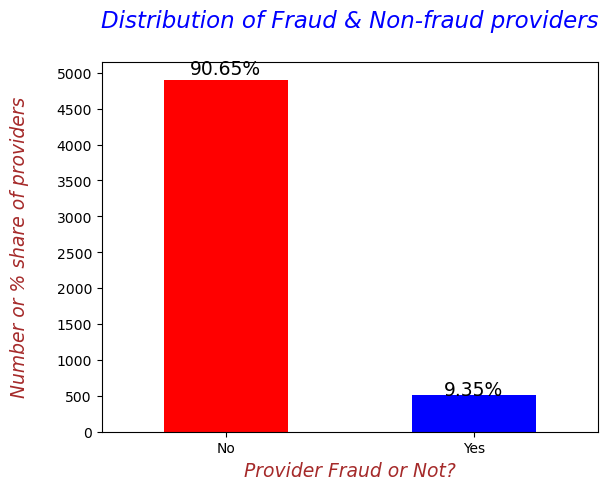

In [6]:
fig = tgt_train_df["PotentialFraud"].value_counts().plot(kind='bar', color=['red','blue'])
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tgt_train_df.shape[0],2))+"%"}', (x + width/2, y + height*1.015), ha='center', fontsize=13.5)
plt.xlabel("Provider Fraud or Not?", fontdict=label_font_dict)
plt.xticks(rotation = 0)
plt.ylabel("Number or % share of providers\n", fontdict=label_font_dict)
plt.yticks(np.arange(0,5100,500))
plt.title("Distribution of Fraud & Non-fraud providers\n", fontdict=title_font_dict)
plt.show();

**`OBSERVATION`**
* From the above plot, we can say that 90% of the providers are not frausters and only 9% of them are involved in frauds.

### **Adding the `Admitted` or `Not Admitted` indicator in IP and OP Dataset**

* **Adding in IP Dataset**

In [7]:
ip_train_df["Admitted?"] = 1

In [8]:
ip_train_df.head()

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,AdmissionDt,ClmAdmitDiagnosisCode,DeductibleAmtPaid,DischargeDt,DiagnosisGroupCode,ClmDiagnosisCode_1,...,ClmDiagnosisCode_3,ClmDiagnosisCode_4,ClmDiagnosisCode_5,ClmDiagnosisCode_6,ClmDiagnosisCode_7,ClmDiagnosisCode_8,ClmDiagnosisCode_9,ClmDiagnosisCode_10,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6,Admitted?
0,BENE11001,CLM46614,2009-04-12,2009-04-18,PRV55912,26000,PHY390922,NaN,NaN,2009-04-12,7866,1068.0,2009-04-18,201,1970,...,5853,7843,2768,71590,2724,19889,5849,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,BENE11001,CLM66048,2009-08-31,2009-09-02,PRV55907,5000,PHY318495,PHY318495,NaN,2009-08-31,6186,1068.0,2009-09-02,750,6186,...,56400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7092.0,NaN,NaN,NaN,NaN,NaN,1
2,BENE11001,CLM68358,2009-09-17,2009-09-20,PRV56046,5000,PHY372395,NaN,PHY324689,2009-09-17,29590,1068.0,2009-09-20,883,29623,...,71690,34590,V1581,32723,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
3,BENE11011,CLM38412,2009-02-14,2009-02-22,PRV52405,5000,PHY369659,PHY392961,PHY349768,2009-02-14,431,1068.0,2009-02-22,067,43491,...,7843,32723,V1041,4254,25062,40390,4019,NaN,331.0,NaN,NaN,NaN,NaN,NaN,1
4,BENE11014,CLM63689,2009-08-13,2009-08-30,PRV56614,10000,PHY379376,PHY398258,NaN,2009-08-13,78321,1068.0,2009-08-30,975,042,...,34400,5856,42732,486,5119,29620,20300,NaN,3893.0,NaN,NaN,NaN,NaN,NaN,1


* **Adding in OP Dataset**

In [9]:
op_train_df["Admitted?"] = 0

In [10]:
op_train_df.head()

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,ClmDiagnosisCode_1,ClmDiagnosisCode_2,ClmDiagnosisCode_3,ClmDiagnosisCode_4,ClmDiagnosisCode_5,ClmDiagnosisCode_6,ClmDiagnosisCode_7,ClmDiagnosisCode_8,ClmDiagnosisCode_9,ClmDiagnosisCode_10,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6,DeductibleAmtPaid,ClmAdmitDiagnosisCode,Admitted?
0,BENE11002,CLM624349,2009-10-11,2009-10-11,PRV56011,30,PHY326117,NaN,NaN,78943,V5866,V1272,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,56409,0
1,BENE11003,CLM189947,2009-02-12,2009-02-12,PRV57610,80,PHY362868,NaN,NaN,6115,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,79380,0
2,BENE11003,CLM438021,2009-06-27,2009-06-27,PRV57595,10,PHY328821,NaN,NaN,2723,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0
3,BENE11004,CLM121801,2009-01-06,2009-01-06,PRV56011,40,PHY334319,NaN,NaN,71988,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,0
4,BENE11004,CLM150998,2009-01-22,2009-01-22,PRV56011,200,PHY403831,NaN,NaN,82382,30000,72887,4280,7197,V4577,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,71947,0


### **Merging the Datasets**

In [11]:
# Commom columns must be 28
common_cols = [col for col in ip_train_df.columns if col in op_train_df.columns]
len(common_cols)

28

In [12]:
# Merging the IP and OP dataset on the basis of common columns
train_ip_op_df = pd.merge(left=ip_train_df, right=op_train_df, left_on=common_cols, right_on=common_cols, how="outer")
train_ip_op_df.shape

(558211, 31)

In [13]:
train_ip_op_df.head()

,BeneID,ClaimID,ClaimStartDt,ClaimEndDt,Provider,InscClaimAmtReimbursed,AttendingPhysician,OperatingPhysician,OtherPhysician,AdmissionDt,ClmAdmitDiagnosisCode,DeductibleAmtPaid,DischargeDt,DiagnosisGroupCode,ClmDiagnosisCode_1,...,ClmDiagnosisCode_3,ClmDiagnosisCode_4,ClmDiagnosisCode_5,ClmDiagnosisCode_6,ClmDiagnosisCode_7,ClmDiagnosisCode_8,ClmDiagnosisCode_9,ClmDiagnosisCode_10,ClmProcedureCode_1,ClmProcedureCode_2,ClmProcedureCode_3,ClmProcedureCode_4,ClmProcedureCode_5,ClmProcedureCode_6,Admitted?
0,BENE11001,CLM46614,2009-04-12,2009-04-18,PRV55912,26000,PHY390922,NaN,NaN,2009-04-12,7866,1068.0,2009-04-18,201,1970,...,5853,7843,2768,71590,2724,19889,5849,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,BENE11001,CLM66048,2009-08-31,2009-09-02,PRV55907,5000,PHY318495,PHY318495,NaN,2009-08-31,6186,1068.0,2009-09-02,750,6186,...,56400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7092.0,NaN,NaN,NaN,NaN,NaN,1
2,BENE11001,CLM68358,2009-09-17,2009-09-20,PRV56046,5000,PHY372395,NaN,PHY324689,2009-09-17,29590,1068.0,2009-09-20,883,29623,...,71690,34590,V1581,32723,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
3,BENE11011,CLM38412,2009-02-14,2009-02-22,PRV52405,5000,PHY369659,PHY392961,PHY349768,2009-02-14,431,1068.0,2009-02-22,067,43491,...,7843,32723,V1041,4254,25062,40390,4019,NaN,331.0,NaN,NaN,NaN,NaN,NaN,1
4,BENE11014,CLM63689,2009-08-13,2009-08-30,PRV56614,10000,PHY379376,PHY398258,NaN,2009-08-13,78321,1068.0,2009-08-30,975,042,...,34400,5856,42732,486,5119,29620,20300,NaN,3893.0,NaN,NaN,NaN,NaN,NaN,1


### **Merging the IP_OP Dataset with BENE Data**

In [14]:
# Joining the IP_OP dataset with the BENE data
train_ip_op_bene_df = pd.merge(left=train_ip_op_df, right=bene_train_df, left_on='BeneID', right_on='BeneID',how='inner')
train_ip_op_bene_df.shape

(558211, 55)

### **Merging the IP_OP_BENE Dataset with PROVIDER level Tgt Labels Data**

In [15]:
# Joining the IP_OP_BENE dataset with the Tgt Label Provider Data
train_iobp_df = pd.merge(left=train_ip_op_bene_df, right=tgt_train_df, left_on='Provider', right_on='Provider',how='inner')
train_iobp_df.shape

(558211, 56)

### **Entire Dataset**

In [16]:
train_iobp_df.shape

(558211, 56)

In [17]:
# Unique Providers
train_iobp_df["Provider"].nunique()

5410

In [18]:
# Unique Claim numbers
train_iobp_df["ClaimID"].nunique()

558211

### *`ASSUMPTION`* :: One provider may have been involved in more than one claim. So, does all the claims filed by a potentially fraud provider are all frauds?
    - This cannot holds True for all the providers because if one provider has filed say 50 claims then we can't say that all the claims for that provider are fraudulent. 
        - There may exists a pattern that out of 50 claims a provider files 1 or 2 fraudulent claims. 
    
#### **`Therefore, it is a big assumption to make that all the claims filed by a potentially fraud provider are fraudulent.`**

In [19]:
prvs_claims_df = pd.DataFrame(train_iobp_df.groupby(['Provider'])['ClaimID'].count()).reset_index()
prvs_claims_tgt_lbls_df = pd.merge(left=prvs_claims_df, right=tgt_train_df, on='Provider', how='inner')
prvs_claims_tgt_lbls_df

,Provider,ClaimID,PotentialFraud
0,PRV51001,25,No
1,PRV51003,132,Yes
2,PRV51004,149,No
3,PRV51005,1165,Yes
4,PRV51007,72,No
...,...,...,...
5405,PRV57759,28,No
5406,PRV57760,22,No
5407,PRV57761,82,No
5408,PRV57762,1,No


**`OBSERVATION`**
* As shown in the above table, PRV51005 has filed 1165 claims so after joining the datasets all of these will be marked as Fraud.

- **Fraud Count at Claims level**

     PotentialFraud
No           345415
Yes          212796 



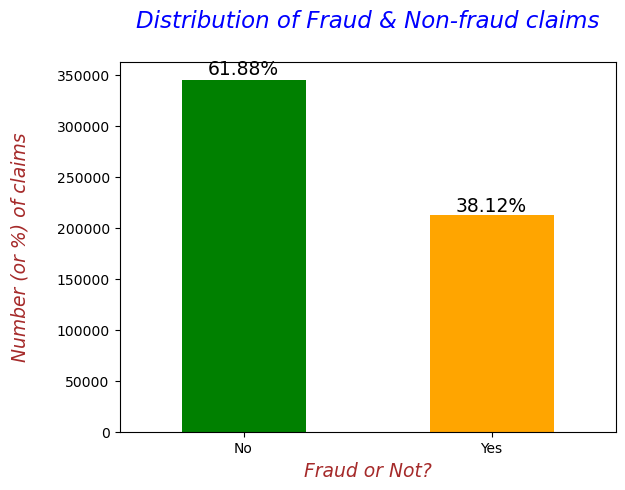

In [20]:
print(pd.DataFrame(train_iobp_df['PotentialFraud'].value_counts()), "\n")

fig = train_iobp_df['PotentialFraud'].value_counts().plot(kind='bar', color=['green','orange'])
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/train_iobp_df.shape[0],2))+"%"}', (x + width/2, y + height*1.015), ha='center', fontsize=13.5)
plt.xlabel("Fraud or Not?", fontdict=label_font_dict)
plt.xticks(rotation = 0)
plt.ylabel("Number (or %) of claims\n", fontdict=label_font_dict)
plt.title("Distribution of Fraud & Non-fraud claims\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot shows us that, 62% of claims are Non-Fraud and 32% of them are Fraudulent. 
    * By looking at the percentages we may say that there is a class-imbalance problem but after looking at the number of records it doesn't seem to be a severe class-imbalance problem. 
        * So, I'll try some class balancing techniques only after training a baseline model w/o any synthetic or class weighting techniques.

# **Feature Engineering + Impact Analysis**
**`Let's create some features`**

### **Adding `New Feature` :: `Is_Alive?`**

    - Is Alive? = No if DOD is NaN else Yes

In [21]:
train_iobp_df['DOB'] = pd.to_datetime(train_iobp_df['DOB'], format="%Y-%m-%d")
train_iobp_df['DOD'] = pd.to_datetime(train_iobp_df['DOD'], format="%Y-%m-%d")

In [22]:
train_iobp_df['Is_Alive?'] = train_iobp_df['DOD'].apply(lambda val: 'No' if val != val else 'Yes')

In [23]:
train_iobp_df['Is_Alive?'].value_counts()

No     554080
Yes      4131
Name: Is_Alive?, dtype: int64

### **Adding `New Feature` :: `Claim_Duration`**
    
    - Claim Duration = Claim End Date - Claim Start Date

In [24]:
train_iobp_df['ClaimStartDt'] = pd.to_datetime(train_iobp_df['ClaimStartDt'], format="%Y-%m-%d")
train_iobp_df['ClaimEndDt'] = pd.to_datetime(train_iobp_df['ClaimEndDt'], format="%Y-%m-%d")

train_iobp_df['Claim_Duration'] = (train_iobp_df['ClaimEndDt'] - train_iobp_df['ClaimStartDt']).dt.days

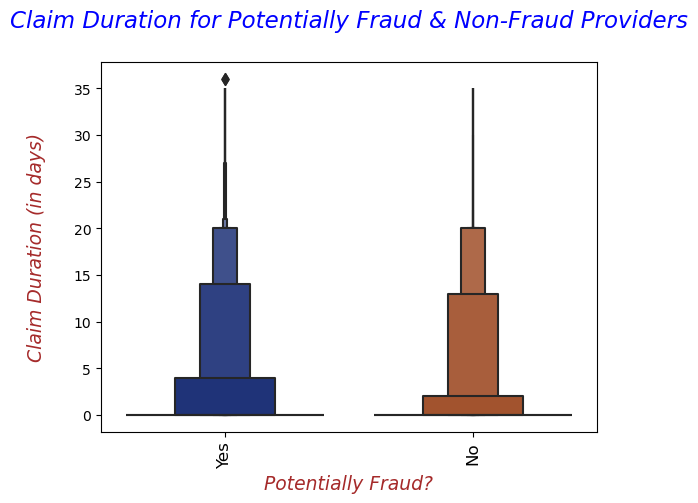

In [25]:
fig = sns.boxenplot(data=train_iobp_df, x='PotentialFraud',y='Claim_Duration', palette='dark')
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=90, fontsize=12)
plt.ylabel("Claim Duration (in days)\n", fontdict=label_font_dict)
plt.title("Claim Duration for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Claim Duration for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Claim Duration alone might not be useful in segregating the Fraud cases.

- **Relationship b/w `Claim_Duration` and `Potentially Fraud` for both the `Genders`**

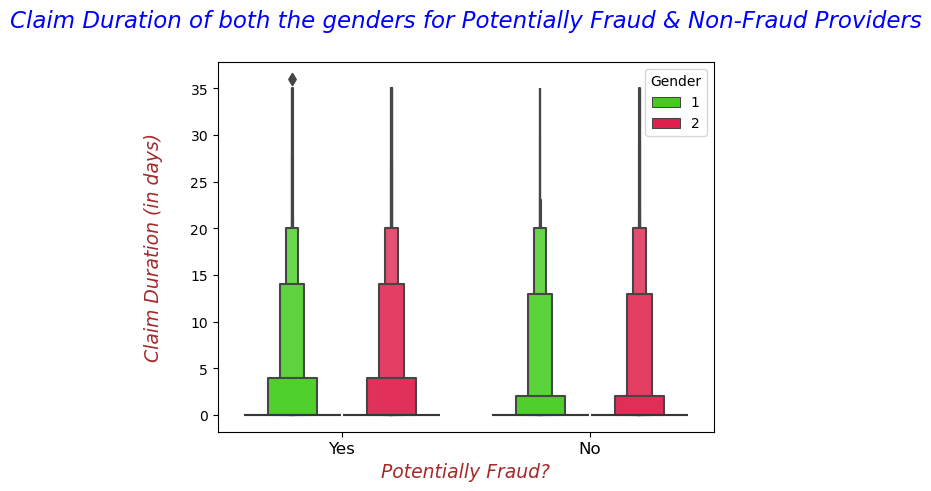

In [26]:
fig = sns.boxenplot(data=train_iobp_df, x='PotentialFraud',y='Claim_Duration', hue='Gender', palette='prism')      
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Claim Duration (in days)\n", fontdict=label_font_dict)
plt.title("Claim Duration of both the genders for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Claim Duration of males and females for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Claim Duration might not be useful in segregating the Fraud cases.

- **Relationship b/w `Claim_Duration` and `Potentially Fraud` for `Is_Alive?`**

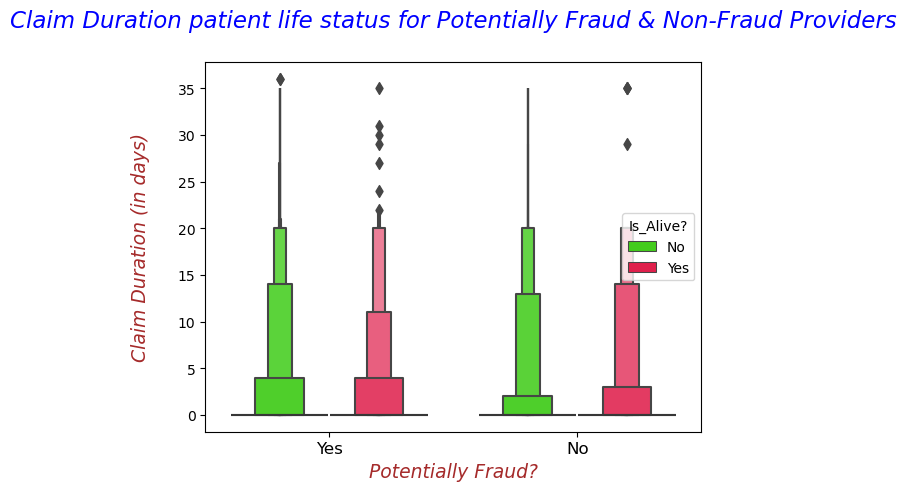

In [27]:
fig = sns.boxenplot(data=train_iobp_df, x='PotentialFraud',y='Claim_Duration', hue='Is_Alive?', palette='prism')      
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Claim Duration (in days)\n", fontdict=label_font_dict)
plt.title("Claim Duration patient life status for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Claim Duration on patient life status for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Claim Duration might not be useful in segregating the Fraud cases.

- **Relationship b/w `Claim_Duration` and `Potentially Fraud` for all `Human Races`**

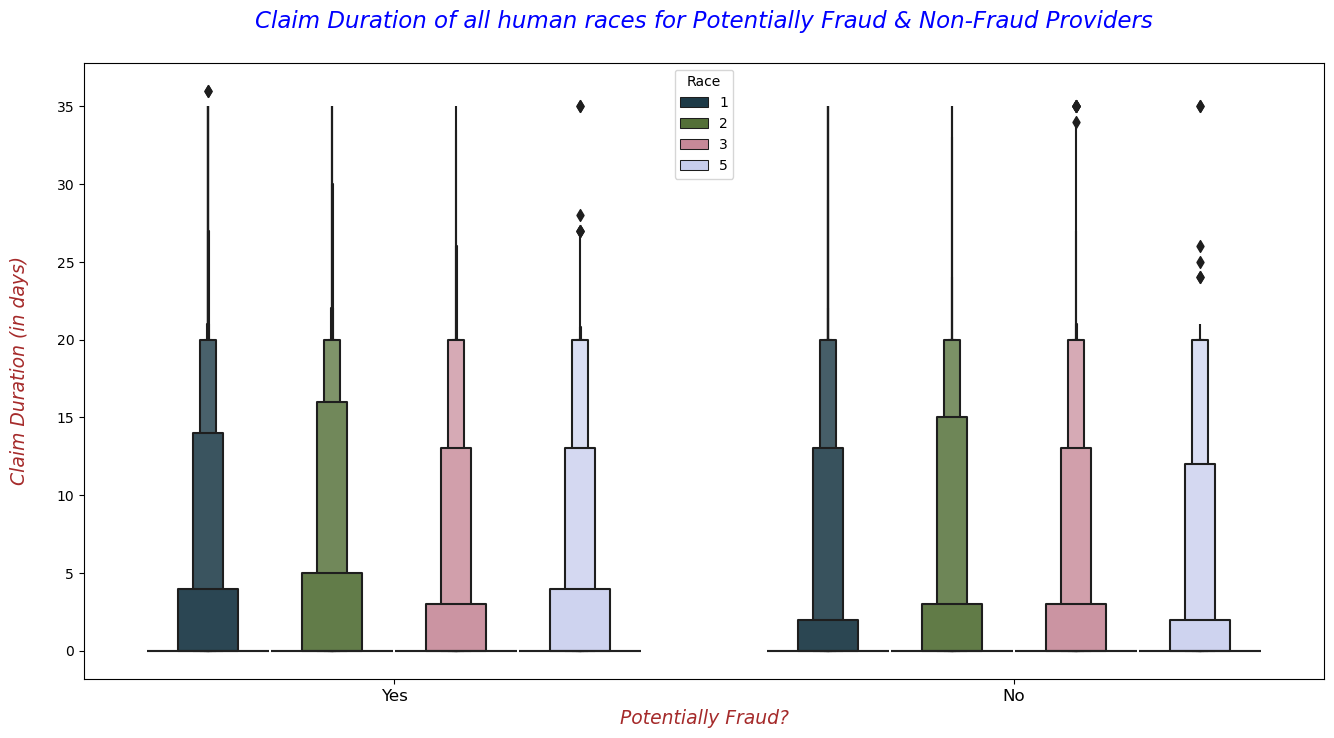

In [28]:
plt.figure(figsize=(16,8))
fig = sns.boxenplot(data=train_iobp_df, x='PotentialFraud',y='Claim_Duration', hue='Race', palette='cubehelix')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Claim Duration (in days)\n", fontdict=label_font_dict)
plt.title("Claim Duration of all human races for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.legend(loc='upper center',title='Race')
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Claim Duration of all human races for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Claim Duration might not be useful in segregating the Fraud cases.

- **Relationship b/w `Claim_Duration` and `Potentially Fraud` for `RenalDiseaseIndicator`**

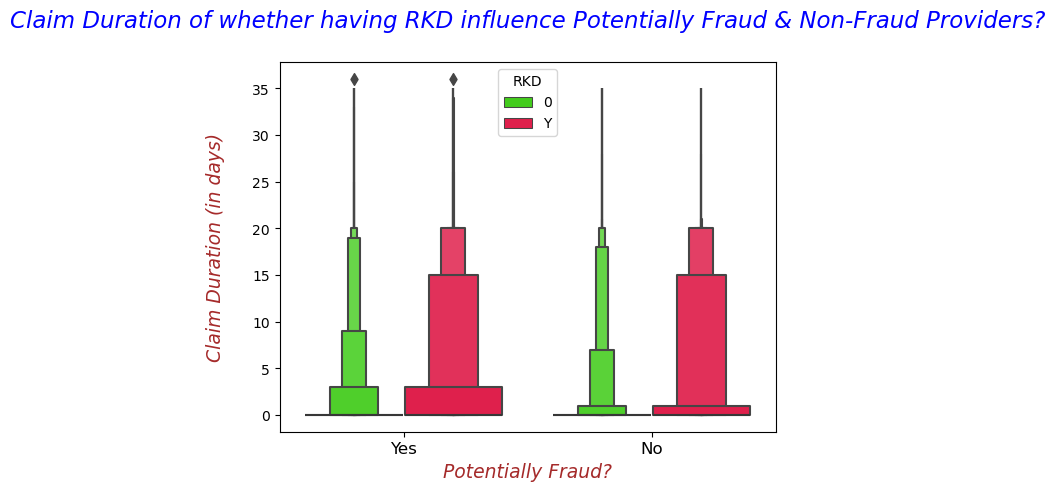

In [29]:
fig = sns.boxenplot(data=train_iobp_df, x='PotentialFraud',y='Claim_Duration', hue='RenalDiseaseIndicator', palette='prism')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Claim Duration (in days)\n", fontdict=label_font_dict)
plt.title("Claim Duration of whether having RKD influence Potentially Fraud & Non-Fraud Providers?\n", fontdict=title_font_dict)
plt.legend(loc="upper center", title='RKD')
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Claim Duration of patients with or w/o RKD for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Claim Duration might not be useful in segregating the Fraud cases.

### **Adding `New Feature` :: `Admitted_Duration`**

    - Admitted Duration = Discharge Date - Admission Date

In [30]:
train_iobp_df['AdmissionDt'] = pd.to_datetime(train_iobp_df['AdmissionDt'], format="%Y-%m-%d")
train_iobp_df['DischargeDt'] = pd.to_datetime(train_iobp_df['DischargeDt'], format="%Y-%m-%d")

train_iobp_df['Admitted_Duration'] = (train_iobp_df['DischargeDt'] - train_iobp_df['AdmissionDt']).dt.days

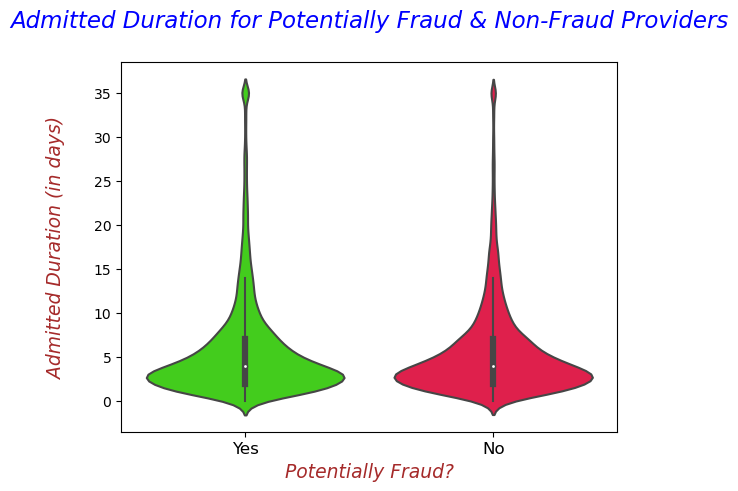

In [31]:
fig = sns.violinplot(data=train_iobp_df, x='PotentialFraud',y='Admitted_Duration', palette='prism')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Admitted Duration (in days)\n", fontdict=label_font_dict)
plt.title("Admitted Duration for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Admit Duration for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Admit Duration alone might not be useful in segregating the Fraud cases.

- **Relationship b/w `Admit_Duration` and `Potentially Fraud` for both the `Genders`**

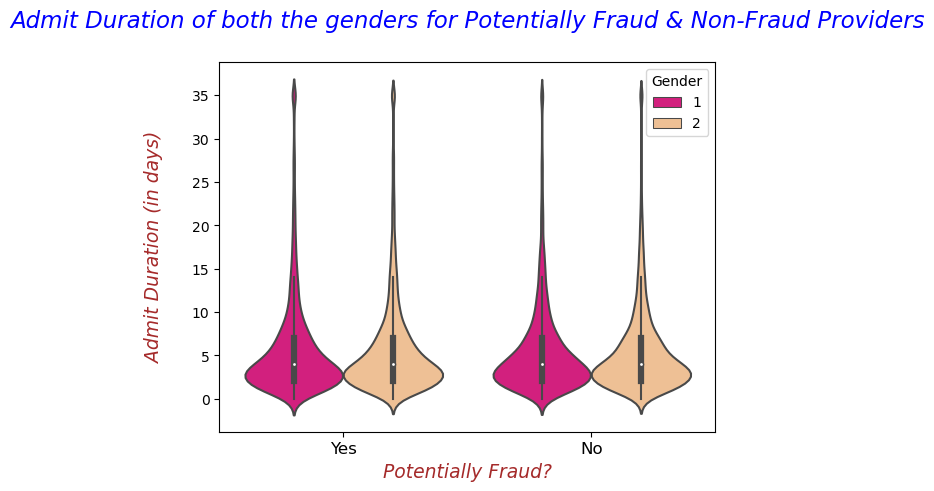

In [32]:
fig = sns.violinplot(data=train_iobp_df, x='PotentialFraud',y='Admitted_Duration', hue='Gender', palette='Accent_r')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Admit Duration (in days)\n", fontdict=label_font_dict)
plt.title("Admit Duration of both the genders for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Admit Duration of males and females for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Admit Duration might not be useful in segregating the Fraud cases.

- **Relationship b/w `Admitted_Duration` and `Potentially Fraud` for `Is_Alive?`**

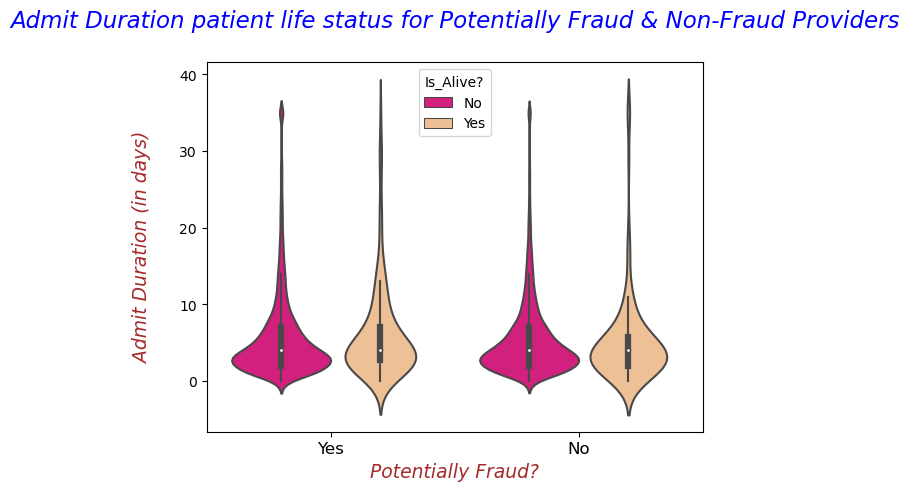

In [33]:
fig = sns.violinplot(data=train_iobp_df, x='PotentialFraud',y='Admitted_Duration', hue='Is_Alive?', palette='Accent_r')      
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Admit Duration (in days)\n", fontdict=label_font_dict)
plt.title("Admit Duration patient life status for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.legend(loc="upper center", title='Is_Alive?')
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Admit Duration on patient life status for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Admit Duration might not be useful in segregating the Fraud cases.

- **Relationship b/w `Admit_Duration` and `Potentially Fraud` for all `Human Races`**

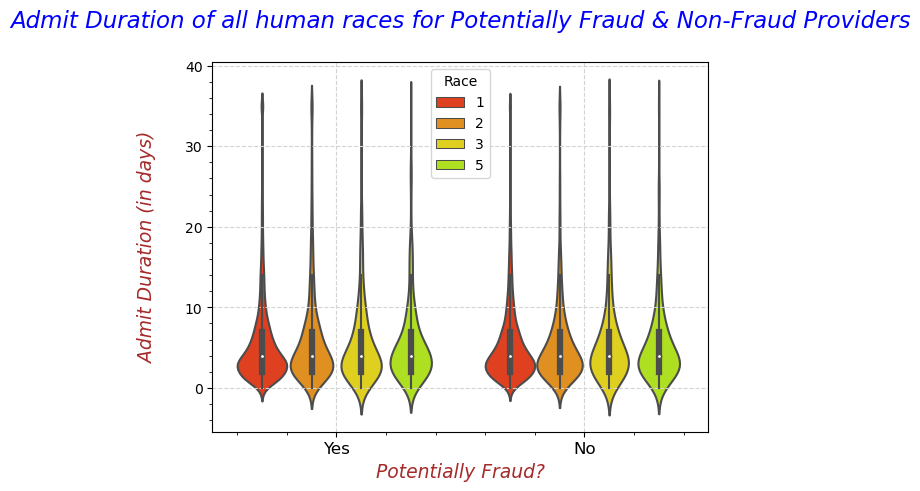

In [34]:
fig = sns.violinplot(data=train_iobp_df, x='PotentialFraud',y='Admitted_Duration', hue='Race', palette='prism')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Admit Duration (in days)\n", fontdict=label_font_dict)
plt.minorticks_on()
plt.grid(which='major', linestyle="--", color='lightgrey')
plt.title("Admit Duration of all human races for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.legend(loc="upper center", title="Race")
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Admit Duration of all human races for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Admit Duration might not be useful in segregating the Fraud cases.

- **Relationship b/w `Admitted_Duration` and `Potentially Fraud` for `RenalDiseaseIndicator`**

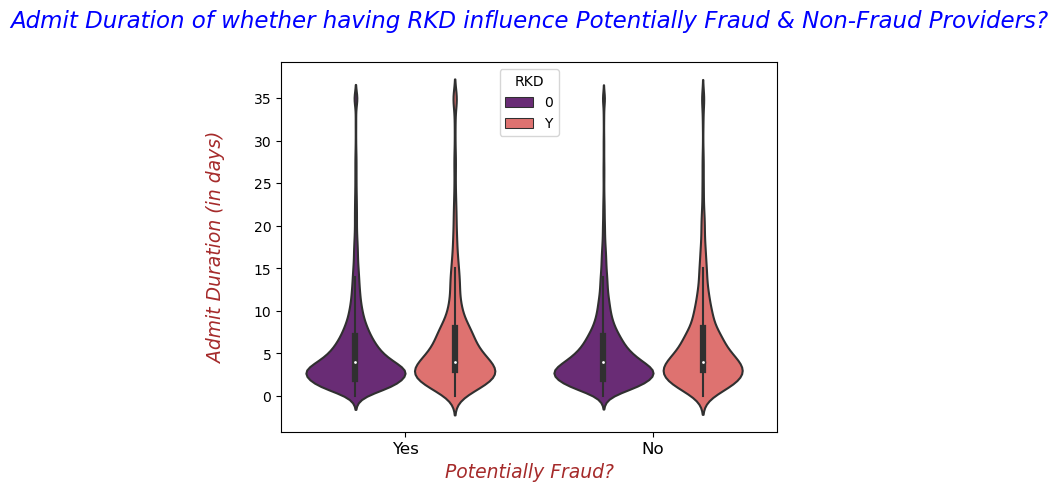

In [35]:
fig = sns.violinplot(data=train_iobp_df, x='PotentialFraud',y='Admitted_Duration', hue='RenalDiseaseIndicator',palette='magma')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Admit Duration (in days)\n", fontdict=label_font_dict)
plt.title("Admit Duration of whether having RKD influence Potentially Fraud & Non-Fraud Providers?\n", fontdict=title_font_dict)
plt.legend(loc="upper center", title="RKD")
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Admit Duration of patients with or w/o RKD for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Admit Duration might not be useful in segregating the Fraud cases.

### **Adding `New Feature` :: `Bene_Age`**

    - Bene Age = DOD - DOB (if DOD is Null then replace it with MAX date in DOD)

In [36]:
# Filling the Null values as MAX Date of Death in the Dataset
train_iobp_df['DOD'].fillna(value=train_iobp_df['DOD'].max(), inplace=True)

In [37]:
train_iobp_df['Bene_Age'] = round(((train_iobp_df['DOD'] - train_iobp_df['DOB']).dt.days)/365,1)

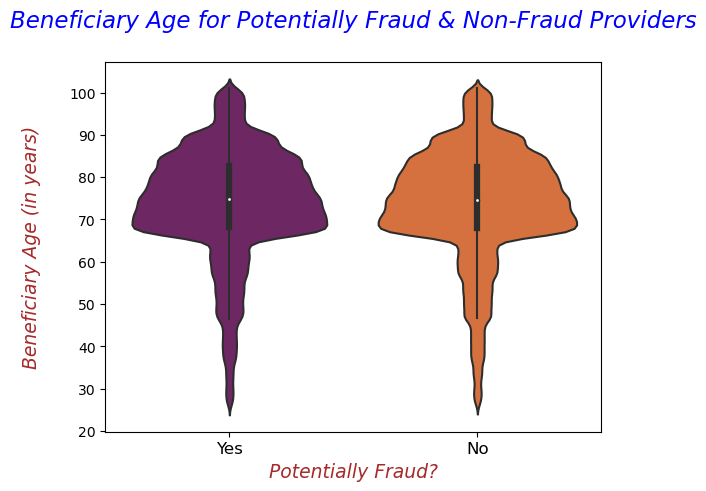

In [38]:
fig = sns.violinplot(data=train_iobp_df, x='PotentialFraud',y='Bene_Age', palette='inferno')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Beneficiary Age (in years)\n", fontdict=label_font_dict)
plt.title("Beneficiary Age for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Beneficiary Age for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Beneficiary Age alone might not be useful in segregating the Fraud cases.

- **Relationship b/w `Bene_Age` and `Potentially Fraud` for both the `Genders`**

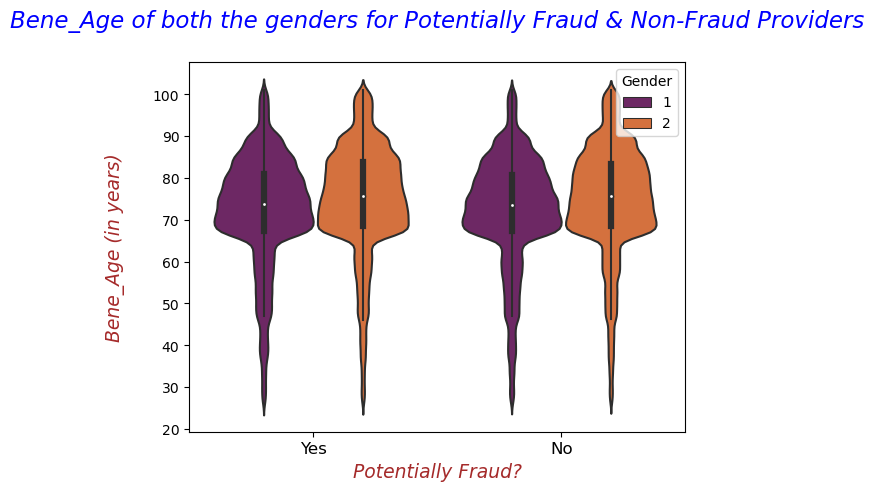

In [39]:
fig = sns.violinplot(data=train_iobp_df, x='PotentialFraud',y='Bene_Age', hue='Gender', palette='inferno')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Bene_Age (in years)\n", fontdict=label_font_dict)
plt.title("Bene_Age of both the genders for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Bene_Age of males and females for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Bene_Age might not be useful in segregating the Fraud cases.

- **Relationship b/w `Bene_Age` and `Potentially Fraud` for `Is_Alive?`**

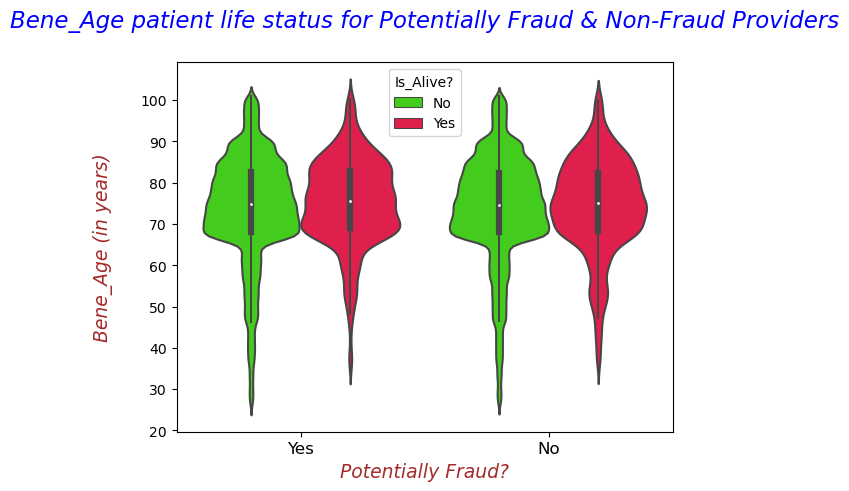

In [40]:
fig = sns.violinplot(data=train_iobp_df, x='PotentialFraud',y='Bene_Age', hue='Is_Alive?', palette='prism')      
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Bene_Age (in years)\n", fontdict=label_font_dict)
plt.title("Bene_Age patient life status for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.legend(loc="upper center", title='Is_Alive?')
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Bene_Age on patient life status for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Bene_Age might not be useful in segregating the Fraud cases.

- **Relationship b/w `Bene_Age` and `Potentially Fraud` for all `Human Races`**

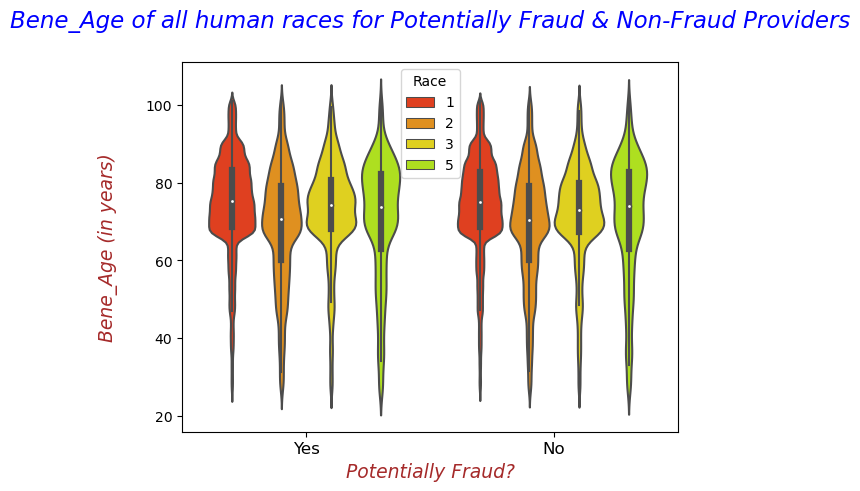

In [41]:
fig = sns.violinplot(data=train_iobp_df, x='PotentialFraud',y='Bene_Age', hue='Race', palette='prism')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Bene_Age (in years)\n", fontdict=label_font_dict)
plt.title("Bene_Age of all human races for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.legend(loc="upper center", title="Race")
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Bene_Age of all human races for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Bene_Age might not be useful in segregating the Fraud cases.

- **Relationship b/w `Bene_Age` and `Potentially Fraud` for `RenalDiseaseIndicator`**

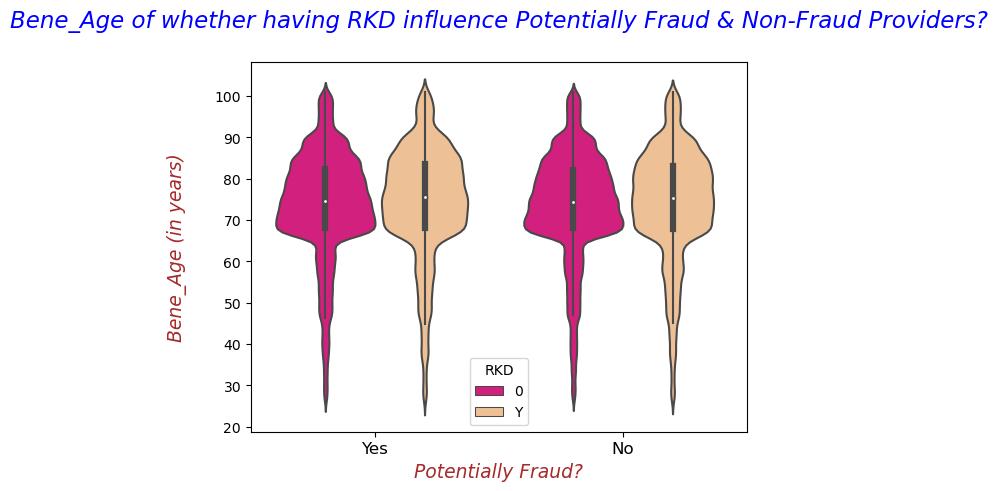

In [42]:
fig = sns.violinplot(data=train_iobp_df, x='PotentialFraud',y='Bene_Age', hue='RenalDiseaseIndicator',palette='Accent_r')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Bene_Age (in years)\n", fontdict=label_font_dict)
plt.title("Bene_Age of whether having RKD influence Potentially Fraud & Non-Fraud Providers?\n", fontdict=title_font_dict)
plt.legend(loc='lower center', title='RKD')
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Bene_Age of patients with or w/o RKD for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Bene_Age might not be useful in segregating the Fraud cases.

### **Does `InscClaimAmtReimbursed` influences `Potentially Fraud`?**
   - **Relationship b/w `InscClaimAmtReimbursed` and `Potentially Fraud`**

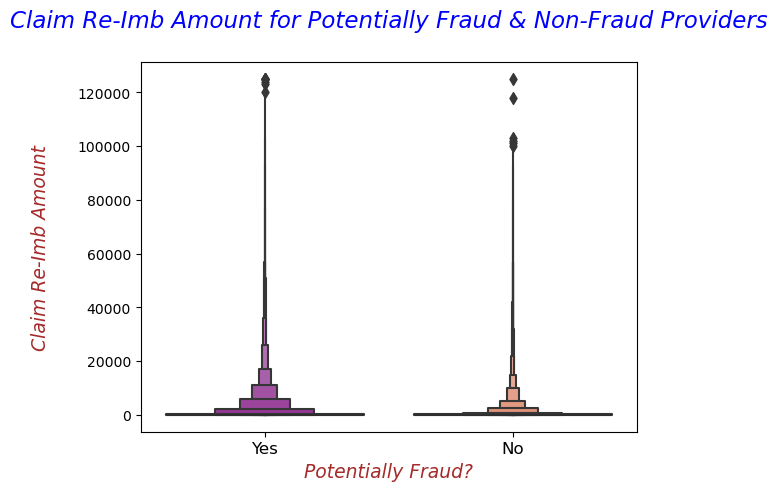

In [43]:
fig = sns.boxenplot(data=train_iobp_df, x='PotentialFraud',y='InscClaimAmtReimbursed', palette='plasma') 
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Claim Re-Imb Amount\n", fontdict=label_font_dict)
plt.title("Claim Re-Imb Amount for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Claim Re-Imb Amount for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Claim Re-Imb Amount alone might not be useful in segregating the Fraud cases.

- **Relationship b/w `InscClaimAmtReimbursed` and `Potentially Fraud` for both the `Genders`**

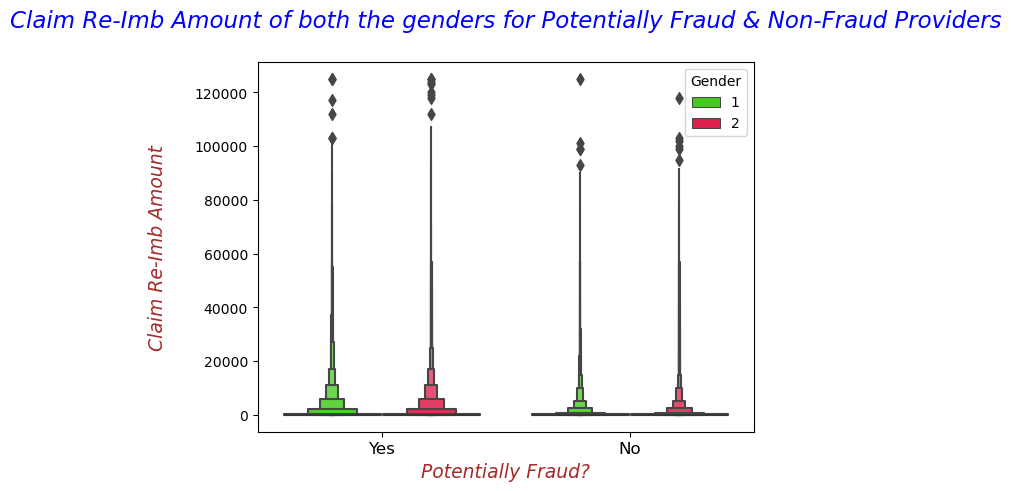

In [44]:
fig = sns.boxenplot(data=train_iobp_df, x='PotentialFraud',y='InscClaimAmtReimbursed', hue='Gender', palette='prism')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Claim Re-Imb Amount\n", fontdict=label_font_dict)
plt.title("Claim Re-Imb Amount of both the genders for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Claim Re-Imb Amount of males and females for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Claim Re-Imb Amount might not be useful in segregating the Fraud cases.

- **Relationship b/w `InscClaimAmtReimbursed` and `Potentially Fraud` for `Is_Alive?`**

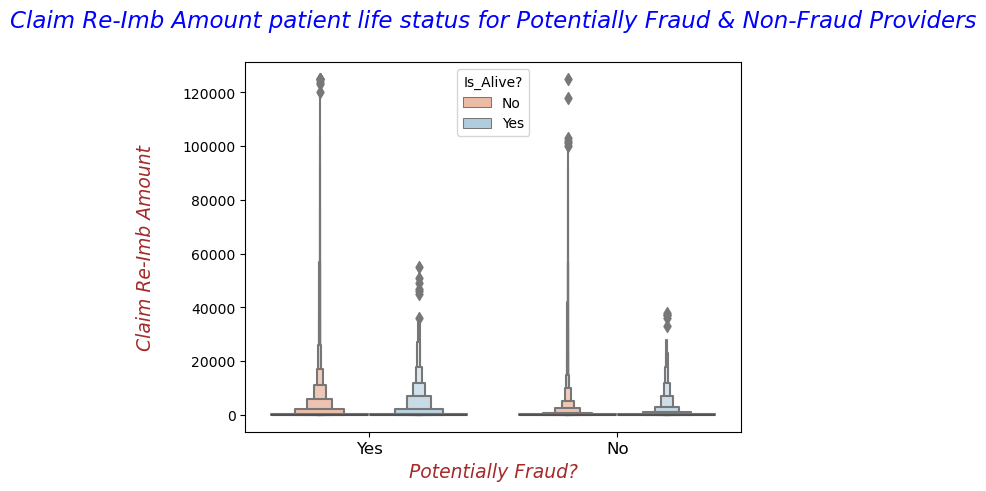

In [45]:
fig = sns.boxenplot(data=train_iobp_df, x='PotentialFraud',y='InscClaimAmtReimbursed', hue='Is_Alive?', palette='RdBu')      
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Claim Re-Imb Amount\n", fontdict=label_font_dict)
plt.title("Claim Re-Imb Amount patient life status for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.legend(loc="upper center", title='Is_Alive?')
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Claim Re-Imb Amount on patient life status for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Claim Re-Imb Amount might not be useful in segregating the Fraud cases.

- **Relationship b/w `InscClaimAmtReimbursed` and `Potentially Fraud` for all `Human Races`**

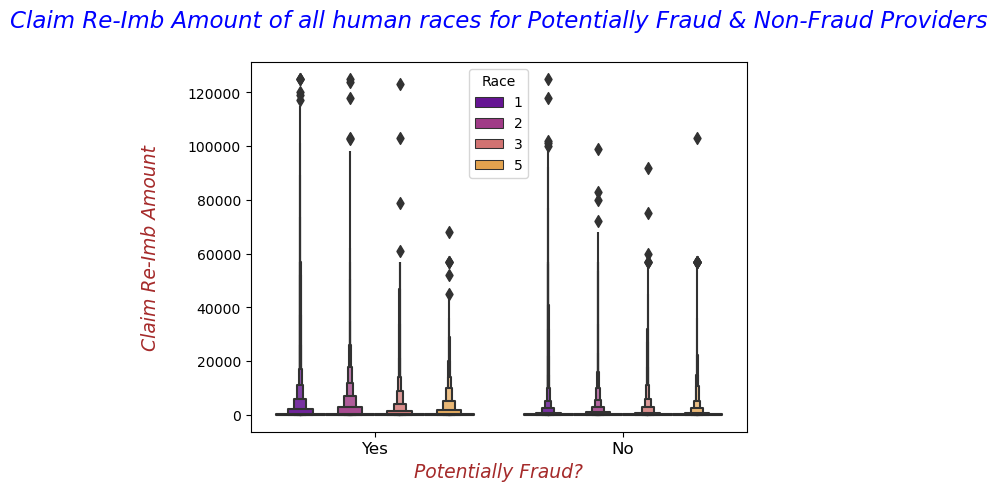

In [46]:
fig = sns.boxenplot(data=train_iobp_df, x='PotentialFraud',y='InscClaimAmtReimbursed', hue='Race', palette='plasma')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Claim Re-Imb Amount\n", fontdict=label_font_dict)
plt.title("Claim Re-Imb Amount of all human races for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.legend(loc="upper center", title="Race")
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Claim Re-Imb Amount of all human races for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Claim Re-Imb Amount might not be useful in segregating the Fraud cases.

- **Relationship b/w `InscClaimAmtReimbursed` and `Potentially Fraud` for `RenalDiseaseIndicator`**

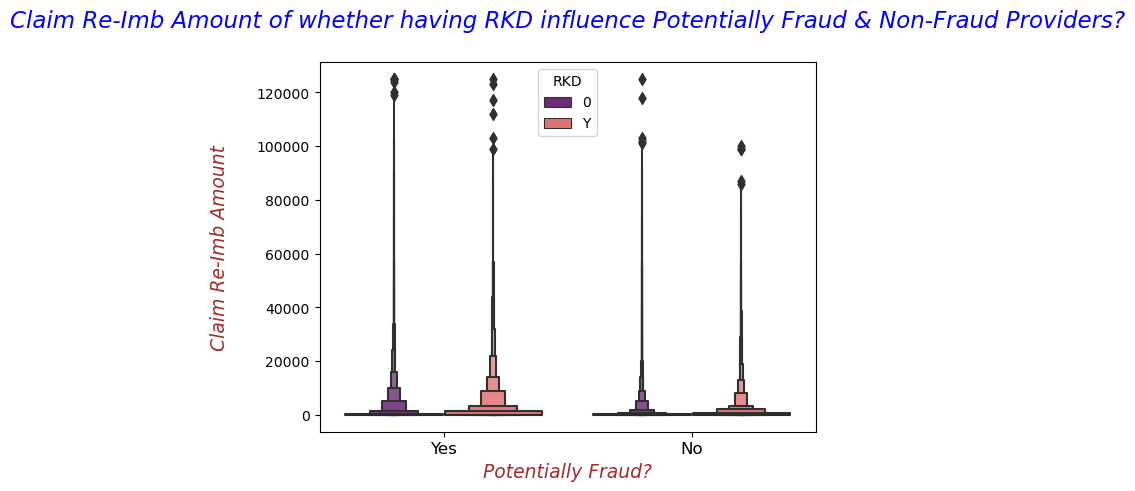

In [47]:
fig = sns.boxenplot(data=train_iobp_df, x='PotentialFraud',y='InscClaimAmtReimbursed', hue='RenalDiseaseIndicator',palette='magma')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Claim Re-Imb Amount\n", fontdict=label_font_dict)
plt.title("Claim Re-Imb Amount of whether having RKD influence Potentially Fraud & Non-Fraud Providers?\n", fontdict=title_font_dict)
plt.legend(loc='upper center', title='RKD')
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Claim Re-Imb Amount of patients with or w/o RKD for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that claim Re-Imb Amount might not be useful in segregating the Fraud cases.

### **Does `IPAnnualReimbursementAmt` influences `Potentially Fraud`?**
   - **Relationship b/w `IPAnnualReimbursementAmt` and `Potentially Fraud`**

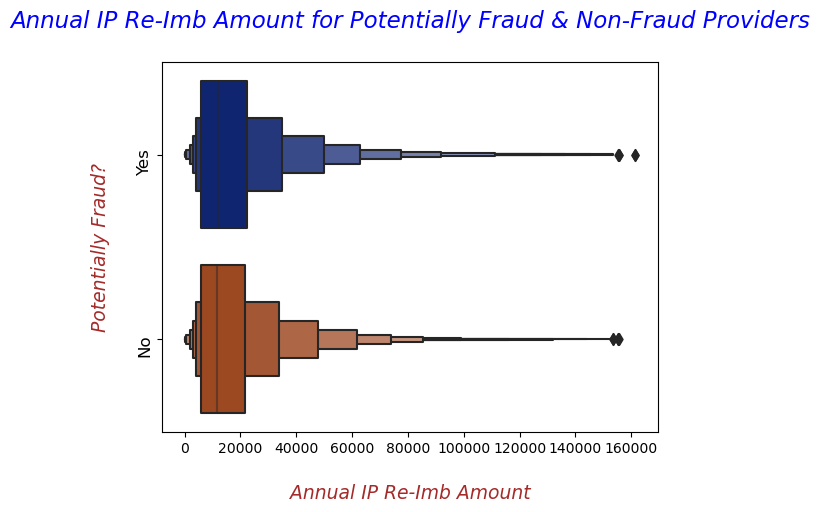

In [48]:
fig = sns.boxenplot(data=train_iobp_df[train_iobp_df['Admitted?'] == 1], y='PotentialFraud',x='IPAnnualReimbursementAmt', 
                         palette='dark', orient='h')   
plt.ylabel("Potentially Fraud?\n", fontdict=label_font_dict)
plt.yticks(rotation=90, fontsize=12)
plt.xlabel("\nAnnual IP Re-Imb Amount", fontdict=label_font_dict)
plt.title("Annual IP Re-Imb Amount for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Annual IP Re-Imb Amount for Potentially Fraud and Non-Fraud Providers.
    * And, it looks like a Pareto Distribution.

#### **Why do we have `IP Annual Re-Imb Amount` as `0` for `Admitted Patients`?**

In [49]:
print(pd.DataFrame(train_iobp_df[(train_iobp_df['IPAnnualReimbursementAmt'] == 0)]['Admitted?'].value_counts()))

   Admitted?
0     371263
1        413


- So, we have 413 claims where Patients were admitted to the hospital but the allocated `IP Annual Re-Imb Amt` is 0.

In [50]:
print(pd.DataFrame(train_iobp_df[(train_iobp_df['IPAnnualReimbursementAmt'] == 0) & (train_iobp_df['Admitted?'] == 1)]\
                   ['PotentialFraud'].value_counts()))

     PotentialFraud
Yes             249
No              164


- So, out 413 claims 60% of them means 249 are fraudulent whereas 164 are non-fraudulent.

**`OBSERVATION`**

- **Thus, we can say that if the IP Annual Amount is 0 and patient was admitted to the hospital then chances of being fraudulent are high.**

- **Relationship b/w `IPAnnualReimbursementAmt` and `Potentially Fraud` for both the `Genders`**

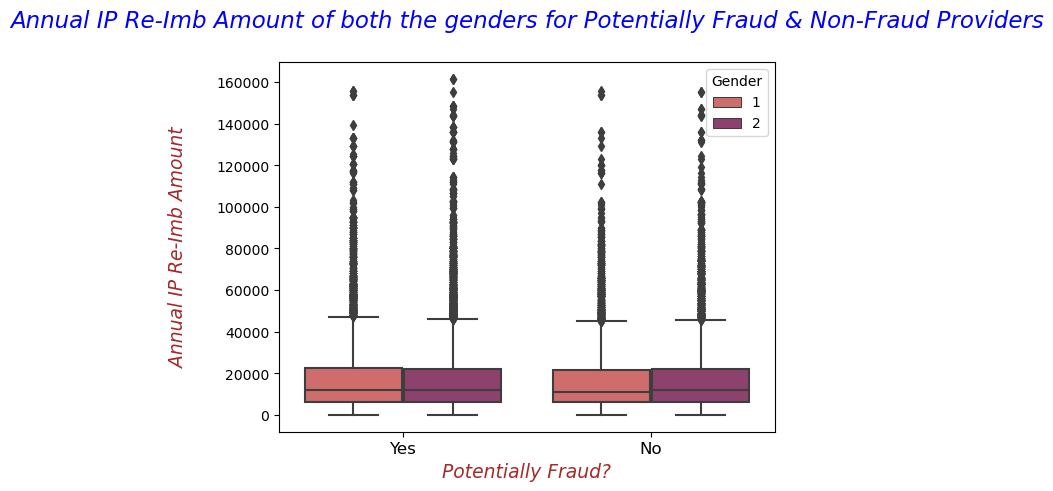

In [51]:
fig = sns.boxplot(data=train_iobp_df[train_iobp_df['Admitted?'] == 1], x='PotentialFraud',y='IPAnnualReimbursementAmt', hue='Gender',
                  palette='flare')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Annual IP Re-Imb Amount\n", fontdict=label_font_dict)
plt.title("Annual IP Re-Imb Amount of both the genders for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Annual IP Re-Imb Amount of males and females for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Annual IP Re-Imb Amount might not be useful in segregating the Fraud cases.

- **Relationship b/w `IPAnnualReimbursementAmt` and `Potentially Fraud` for `Is_Alive?`**

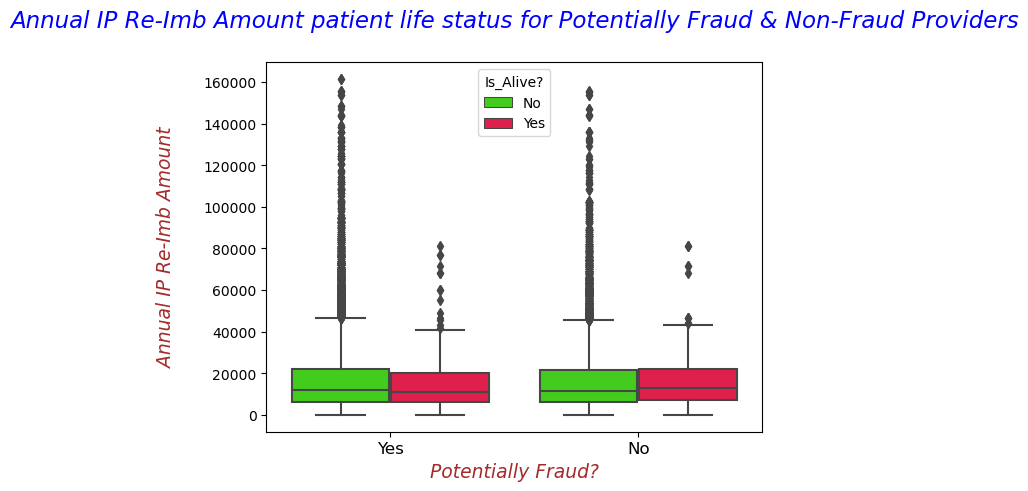

In [52]:
fig = sns.boxplot(data=train_iobp_df[train_iobp_df['Admitted?'] == 1], x='PotentialFraud',y='IPAnnualReimbursementAmt', hue='Is_Alive?',
                  palette='prism')      
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Annual IP Re-Imb Amount\n", fontdict=label_font_dict)
plt.title("Annual IP Re-Imb Amount patient life status for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.legend(loc="upper center", title='Is_Alive?')
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Annual IP Re-Imb Amount on patient life status for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Annual IP Re-Imb Amount might not be useful in segregating the Fraud cases.

- **Relationship b/w `IPAnnualReimbursementAmt` and `Potentially Fraud` for all `Human Races`**

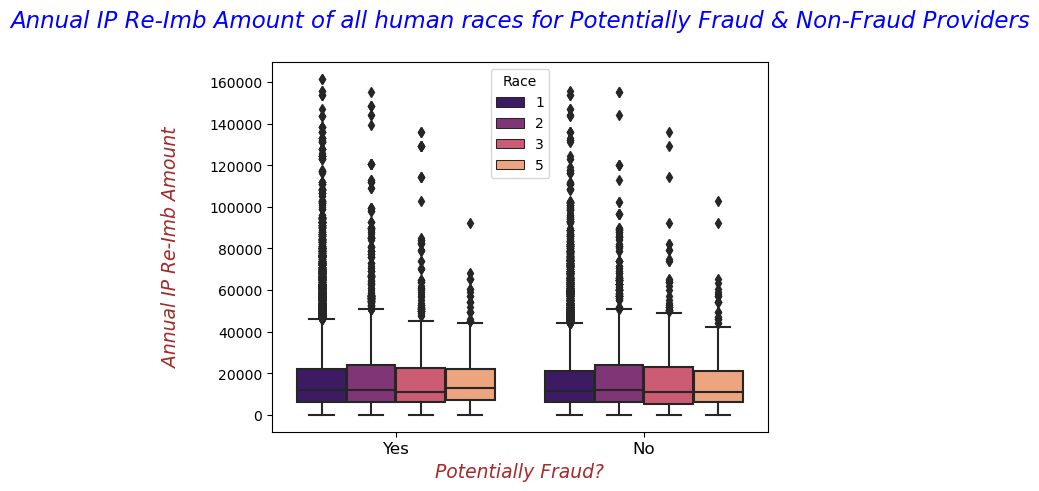

In [53]:
fig = sns.boxplot(data=train_iobp_df[train_iobp_df['Admitted?'] == 1], x='PotentialFraud',y='IPAnnualReimbursementAmt', hue='Race',
                  palette='magma')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Annual IP Re-Imb Amount\n", fontdict=label_font_dict)
plt.title("Annual IP Re-Imb Amount of all human races for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.legend(loc="upper center", title="Race")
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Annual IP Re-Imb Amount of all human races for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Annual IP Re-Imb Amount might not be useful in segregating the Fraud cases.

- **Relationship b/w `IPAnnualReimbursementAmt` and `Potentially Fraud` for `RenalDiseaseIndicator`**

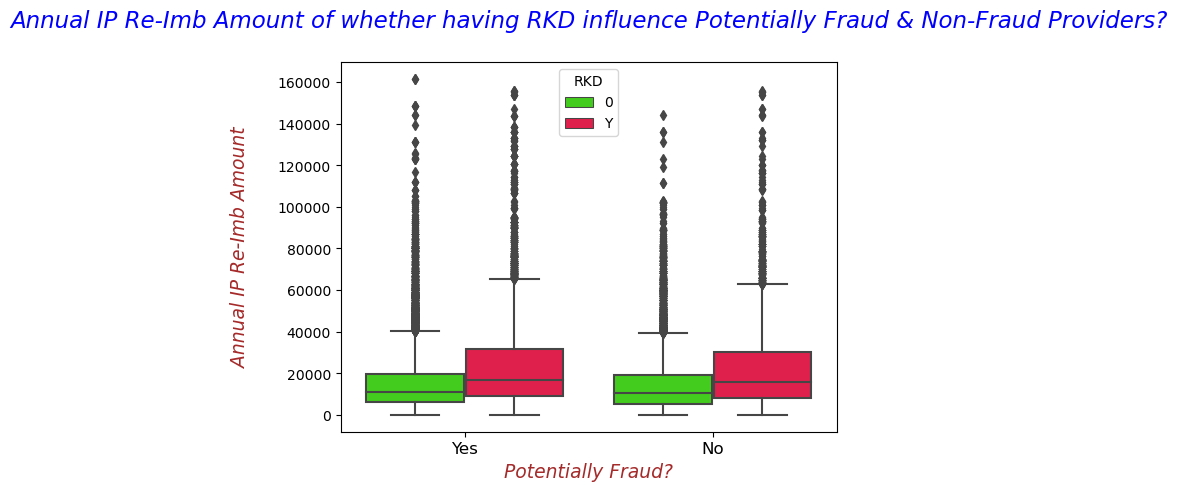

In [54]:
fig = sns.boxplot(data=train_iobp_df[train_iobp_df['Admitted?'] == 1], x='PotentialFraud',y='IPAnnualReimbursementAmt', 
                      hue='RenalDiseaseIndicator',palette='prism')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Annual IP Re-Imb Amount\n", fontdict=label_font_dict)
plt.title("Annual IP Re-Imb Amount of whether having RKD influence Potentially Fraud & Non-Fraud Providers?\n", fontdict=title_font_dict)
plt.legend(loc='upper center', title='RKD')
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is a very slight difference in the distribution of Annual IP Re-Imb Amount of patients with or w/o RKD for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Annual IP Re-Imb Amount might not be useful in segregating the Fraud cases.

### **Does `OPAnnualReimbursementAmt` influences `Potentially Fraud`?**
   - **Relationship b/w `OPAnnualReimbursementAmt` and `Potentially Fraud`**

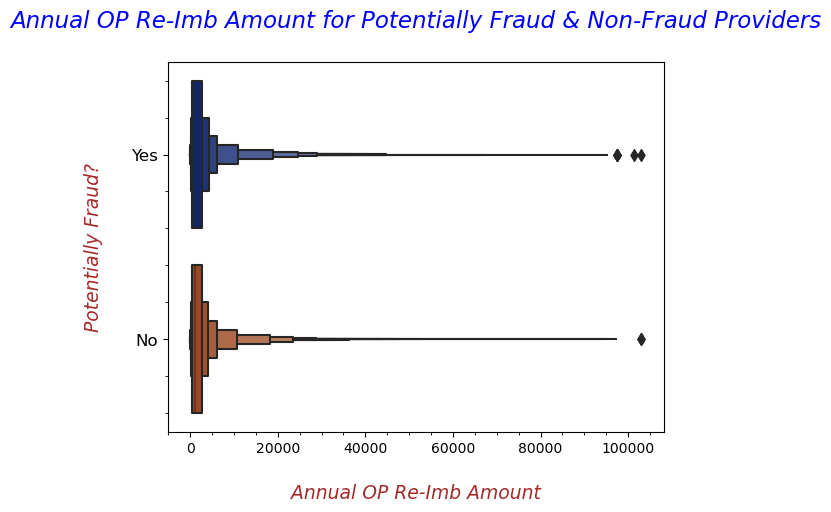

In [55]:
fig = sns.boxenplot(data=train_iobp_df[train_iobp_df['Admitted?'] == 0], y='PotentialFraud', x='OPAnnualReimbursementAmt', 
                     palette='dark', orient='h')   
plt.ylabel("Potentially Fraud?\n", fontdict=label_font_dict)
plt.yticks(rotation=0, fontsize=12)
plt.xlabel("\nAnnual OP Re-Imb Amount", fontdict=label_font_dict)
plt.minorticks_on()
plt.title("Annual OP Re-Imb Amount for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Annual OP Re-Imb Amount for Potentially Fraud and Non-Fraud Providers.
    * And, it looks like a Pareto Distribution.

#### **Why do we have `OP Annual Re-Imb Amount` as `0` for `Admitted Patients`?**

In [56]:
print(pd.DataFrame(train_iobp_df[(train_iobp_df['OPAnnualReimbursementAmt'] == 0)]['Admitted?'].value_counts()))

   Admitted?
1       3909
0       1009


- So, we have 1009 claims where Patients were not admitted to the hospital but the allocated `OP Annual Re-Imb Amt` is 0.

In [57]:
print(pd.DataFrame(train_iobp_df[(train_iobp_df['OPAnnualReimbursementAmt'] == 0) & (train_iobp_df['Admitted?'] == 0)]\
                   ['PotentialFraud'].value_counts()))

     PotentialFraud
No              617
Yes             392


- So, out 1009 claims 38% of them means 392 are fraudulent whereas 62% or 617 are non-fraudulent.

**`OBSERVATION`**

- **Thus, we can say that if the OP Annual Amount is 0 and patient was not admitted to the hospital then chances of being fraudulent are less.**

- **Relationship b/w `OPAnnualReimbursementAmt` and `Potentially Fraud` for both the `Genders`**

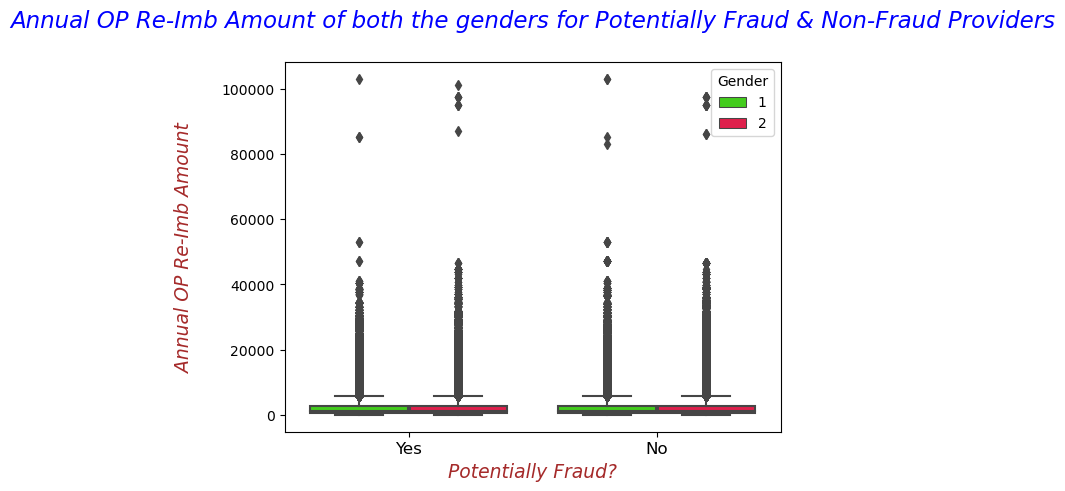

In [58]:
fig = sns.boxplot(data=train_iobp_df[train_iobp_df['Admitted?'] == 0], x='PotentialFraud',y='OPAnnualReimbursementAmt', hue='Gender',
                  palette='prism')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Annual OP Re-Imb Amount\n", fontdict=label_font_dict)
plt.title("Annual OP Re-Imb Amount of both the genders for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Annual OP Re-Imb Amount of males and females for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Annual OP Re-Imb Amount might not be useful in segregating the Fraud cases.

- **Relationship b/w `OPAnnualReimbursementAmt` and `Potentially Fraud` for `Is_Alive?`**

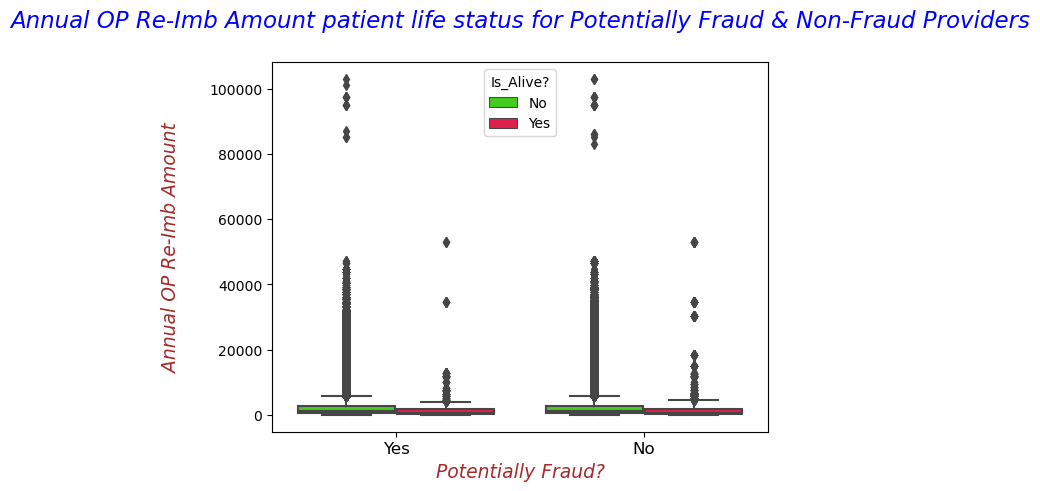

In [59]:
fig = sns.boxplot(data=train_iobp_df[train_iobp_df['Admitted?'] == 0], x='PotentialFraud',y='OPAnnualReimbursementAmt', hue='Is_Alive?',
                      palette='prism')      
# Providing the labels and title to the graph
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Annual OP Re-Imb Amount\n", fontdict=label_font_dict)
plt.title("Annual OP Re-Imb Amount patient life status for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.legend(loc="upper center", title='Is_Alive?')
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Annual OP Re-Imb Amount on patient life status for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Annual OP Re-Imb Amount might not be useful in segregating the Fraud cases.

- **Relationship b/w `OPAnnualReimbursementAmt` and `Potentially Fraud` for all `Human Races`**

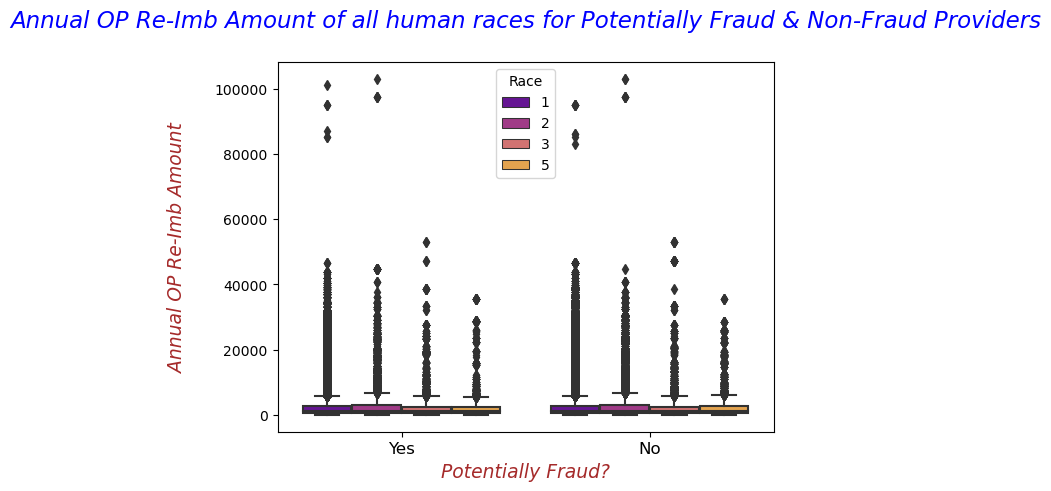

In [60]:
fig = sns.boxplot(data=train_iobp_df[train_iobp_df['Admitted?'] == 0], x='PotentialFraud',y='OPAnnualReimbursementAmt', hue='Race',
                  palette='plasma')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Annual OP Re-Imb Amount\n", fontdict=label_font_dict)
plt.title("Annual OP Re-Imb Amount of all human races for Potentially Fraud & Non-Fraud Providers\n", fontdict=title_font_dict)
plt.legend(loc="upper center", title="Race")
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is no difference in the distribution of Annual OP Re-Imb Amount of all human races for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Annual OP Re-Imb Amount might not be useful in segregating the Fraud cases.

- **Relationship b/w `OPAnnualReimbursementAmt` and `Potentially Fraud` for `RenalDiseaseIndicator`**

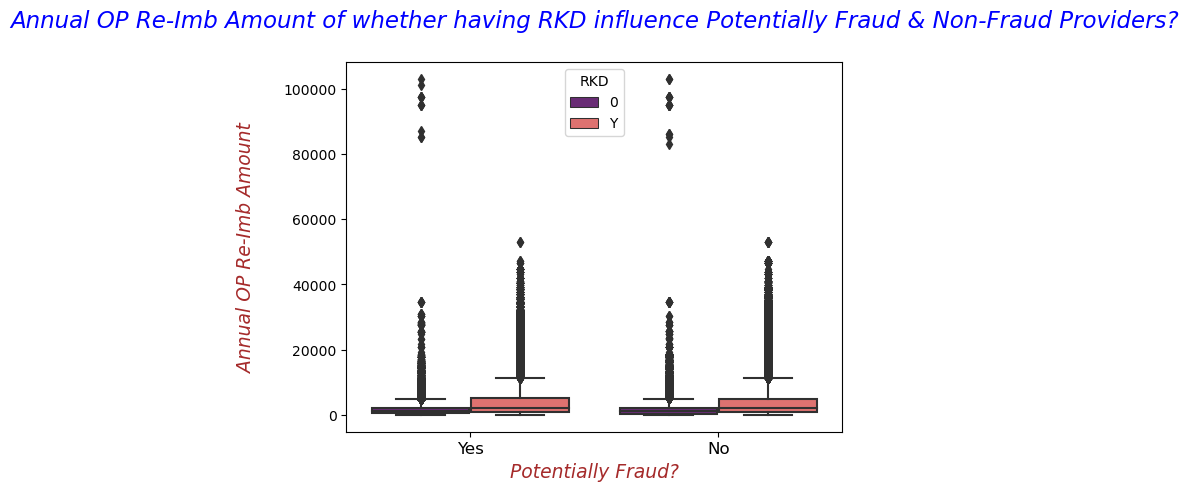

In [61]:
fig = sns.boxplot(data=train_iobp_df[train_iobp_df['Admitted?'] == 0], x='PotentialFraud',y='OPAnnualReimbursementAmt', 
                  hue='RenalDiseaseIndicator',palette='magma')   
plt.xlabel("Potentially Fraud?", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Annual OP Re-Imb Amount\n", fontdict=label_font_dict)
plt.title("Annual OP Re-Imb Amount of whether having RKD influence Potentially Fraud & Non-Fraud Providers?\n", fontdict=title_font_dict)
plt.legend(loc='upper center', title='RKD')
plt.show()

**`OBSERVATION`**
* The above plot clearly shows us that there is a very slight difference in the distribution of Annual OP Re-Imb Amount of patients with or w/o RKD for Potentially Fraud and Non-Fraud Providers.
    * Therefore, we can say that Annual OP Re-Imb Amount might not be useful in segregating the Fraud cases.

### **Adding `New Feature` :: `Total Number of false claims filed by a Provider`**

    - Logic :: COUNT(all claims submitted by a Provider) - COUNT(all non-fraud claims submitted by a Provider)

**`REASONING`**

- The idea behind adding this feature is to introduce a way by which we can see how many fraud or non fraud claims been submitted by a provider.

- _Generally what has been observed in medicare frauds is that many small hospitals from rural places had been intentionally used for filing the false claims by giving them bribes or in desire of kickbacks. Thus, for such providers total claims submitted will be less but majority of them will be false._

- ***But, the problem in the given dataset after joining(IP, OP, BENE with PRV TGT) is that***

### **Adding `New Feature` :: `Total Number of claims or cases seen by Attending Physician`**

In [62]:
# Total unique number of Attended Physicians
print("Unique number of Attending Physicians present in the dataset are: {}".format(train_iobp_df['AttendingPhysician'].nunique()))

Unique number of Attending Physicians present in the dataset are: 82063


In [63]:
train_iobp_df['Att_Phy_tot_claims'] = train_iobp_df.groupby(['AttendingPhysician'])['ClaimID'].transform('count')
train_iobp_df['Att_Phy_tot_claims'].describe()

count    556703.000000
mean        138.634829
std         293.669039
min           1.000000
25%           7.000000
50%          33.000000
75%         116.000000
max        2534.000000
Name: Att_Phy_tot_claims, dtype: float64

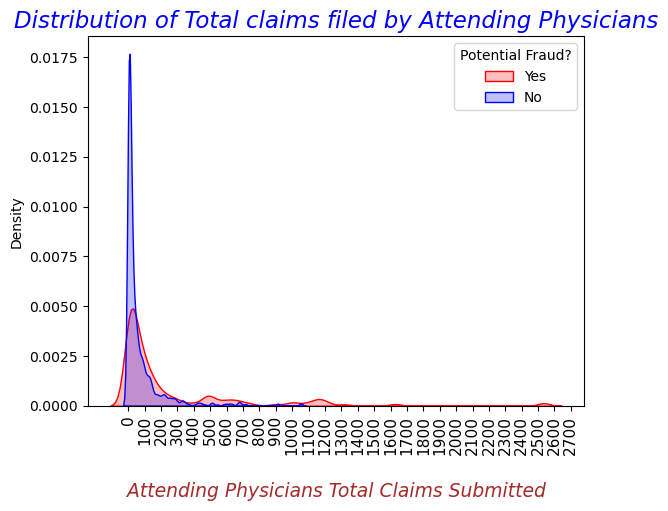

In [64]:
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'Yes']['Att_Phy_tot_claims'],color='r', shade = True)
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'No']['Att_Phy_tot_claims'],color='b', shade =True)
plt.xlabel("\nAttending Physicians Total Claims Submitted", fontdict=label_font_dict)
plt.xticks(np.arange(0,2800,100), rotation=90, fontsize=11)
plt.title("Distribution of Total claims filed by Attending Physicians", fontdict=title_font_dict)
plt.legend(labels=["Yes", "No"], title="Potential Fraud?")
plt.show()

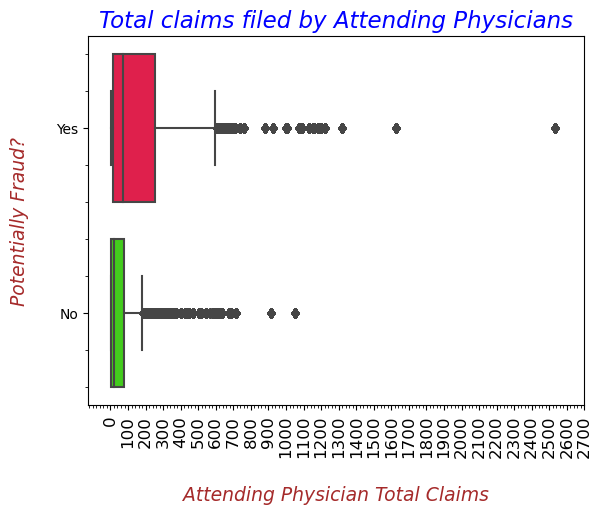

In [65]:
fig = sns.boxplot(data=train_iobp_df, y='PotentialFraud', x='Att_Phy_tot_claims', palette='prism_r', orient='h')   
plt.ylabel("Potentially Fraud?\n", fontdict=label_font_dict)
plt.xticks(np.arange(0,2800,100), rotation=90, fontsize=12)
plt.xlabel("\nAttending Physician Total Claims", fontdict=label_font_dict)
plt.minorticks_on()
plt.title("Total claims filed by Attending Physicians", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above KDE and Box plots suggests that the newly added feature `Att_Phy_tot_claims` may be useful in segregating the potentially fraud and non-fraudulent cases.
    * For example, we can say that if total claims filed by a Attending Physician is greater than 500 then chances of being fraudulent are high.

### **Adding `New Feature` :: `Total Number of claims or cases seen by Opearting Physician`**

In [66]:
# Total unique number of Operating Physicians
print("Unique number of Operating Physicians present in the dataset are: {}".format(train_iobp_df['OperatingPhysician'].nunique()))

Unique number of Operating Physicians present in the dataset are: 35315


In [67]:
train_iobp_df['Opr_Phy_tot_claims'] = train_iobp_df.groupby(['OperatingPhysician'])['ClaimID'].transform('count')
train_iobp_df['Opr_Phy_tot_claims'].describe()

count    114447.000000
mean         27.204811
std          52.687759
min           1.000000
25%           2.000000
50%           8.000000
75%          25.000000
max         424.000000
Name: Opr_Phy_tot_claims, dtype: float64

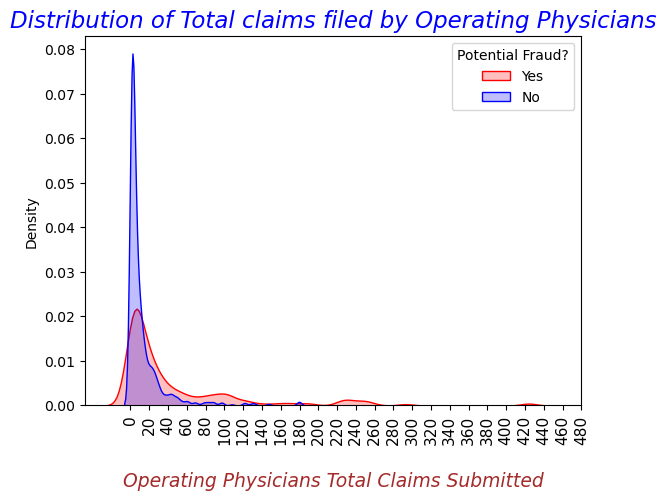

In [68]:
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'Yes']['Opr_Phy_tot_claims'],color='r', shade = True)
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'No']['Opr_Phy_tot_claims'],color='b', shade = True)
plt.xlabel("\nOperating Physicians Total Claims Submitted", fontdict=label_font_dict)
plt.xticks(np.arange(0,500,20), rotation=90, fontsize=11)
plt.title("Distribution of Total claims filed by Operating Physicians", fontdict=title_font_dict)
plt.legend(labels=["Yes", "No"], title="Potential Fraud?")
plt.show()

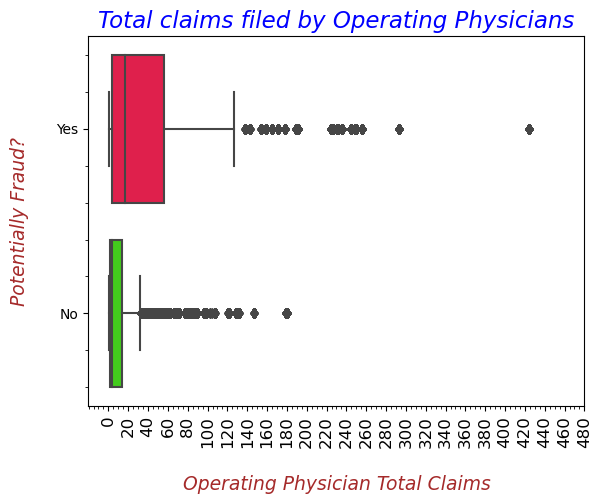

In [69]:
fig = sns.boxplot(data=train_iobp_df, y='PotentialFraud', x='Opr_Phy_tot_claims', palette='prism_r', orient='h')   
plt.ylabel("Potentially Fraud?\n", fontdict=label_font_dict)
plt.xticks(np.arange(0,500,20), rotation=90, fontsize=12)
plt.xlabel("\nOperating Physician Total Claims", fontdict=label_font_dict)
plt.minorticks_on()
plt.title("Total claims filed by Operating Physicians", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above KDE and Box plots suggests that the newly added feature `Opr_Phy_tot_claims` may be useful in segregating the potentially fraud and non-fraudulent cases.
    * Results are very similar to `Att_Phy_tot_claims`.
        * For example, we can say that if total claims filed by a Operating Physician are greater than 100 then chances of being fraudulent are high.

### **Adding `New Feature` :: `Total Number of claims or cases seen by Other Physician`**

In [70]:
# Total unique number of Other Physicians
print("Unique number of Other Physicians present in the dataset are: {}".format(train_iobp_df['OtherPhysician'].nunique()))

Unique number of Other Physicians present in the dataset are: 46457


In [71]:
train_iobp_df['Oth_Phy_tot_claims'] = train_iobp_df.groupby(['OtherPhysician'])['ClaimID'].transform('count')
train_iobp_df['Oth_Phy_tot_claims'].describe()

count    199736.000000
mean         90.207914
std         208.017235
min           1.000000
25%           3.000000
50%          15.000000
75%          60.000000
max        1247.000000
Name: Oth_Phy_tot_claims, dtype: float64

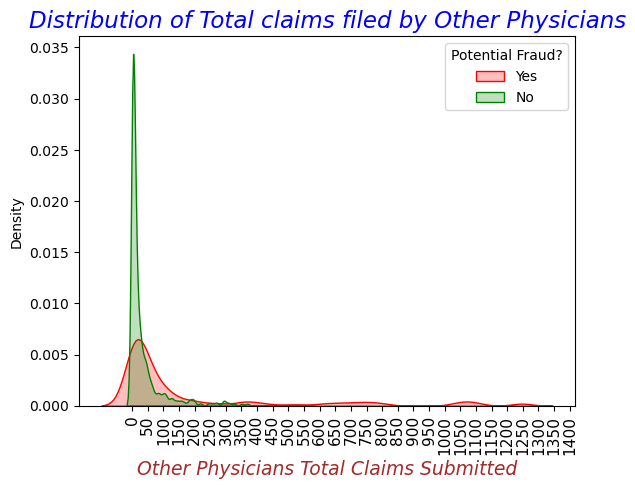

In [72]:
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'Yes']['Oth_Phy_tot_claims'],color='red',shade=True)
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'No']['Oth_Phy_tot_claims'],color='green',shade=True)
plt.xlabel("Other Physicians Total Claims Submitted", fontdict=label_font_dict)
plt.xticks(np.arange(0,1450,50), rotation=90, fontsize=11)
plt.title("Distribution of Total claims filed by Other Physicians", fontdict=title_font_dict)
plt.legend(labels=["Yes", "No"], title="Potential Fraud?")
plt.show()

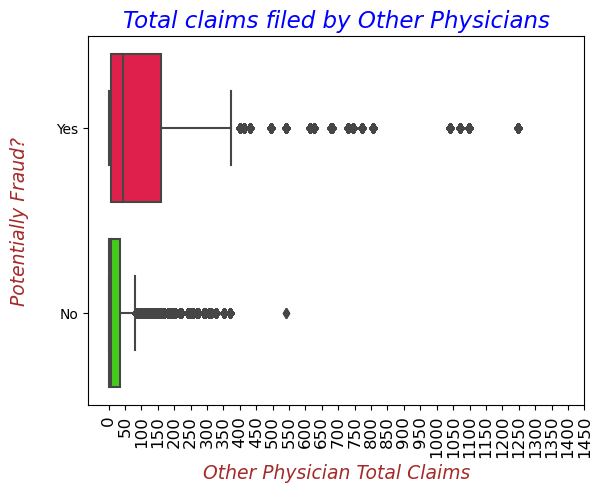

In [73]:
fig = sns.boxplot(data=train_iobp_df, y='PotentialFraud', x='Oth_Phy_tot_claims', palette='prism_r', orient='h')   
plt.ylabel("Potentially Fraud?\n", fontdict=label_font_dict)
plt.xticks(np.arange(0,1500,50), rotation=90, fontsize=12)
plt.xlabel("Other Physician Total Claims", fontdict=label_font_dict)
plt.title("Total claims filed by Other Physicians", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above KDE and Box plots suggests that the newly added feature `Oth_Phy_tot_claims` may be useful in segregating the potentially fraud and non-fraudulent cases.
    * Results are very similar to `Att_Phy_tot_claims`.
        * For example, we can say that if total claims filed by a Other Physician are greater than 100 then chances of being fraudulent are high.

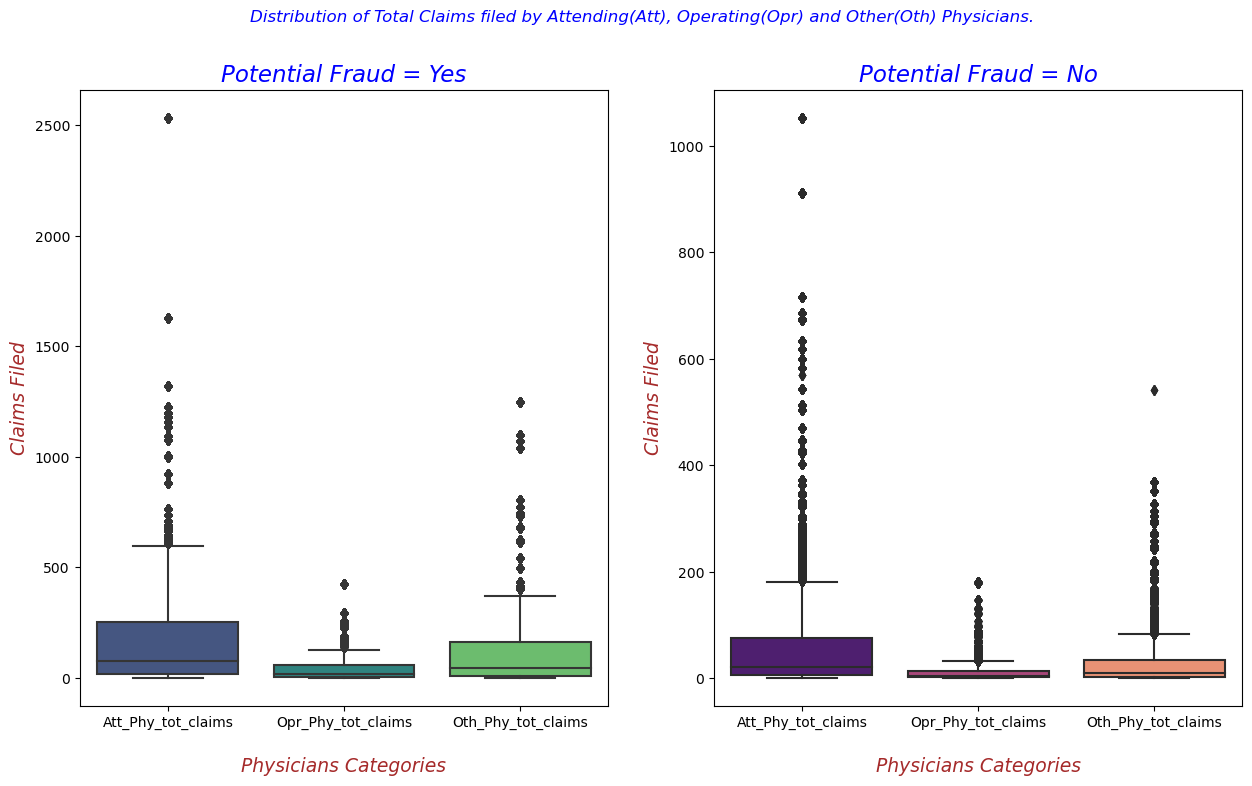

In [74]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(15,8), sharey=False)
sns.boxplot(data=train_iobp_df[train_iobp_df["PotentialFraud"] == 'Yes'][['Att_Phy_tot_claims','Opr_Phy_tot_claims','Oth_Phy_tot_claims']],
            ax=ax1, palette='viridis')
ax1.set_title("Potential Fraud = Yes", fontdict=title_font_dict)
ax1.set_xlabel("\nPhysicians Categories", fontdict=label_font_dict)
ax1.set_ylabel("Claims Filed", fontdict=label_font_dict)

sns.boxplot(data=train_iobp_df[train_iobp_df["PotentialFraud"] == 'No'][['Att_Phy_tot_claims','Opr_Phy_tot_claims','Oth_Phy_tot_claims']],
            ax=ax2, palette='magma')
ax2.set_title("Potential Fraud = No", fontdict=title_font_dict)
ax2.set_xlabel("\nPhysicians Categories", fontdict=label_font_dict)
ax2.set_ylabel("Claims Filed", fontdict=label_font_dict)
# Providing the title to the figure
fig.suptitle("Distribution of Total Claims filed by Attending(Att), Operating(Opr) and Other(Oth) Physicians.\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above Box plots suggests that theses newly added features may be slightly useful in segregating the potentially fraud and non-fraudulent cases.
    * As we can see that the total false claims filed by physicians are slightly more than the non-false claims filed by them.

### **Adding `Combined Feature` :: `Att_Opr_Oth_Phy_Tot_Claims`**
    
   * It represents the total claims submitted by Attending, Operating and Other Physicians.
       
       * **`Reasoning`** :: The idea behind adding this feature is to see whether a total of physicians claims submission will help in influencing the potential frauds.


   * **`Logic`** :: Att_Phy_tot_claims + Opr_Phy_tot_claims + Oth_Phy_tot_claims

In [75]:
train_iobp_df['Att_Phy_tot_claims'].fillna(value=0, inplace=True)
train_iobp_df['Opr_Phy_tot_claims'].fillna(value=0, inplace=True)
train_iobp_df['Oth_Phy_tot_claims'].fillna(value=0, inplace=True)

In [76]:
train_iobp_df['Att_Opr_Oth_Phy_Tot_Claims'] = train_iobp_df['Att_Phy_tot_claims'] + train_iobp_df['Opr_Phy_tot_claims'] + train_iobp_df['Oth_Phy_tot_claims']

In [77]:
train_iobp_df['Att_Opr_Oth_Phy_Tot_Claims'].describe()

count    558211.000000
mean        176.115666
std         379.833208
min           0.000000
25%           9.000000
50%          41.000000
75%         144.000000
max        3372.000000
Name: Att_Opr_Oth_Phy_Tot_Claims, dtype: float64

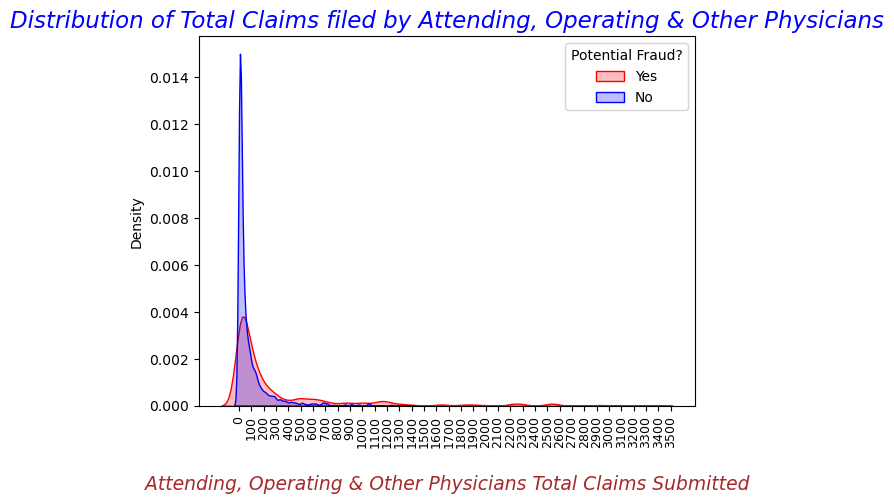

In [78]:
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'Yes']['Att_Opr_Oth_Phy_Tot_Claims'],color='red',shade=True)
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'No']['Att_Opr_Oth_Phy_Tot_Claims'],color='b',shade=True)
# Providing the labels and title to the graph
plt.xlabel("\nAttending, Operating & Other Physicians Total Claims Submitted", fontdict=label_font_dict)
plt.xticks(np.arange(0,3600,100), rotation=90, fontsize=9)
plt.title("Distribution of Total Claims filed by Attending, Operating & Other Physicians", fontdict=title_font_dict)
plt.legend(labels=["Yes", "No"], title="Potential Fraud?")
plt.show()

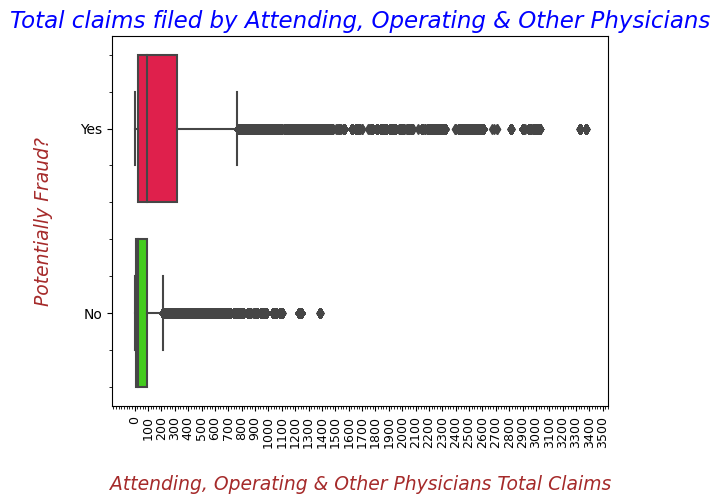

In [79]:
fig = sns.boxplot(data=train_iobp_df, y='PotentialFraud', x='Att_Opr_Oth_Phy_Tot_Claims', palette='prism_r', orient='h')   
plt.ylabel("Potentially Fraud?\n", fontdict=label_font_dict)
plt.xticks(np.arange(0,3600,100), rotation=90, fontsize=9)
plt.xlabel("\nAttending, Operating & Other Physicians Total Claims", fontdict=label_font_dict)
plt.minorticks_on()
plt.title("Total claims filed by Attending, Operating & Other Physicians", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above Box plots shows us the similar results like the previous features. And, there is a slight difference in the data distributions which may be useful in segregating the potential frauds.

### **Adding `3` `New Features` :: `Prv_Tot_Att_Phy`, `Prv_Tot_Opr_Phy` and `Prv_Tot_Oth_Phy`**
    
   * These features will represent the total Attending, Operating and Other Physicians for every provider.
       * **`Reasoning`** :: The idea behind adding this feature is to see if a provider has wroked with very less or very high number of physicians then does that increases or decreases the chances of potential fraud.

In [80]:
train_iobp_df["Prv_Tot_Att_Phy"] = train_iobp_df.groupby(['Provider'])['AttendingPhysician'].transform('count')
train_iobp_df["Prv_Tot_Opr_Phy"] = train_iobp_df.groupby(['Provider'])['OperatingPhysician'].transform('count')
train_iobp_df["Prv_Tot_Oth_Phy"] = train_iobp_df.groupby(['Provider'])['OtherPhysician'].transform('count')

In [81]:
# Nulls in the above features
train_iobp_df.isna().sum().tail(3)

Prv_Tot_Att_Phy    0
Prv_Tot_Opr_Phy    0
Prv_Tot_Oth_Phy    0
dtype: int64

In [82]:
train_iobp_df["Prv_Tot_Att_Phy"].describe()

count    558211.000000
mean        820.206469
std        1271.272090
min           1.000000
25%         122.000000
50%         359.000000
75%        1013.000000
max        8207.000000
Name: Prv_Tot_Att_Phy, dtype: float64

* The average number of attending physicians for providers are 820.

In [83]:
train_iobp_df["Prv_Tot_Opr_Phy"].describe()

count    558211.000000
mean        155.030023
std         228.266693
min           0.000000
25%          25.000000
50%          73.000000
75%         185.000000
max        1441.000000
Name: Prv_Tot_Opr_Phy, dtype: float64

* The average number of operating physicians for providers are 155.

In [84]:
train_iobp_df["Prv_Tot_Oth_Phy"].describe()

count    558211.000000
mean        306.781194
std         497.246984
min           0.000000
25%          37.000000
50%         120.000000
75%         381.000000
max        3209.000000
Name: Prv_Tot_Oth_Phy, dtype: float64

* The average number of other physicians for providers are 306.

* **Relationship b/w PROVIDER and ATTENDING PHYSICIAN**

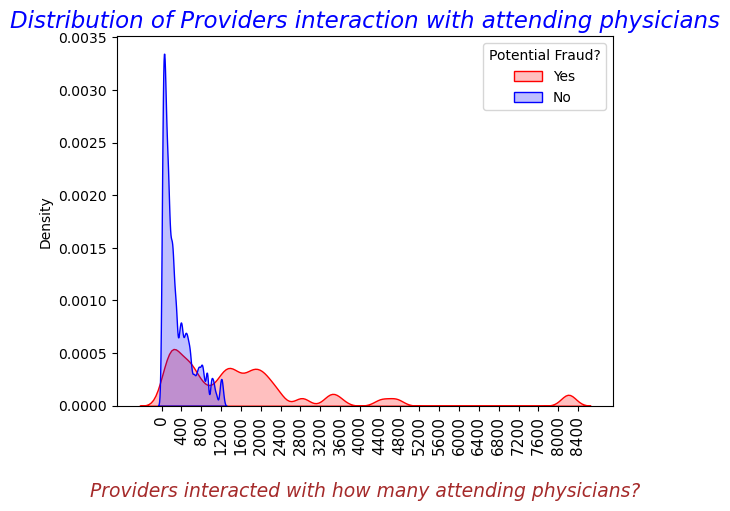

In [85]:
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'Yes']['Prv_Tot_Att_Phy'],color='r', shade=True)
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'No']['Prv_Tot_Att_Phy'],color='b', shade=True)
plt.xlabel("\nProviders interacted with how many attending physicians?", fontdict=label_font_dict)
plt.xticks(np.arange(0,8800,400), rotation=90, fontsize=11)
plt.title("Distribution of Providers interaction with attending physicians", fontdict=title_font_dict)
plt.legend(labels=["Yes", "No"], title="Potential Fraud?")
plt.show()

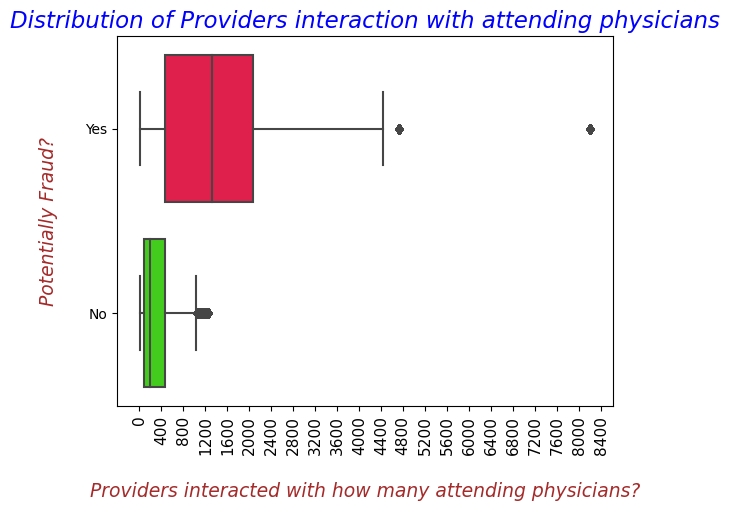

In [86]:
fig = sns.boxplot(data=train_iobp_df, y='PotentialFraud', x='Prv_Tot_Att_Phy', palette='prism_r', orient='h')   
plt.ylabel("Potentially Fraud?\n", fontdict=label_font_dict)
plt.xticks(np.arange(0,8800,400), rotation=90, fontsize=11)
plt.xlabel("\nProviders interacted with how many attending physicians?", fontdict=label_font_dict)
plt.title("Distribution of Providers interaction with attending physicians", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above KDE and Box plots are quite interesting as we can see that if `Prv_Tot_Att_Phy` is high then chances of fraud is quite high.

* **Relationship b/w PROVIDER and OPERATING PHYSICIAN**

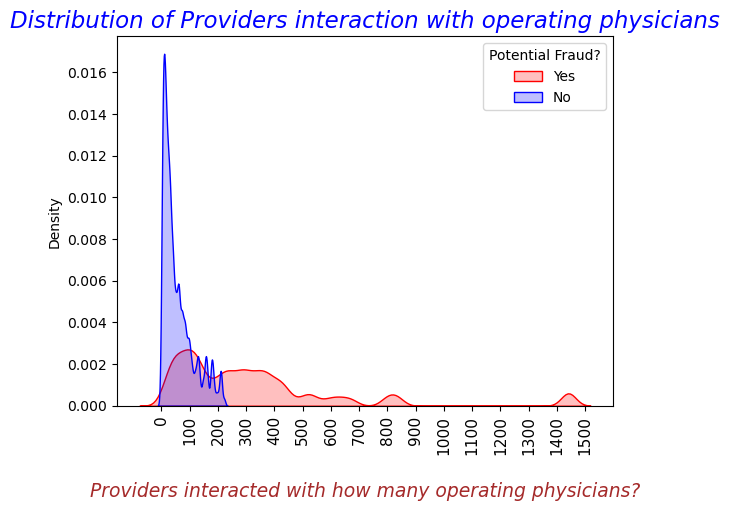

In [87]:
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'Yes']['Prv_Tot_Opr_Phy'],color='red', shade=True)
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'No']['Prv_Tot_Opr_Phy'],color='blue', shade=True)
plt.xlabel("\nProviders interacted with how many operating physicians?", fontdict=label_font_dict)
plt.xticks(np.arange(0,1600,100), rotation=90, fontsize=11)
plt.title("Distribution of Providers interaction with operating physicians", fontdict=title_font_dict)
plt.legend(labels=["Yes", "No"], title="Potential Fraud?")
plt.show()

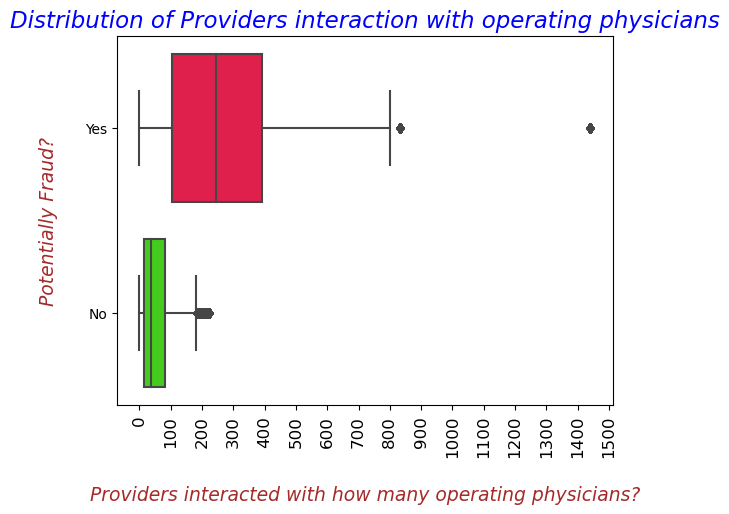

In [88]:
fig = sns.boxplot(data=train_iobp_df, y='PotentialFraud', x='Prv_Tot_Opr_Phy', palette='prism_r', orient='h')   
plt.ylabel("Potentially Fraud?\n", fontdict=label_font_dict)
plt.xticks(np.arange(0,1600,100), rotation=90, fontsize=12)
plt.xlabel("\nProviders interacted with how many operating physicians?", fontdict=label_font_dict)
plt.title("Distribution of Providers interaction with operating physicians", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above KDE and Box plots are quite interesting as we can see that if `Prv_Tot_Opr_Phy` is high then chances of fraud is quite high.

* **Relationship b/w PROVIDER and OTHER PHYSICIAN**

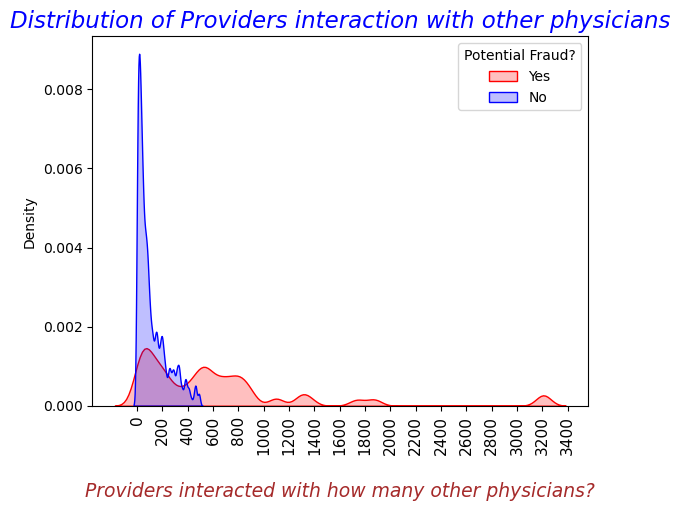

In [89]:
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'Yes']['Prv_Tot_Oth_Phy'],color='red', shade=True)
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'No']['Prv_Tot_Oth_Phy'],color='blue', shade=True)
plt.xlabel("\nProviders interacted with how many other physicians?", fontdict=label_font_dict)
plt.xticks(np.arange(0,3600,200), rotation=90, fontsize=11)
plt.title("Distribution of Providers interaction with other physicians", fontdict=title_font_dict)
plt.legend(labels=["Yes", "No"], title="Potential Fraud?")
plt.show()

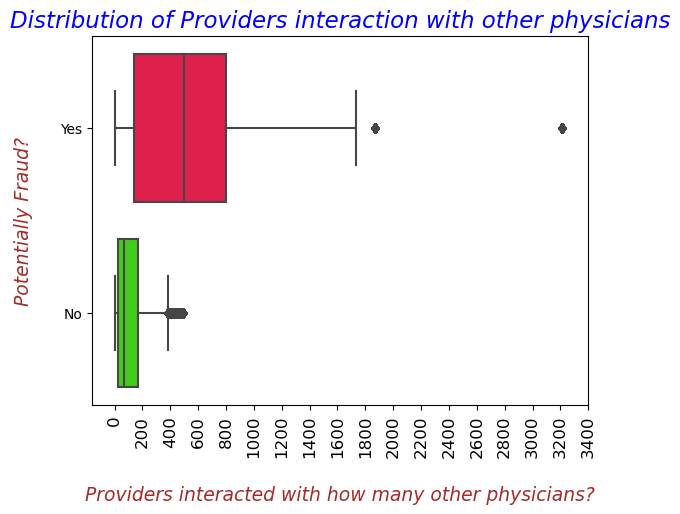

In [90]:
fig = sns.boxplot(data=train_iobp_df, y='PotentialFraud', x='Prv_Tot_Oth_Phy', palette='prism_r', orient='h')   
plt.ylabel("Potentially Fraud?\n", fontdict=label_font_dict)
plt.xticks(np.arange(0,3600,200), rotation=90, fontsize=12)
plt.xlabel("\nProviders interacted with how many other physicians?", fontdict=label_font_dict)
plt.title("Distribution of Providers interaction with other physicians", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above KDE and Box plots are quite interesting as we can see that if `Prv_Tot_Oth_Phy` is high then chances of fraud is quite high.

### **Adding `Combined Feature` :: `Prv_Tot_Att_Opr_Oth_Phys`**
    
   * It represents the total of all kind of physicians that a provider has interacted with.
       
       * **`Reasoning`** :: The idea behind adding this feature is to see whether a fraudulent provider interacts with higher or lower numberof of various physicians.


   * **`Logic`** :: Prv_Tot_Att_Phy + Prv_Tot_Opr_Phy + Prv_Tot_Oth_Phy

In [91]:
train_iobp_df['Prv_Tot_Att_Opr_Oth_Phys'] = train_iobp_df['Prv_Tot_Att_Phy'] + train_iobp_df['Prv_Tot_Opr_Phy'] + train_iobp_df['Prv_Tot_Oth_Phy']

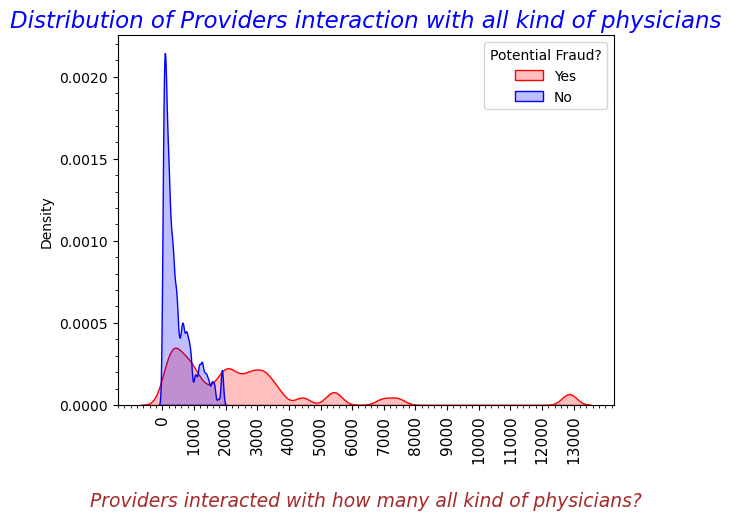

In [92]:
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'Yes']['Prv_Tot_Att_Opr_Oth_Phys'],color='red', shade=True)
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'No']['Prv_Tot_Att_Opr_Oth_Phys'],color='blue', shade=True)
plt.xlabel("\nProviders interacted with how many all kind of physicians?", fontdict=label_font_dict)
plt.xticks(np.arange(0,14000,1000), rotation=90, fontsize=11)
plt.minorticks_on()
plt.title("Distribution of Providers interaction with all kind of physicians", fontdict=title_font_dict)
plt.legend(labels=["Yes", "No"], title="Potential Fraud?")
plt.show()

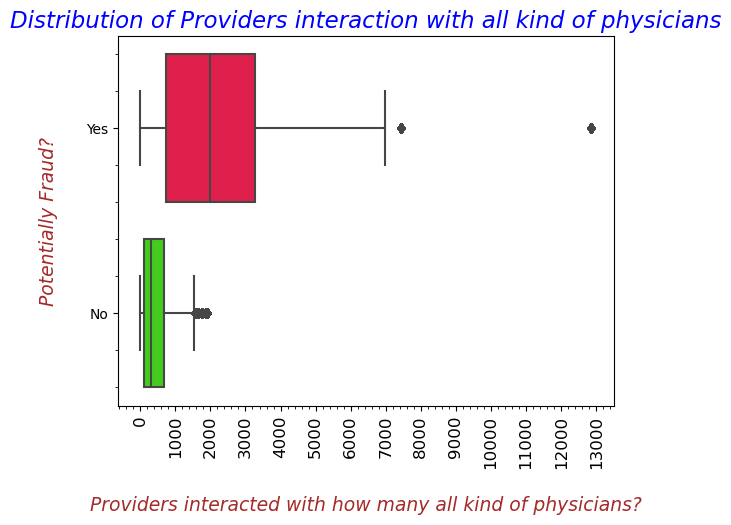

In [93]:
fig = sns.boxplot(data=train_iobp_df, y='PotentialFraud', x='Prv_Tot_Att_Opr_Oth_Phys', palette='prism_r', orient='h')   
plt.ylabel("Potentially Fraud?\n", fontdict=label_font_dict)
plt.xticks(np.arange(0,14000,1000), rotation=90, fontsize=12)
plt.xlabel("\nProviders interacted with how many all kind of physicians?", fontdict=label_font_dict)
plt.minorticks_on()
plt.title("Distribution of Providers interaction with all kind of physicians", fontdict=title_font_dict)
plt.show();

**`OBSERVATION`**
* The above KDE and Box plots are quite interesting as we can see that if `Prv_Tot_Att_Opr_Oth_Phys` is high then chances of fraud is quite high.

### **Adding `New Feature` :: `Total Unique Claim Admit Codes used by a PROVIDER`**
   
   * **`Reasoning`** :: The idea behind adding this feature is to see how many unique number of `Claim Admit Diagnosis Codes` used by the Provider. 
       * As there may be a pattern that if a provider has used so many Admit Diagnosis Codes then it might increases or decreases the chances of fraud.

In [94]:
train_iobp_df['PRV_Tot_Admit_DCodes'] = train_iobp_df.groupby(['Provider'])['ClmAdmitDiagnosisCode'].transform('nunique')

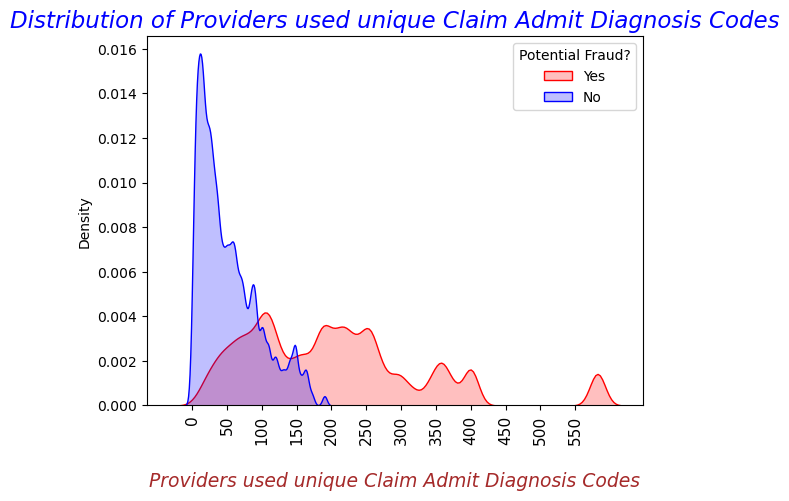

In [95]:
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'Yes']['PRV_Tot_Admit_DCodes'], color='red', shade=True)
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'No']['PRV_Tot_Admit_DCodes'], color='blue', shade=True)
plt.xlabel("\nProviders used unique Claim Admit Diagnosis Codes", fontdict=label_font_dict)
plt.xticks(np.arange(0,600,50), rotation=90, fontsize=11)
plt.title("Distribution of Providers used unique Claim Admit Diagnosis Codes", fontdict=title_font_dict)
plt.legend(labels=["Yes", "No"], title="Potential Fraud?")
plt.show()

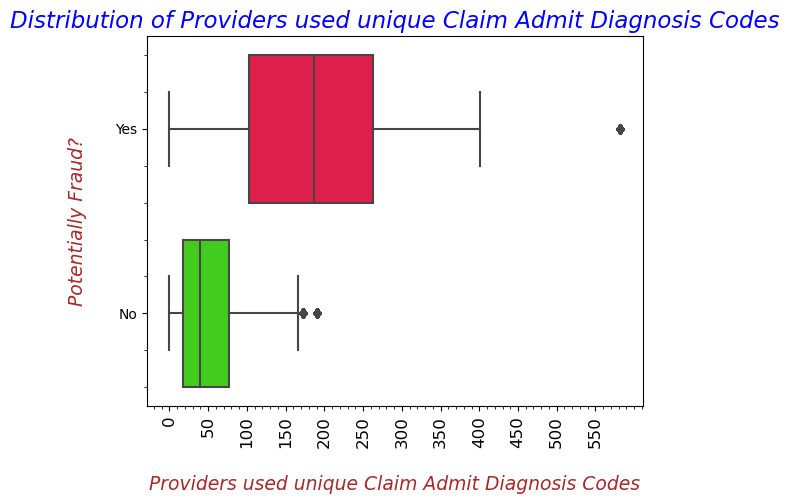

In [96]:
fig = sns.boxplot(data=train_iobp_df, y='PotentialFraud', x='PRV_Tot_Admit_DCodes', palette='prism_r', orient='h')   
plt.ylabel("Potentially Fraud?\n", fontdict=label_font_dict)
plt.xticks(np.arange(0,600,50), rotation=90, fontsize=12)
plt.xlabel("\nProviders used unique Claim Admit Diagnosis Codes", fontdict=label_font_dict)
plt.minorticks_on()
plt.title("Distribution of Providers used unique Claim Admit Diagnosis Codes", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above KDE and Box plots are very interesting as we can see that if `PRV_Tot_Admit_DCodes` is high then chances of fraud also increases.

**`NOTE` :: `What didn't worked?`**
* I also looked to add the `unique number of Admit Diagnosis Codes` used by the `3 different class of physicians` but the variation was very minimal, thus not added those features.

### **Adding `New Feature` :: `Total Unique Number of Diagnosis Group Codes used by a PROVIDER`**
   
   * **`Reasoning`** :: The idea behind adding this feature is to see how many unique `Diagnosis Group Codes` used by the Provider.
       * As there may be a pattern that if a provider has used so many Diagnosis Group Codes then it might increases or decreases the chances of fraud.

In [97]:
train_iobp_df['PRV_Tot_DGrpCodes'] = train_iobp_df.groupby(['Provider'])['DiagnosisGroupCode'].transform('nunique')

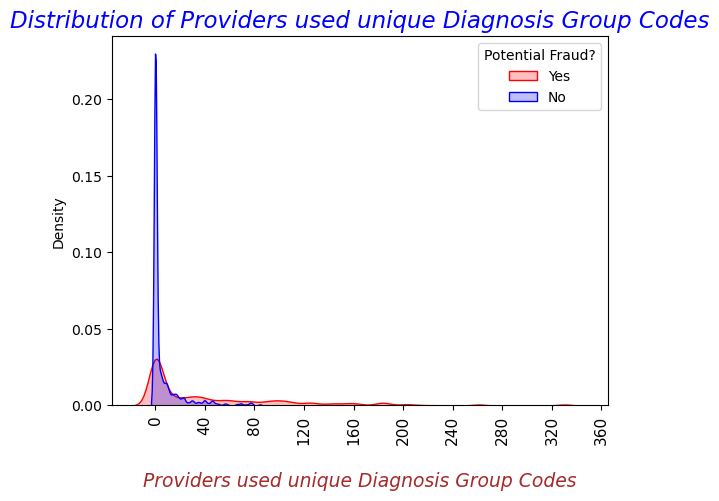

In [98]:
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'Yes']['PRV_Tot_DGrpCodes'], color='red', shade=True)
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'No']['PRV_Tot_DGrpCodes'], color='blue', shade=True)
plt.xlabel("\nProviders used unique Diagnosis Group Codes", fontdict=label_font_dict)
plt.xticks(np.arange(0,400,40), rotation=90, fontsize=11)
plt.title("Distribution of Providers used unique Diagnosis Group Codes", fontdict=title_font_dict)
plt.legend(labels=["Yes", "No"], title="Potential Fraud?")
plt.show()

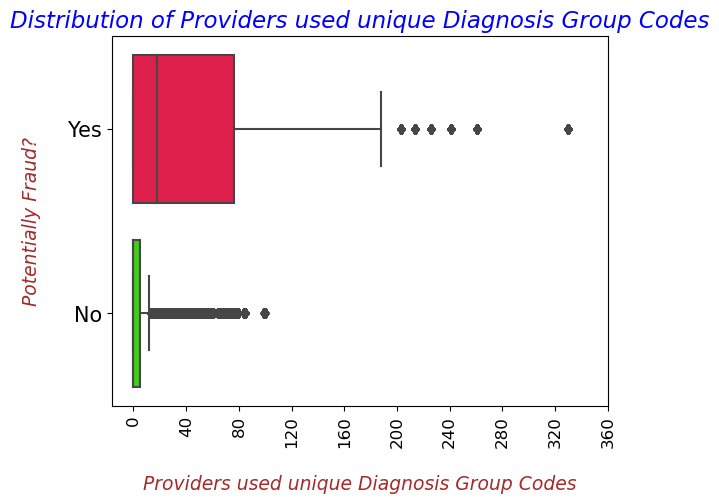

In [99]:
fig = sns.boxplot(data=train_iobp_df, y='PotentialFraud', x='PRV_Tot_DGrpCodes', palette='prism_r', orient='h')   
plt.ylabel("Potentially Fraud?\n", fontdict=label_font_dict)
plt.xticks(np.arange(0,400,40), rotation=90, fontsize=12)
plt.yticks(fontsize=15)
plt.xlabel("\nProviders used unique Diagnosis Group Codes", fontdict=label_font_dict)
plt.title("Distribution of Providers used unique Diagnosis Group Codes", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above KDE and Box plots suggest that if `PRV_Tot_Admit_DCodes` is high then it slightly increases the chances of fraud.


**`NOTE` :: `What didn't worked?`**
* I also looked to add the `unique number of Diagnosis Group Codes` used by the `3 different class of physicians` but the variation was very minimal, thus not added those features.


**`NOTE` :: `What didn't worked?`**
* I also looked to add `in how many claims a unique Diagnosis Group Code` is used but there was no variation at all, thus not added that feature. Kindly refer to the below image:

**`NOTE` :: `What didn't worked?`**
* I also looked to add `DOB -- Month`, `DOD -- Year` and `DOD -- Month` in order to see whether we can find some pattern of bogus DOB or DOD but there was no variation at all, thus not added that feature. Also, raw `DOB -- Year` also showed no variation. Kindly refer to the below image:

### **Adding `New Feature` :: `Total unique Date of Birth years of beneficiaries provided by a Provider`**
   
   * **`Reasoning`** :: The idea behind adding this feature is that if a provider has very high variability in the year of birth of patients then that might be one of the signs of medicare frauds.
       - Because generally private hospitals who treat poor patients make false claims on their names. 

In [100]:
train_iobp_df['DOB_Year'] = train_iobp_df['DOB'].dt.year

In [101]:
train_iobp_df['PRV_Tot_Unq_DOB_Years'] = train_iobp_df.groupby(['Provider'])['DOB_Year'].transform('nunique')

In [102]:
train_iobp_df['PRV_Tot_Unq_DOB_Years'].describe()

count    558211.000000
mean         50.615590
std          18.190988
min           1.000000
25%          38.000000
50%          54.000000
75%          67.000000
max          75.000000
Name: PRV_Tot_Unq_DOB_Years, dtype: float64

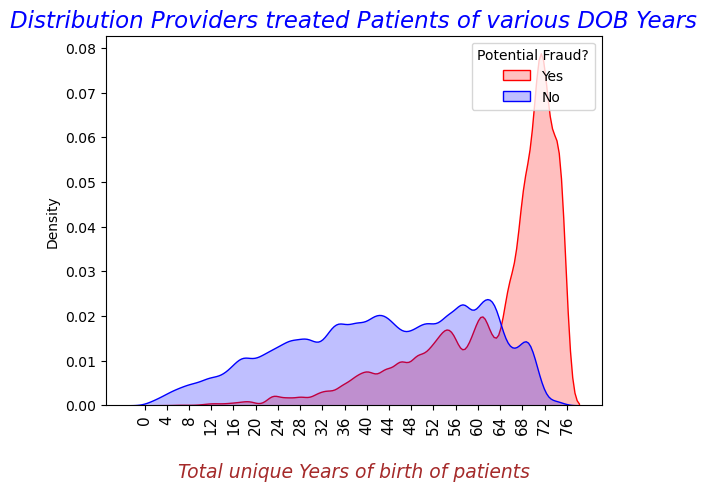

In [103]:
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'Yes']['PRV_Tot_Unq_DOB_Years'], color='red',shade=True)
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'No']['PRV_Tot_Unq_DOB_Years'], color='blue',shade=True)
plt.xlabel("\nTotal unique Years of birth of patients", fontdict=label_font_dict)
plt.xticks(np.arange(0,80,4), rotation=90, fontsize=11)
plt.title("Distribution Providers treated Patients of various DOB Years", fontdict=title_font_dict)
plt.legend(labels=["Yes", "No"], title="Potential Fraud?")
plt.show()

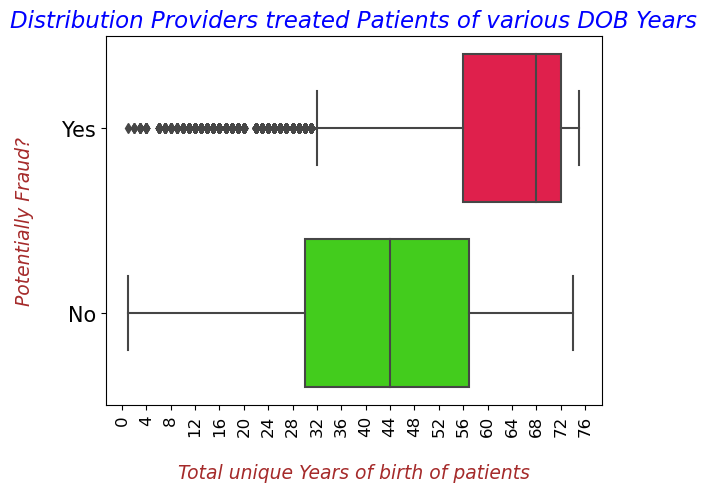

In [104]:
fig = sns.boxplot(data=train_iobp_df, y='PotentialFraud', x='PRV_Tot_Unq_DOB_Years', palette='prism_r', orient='h')   
plt.ylabel("Potentially Fraud?\n", fontdict=label_font_dict)
plt.yticks(fontsize=15)
plt.xticks(np.arange(0,80,4), rotation=90, fontsize=12)
plt.xlabel("\nTotal unique Years of birth of patients", fontdict=label_font_dict)
plt.title("Distribution Providers treated Patients of various DOB Years", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above KDE and Box plots suggest that if `PRV_Tot_Unq_DOB_Years` is very high than then it increases the chances of fraud as well.
    * As shown below, if PRV_Tot_Unq_DOB_Years is greater than or equals to 67 then the very high majority of cases are fraud.

In [105]:
train_iobp_df[train_iobp_df['PRV_Tot_Unq_DOB_Years'] >=67]['PotentialFraud'].value_counts()

Yes    118873
No      22203
Name: PotentialFraud, dtype: int64

### **Adding `New Feature` :: `Sum of patients age treated by a Provider`**
   
   * **`Reasoning`** :: The idea behind adding this feature is that there might be a pattern like if the sum of patients age treated by a provider is very high or low then it might influence the fraud.

In [106]:
train_iobp_df['PRV_Bene_Age_Sum'] = train_iobp_df.groupby(['Provider'])['Bene_Age'].transform('sum')

In [107]:
train_iobp_df['PRV_Bene_Age_Sum'].describe()

count    558211.000000
mean      60903.124044
std       95028.202759
min          34.300000
25%        9007.200000
50%       26310.800000
75%       74869.500000
max      617454.100000
Name: PRV_Bene_Age_Sum, dtype: float64

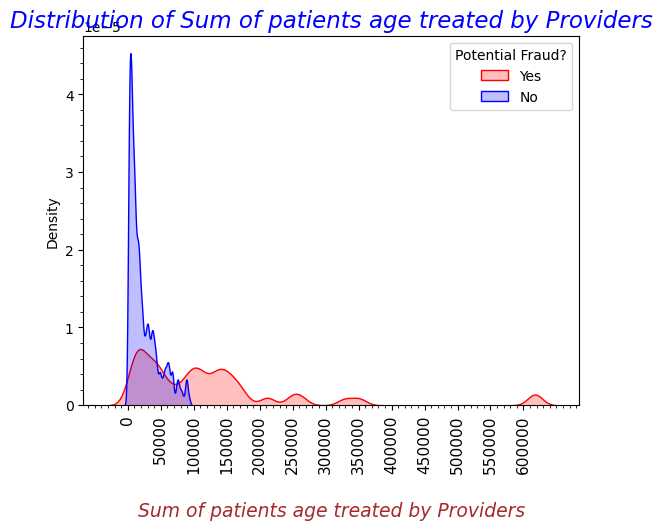

In [108]:
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'Yes']['PRV_Bene_Age_Sum'], color='red',shade=True)
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'No']['PRV_Bene_Age_Sum'], color='blue',shade=True)
plt.xlabel("\nSum of patients age treated by Providers", fontdict=label_font_dict)
plt.xticks(np.arange(0,620000,50000), rotation=90, fontsize=11)
plt.minorticks_on()
plt.title("Distribution of Sum of patients age treated by Providers", fontdict=title_font_dict)
plt.legend(labels=["Yes", "No"], title="Potential Fraud?")
plt.show()

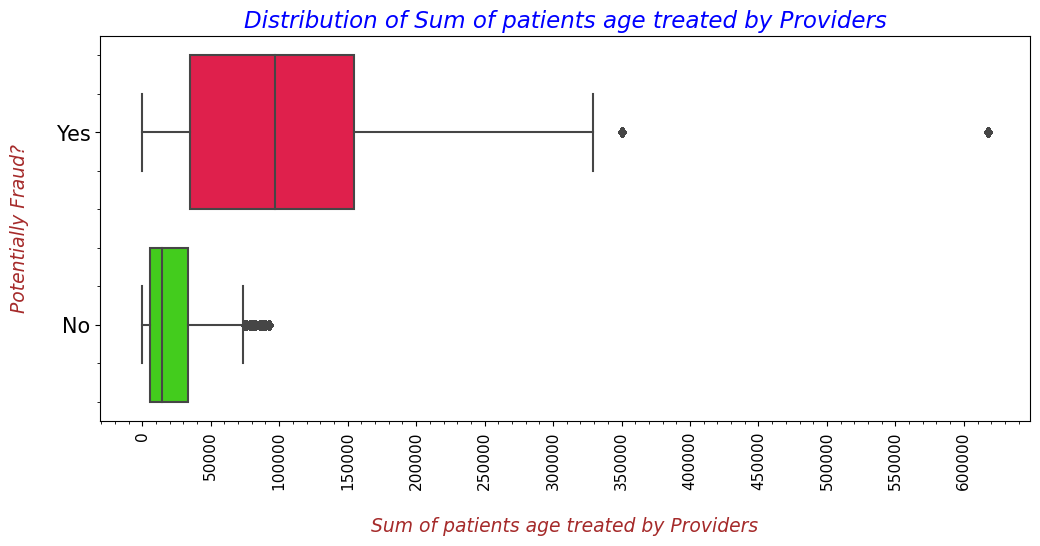

In [109]:
plt.figure(figsize = [12,5])
fig = sns.boxplot(data=train_iobp_df, y='PotentialFraud', x='PRV_Bene_Age_Sum', palette='prism_r', orient='h')   
plt.ylabel("Potentially Fraud?\n", fontdict=label_font_dict)
plt.yticks(fontsize=15)
plt.xticks(np.arange(0,620000,50000), rotation=90, fontsize=11)
plt.xlabel("\nSum of patients age treated by Providers", fontdict=label_font_dict)
plt.minorticks_on()
plt.title("Distribution of Sum of patients age treated by Providers", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above KDE and Box plots suggest that if `PRV_Bene_Age_Sum` is high then it increases the chances of fraud.

### **Adding `New Feature` :: `Sum of Insc Claim Re-Imb Amount for a Provider`**
   
   * **`Reasoning`** :: The idea behind adding this feature is that there might be a pattern like if the sum of claim re-imb amount for a provider is very high or low then it might influence the fraud.

In [110]:
train_iobp_df['PRV_Insc_Clm_ReImb_Amt'] = train_iobp_df.groupby(['Provider'])['InscClaimAmtReimbursed'].transform('sum')

In [111]:
train_iobp_df['PRV_Insc_Clm_ReImb_Amt'].describe()

count    5.582110e+05
mean     4.877429e+05
std      7.367223e+05
min      0.000000e+00
25%      6.369000e+04
50%      2.036000e+05
75%      5.969000e+05
max      5.996050e+06
Name: PRV_Insc_Clm_ReImb_Amt, dtype: float64

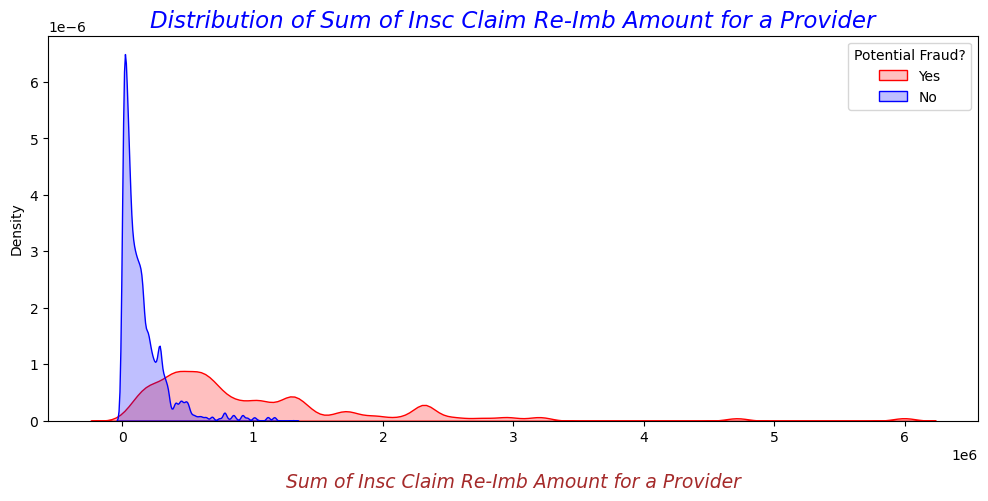

In [112]:
plt.figure(figsize = [12,5])
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'Yes']['PRV_Insc_Clm_ReImb_Amt'], color='red',shade = True)
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'No']['PRV_Insc_Clm_ReImb_Amt'], color='blue', shade=True)
plt.xlabel("\nSum of Insc Claim Re-Imb Amount for a Provider", fontdict=label_font_dict)
plt.title("Distribution of Sum of Insc Claim Re-Imb Amount for a Provider", fontdict=title_font_dict)
plt.legend(labels=["Yes", "No"], title="Potential Fraud?");

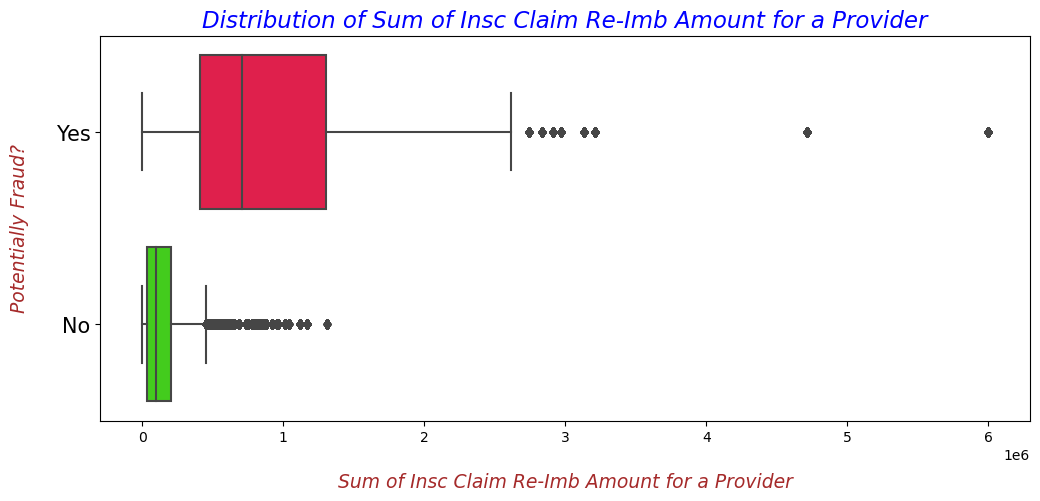

In [113]:
plt.figure(figsize = [12,5])
fig = sns.boxplot(data=train_iobp_df, y='PotentialFraud', x='PRV_Insc_Clm_ReImb_Amt', palette='prism_r', orient='h')   
plt.ylabel("Potentially Fraud?\n", fontdict=label_font_dict)
plt.yticks(fontsize=15)
plt.xlabel("\nSum of Insc Claim Re-Imb Amount for a Provider", fontdict=label_font_dict)
plt.title("Distribution of Sum of Insc Claim Re-Imb Amount for a Provider", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above KDE and Box plots suggest that if `PRV_Insc_Clm_ReImb_Amt` is high then it increases the chances of fraud.

### **Adding `New Feature` :: `Total number of RKD Patients seen by a Provider`**
   
   * **`Reasoning`** :: The idea behind adding this feature is that there might be a pattern like if the total number of RKD Patients seen by a Provider is very high or low then it might influence the fraud.

In [114]:
train_iobp_df['RenalDiseaseIndicator'] = train_iobp_df['RenalDiseaseIndicator'].apply(lambda val: 1 if val == "Y" else 0)

In [115]:
train_iobp_df['PRV_Tot_RKD_Patients'] = train_iobp_df.groupby(['Provider'])['RenalDiseaseIndicator'].transform('sum')

In [116]:
train_iobp_df['PRV_Tot_RKD_Patients'].describe()

count    558211.000000
mean        157.902616
std         233.828365
min           0.000000
25%          24.000000
50%          73.000000
75%         192.000000
max        1447.000000
Name: PRV_Tot_RKD_Patients, dtype: float64

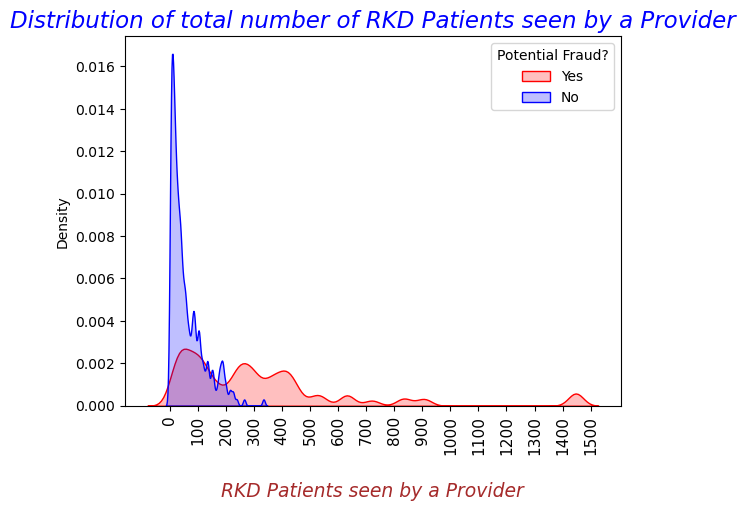

In [117]:
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'Yes']['PRV_Tot_RKD_Patients'], color='red',shade= True)
sns.kdeplot(x=train_iobp_df[train_iobp_df['PotentialFraud'] == 'No']['PRV_Tot_RKD_Patients'], color='blue',shade =True)
plt.xlabel("\nRKD Patients seen by a Provider", fontdict=label_font_dict)
plt.xticks(np.arange(0,1600,100), rotation=90, fontsize=11)
plt.title("Distribution of total number of RKD Patients seen by a Provider", fontdict=title_font_dict)
plt.legend(labels=["Yes", "No"], title="Potential Fraud?")
plt.show()

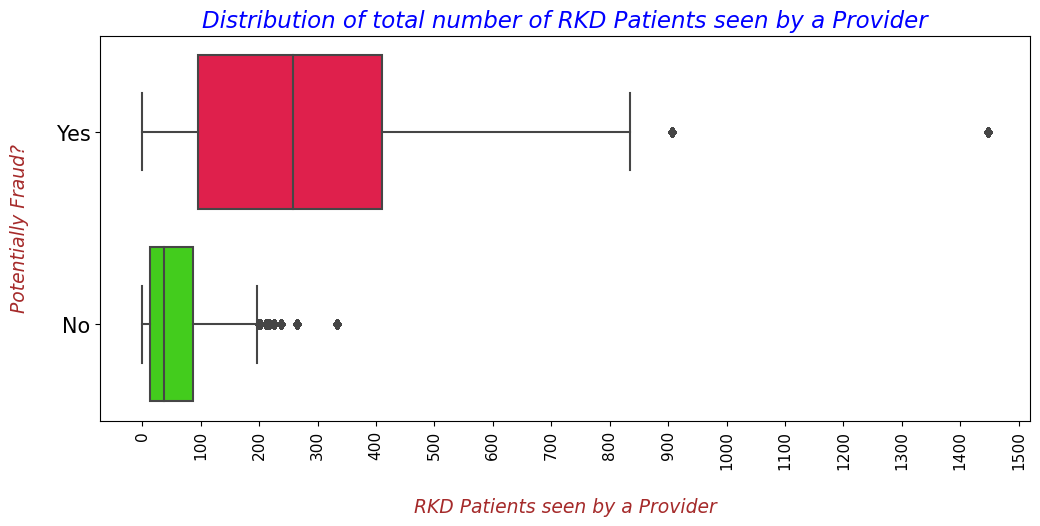

In [118]:
plt.figure(figsize = [12,5])
fig = sns.boxplot(data=train_iobp_df, y='PotentialFraud', x='PRV_Tot_RKD_Patients', palette='prism_r', orient='h')   
plt.ylabel("Potentially Fraud?\n", fontdict=label_font_dict)
plt.yticks(fontsize=15)
plt.xticks(np.arange(0,1600,100), rotation=90, fontsize=11)
plt.xlabel("\nRKD Patients seen by a Provider", fontdict=label_font_dict)
plt.title("Distribution of total number of RKD Patients seen by a Provider", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above KDE and Box plots suggest that if `PRV_Tot_RKD_Patients` is high then it increases the chances of fraud.

# **`Some trends`**

### **Q1. Which are the Top-25 `Providers` with maximum number of fraudulent cases?**

In [119]:
tmp = pd.DataFrame(train_iobp_df.groupby(['Provider','PotentialFraud'])['BeneID'].count()).reset_index()
tmp.columns = ['Provider', 'Fraud?', 'Num_of_cases']
tot_fraud_cases = tmp[tmp['Fraud?'] == 'Yes']['Num_of_cases'].sum()
tot_non_fraud_cases = tmp[tmp['Fraud?'] == 'No']['Num_of_cases'].sum()
tmp['Cases'] = tmp['Fraud?'].apply(lambda val: tot_non_fraud_cases if val == "No" else tot_fraud_cases)
tmp['Percentage'] = round(((tmp['Num_of_cases'] / tmp['Cases']) * 100),2)

tmp.head()

,Provider,Fraud?,Num_of_cases,Cases,Percentage
0,PRV51001,No,25,345415,0.01
1,PRV51003,Yes,132,212796,0.06
2,PRV51004,No,149,345415,0.04
3,PRV51005,Yes,1165,212796,0.55
4,PRV51007,No,72,345415,0.02


In [120]:
tmp_only_frauds = tmp[tmp['Fraud?'] == 'Yes'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

    Provider  Num_of_cases  Percentage
0   PRV51459          8240        3.87
1   PRV53797          4739        2.23
2   PRV51574          4444        2.09
3   PRV53918          3588        1.69
4   PRV54895          3436        1.61
5   PRV55215          3393        1.59
6   PRV52064          2844        1.34
7   PRV56011          2833        1.33
8   PRV55004          2399        1.13
9   PRV56560          2313        1.09
10  PRV57306          2315        1.09
11  PRV52030          2275        1.07
12  PRV52649          2156        1.01
13  PRV54772          2115        0.99
14  PRV52628          2098        0.99
15  PRV51369          2083        0.98
16  PRV51347          2067        0.97
17  PRV55039          2058        0.97
18  PRV57103          2049        0.96
19  PRV52019          1961        0.92
20  PRV51480          1924        0.90
21  PRV55462          1907        0.90
22  PRV52041          1885        0.89
23  PRV55467          1896        0.89
24  PRV54742          189

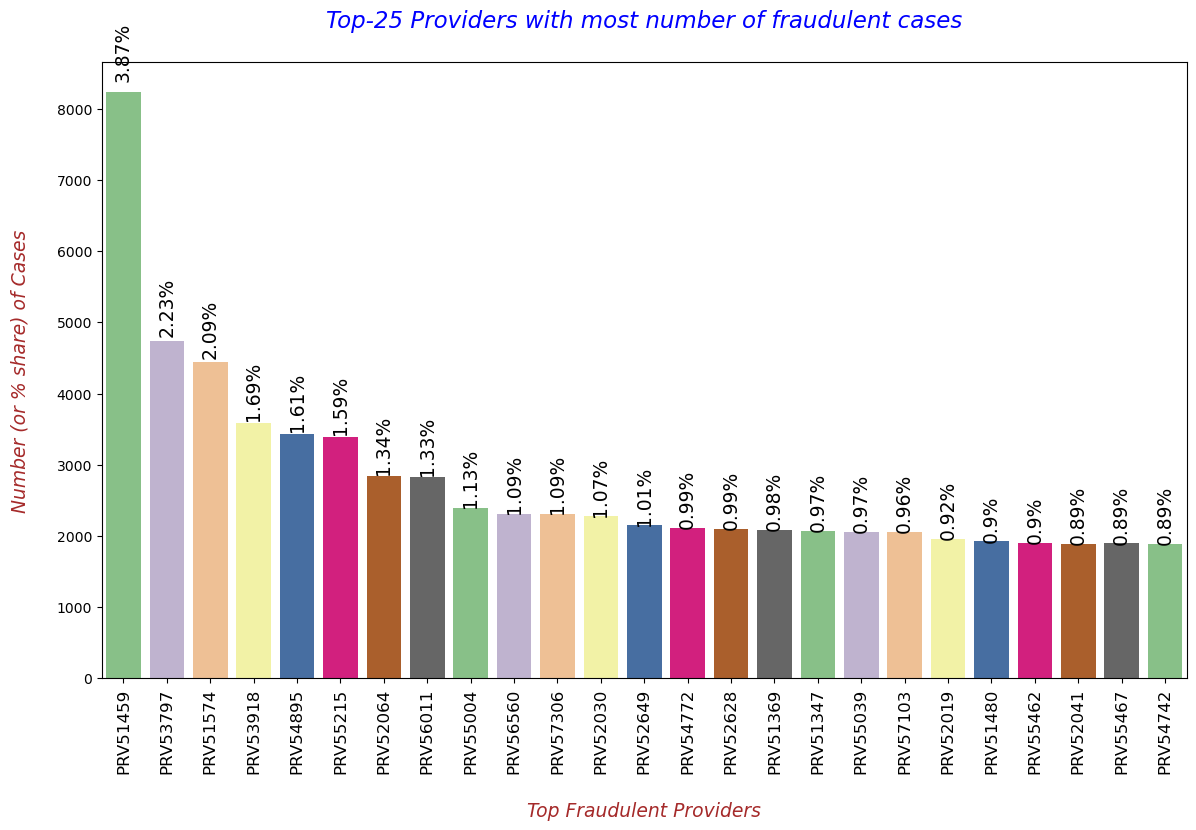

In [121]:
print(tmp_only_frauds[['Provider','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(14,8))
fig = sns.barplot(data=tmp_only_frauds.iloc[0:25], x="Provider", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nTop Fraudulent Providers", fontdict=label_font_dict)
plt.xticks(rotation=90, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Top-25 Providers with most number of fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot shows us the Top-25 Providers with most percentage of Fraudulent Case Submissions.
    * Here, PRV51459 has the highest percentage share of fraudulent cases. The, difference b/w others providers is not that high.

### **Q2. Which are the Top-25 `Providers` with maximum number of non-fraudulent cases?**

In [122]:
tmp_only_non_frauds = tmp[tmp['Fraud?'] == 'No'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

    Provider  Num_of_cases  Percentage
0   PRV53750          1245        0.36
1   PRV55552          1206        0.35
2   PRV53394          1215        0.35
3   PRV53871          1220        0.35
4   PRV52001          1177        0.34
5   PRV52104          1189        0.34
6   PRV56559          1113        0.32
7   PRV56006          1090        0.32
8   PRV54813          1056        0.31
9   PRV52631          1057        0.31
10  PRV51509          1030        0.30
11  PRV56270          1043        0.30
12  PRV54332           995        0.29
13  PRV52605          1000        0.29
14  PRV53702          1010        0.29
15  PRV57333          1004        0.29
16  PRV55525           933        0.27
17  PRV56248           934        0.27
18  PRV57348           920        0.27
19  PRV52395           912        0.26
20  PRV56243           909        0.26
21  PRV52859           911        0.26
22  PRV53700           913        0.26
23  PRV55510           861        0.25
24  PRV54374           85

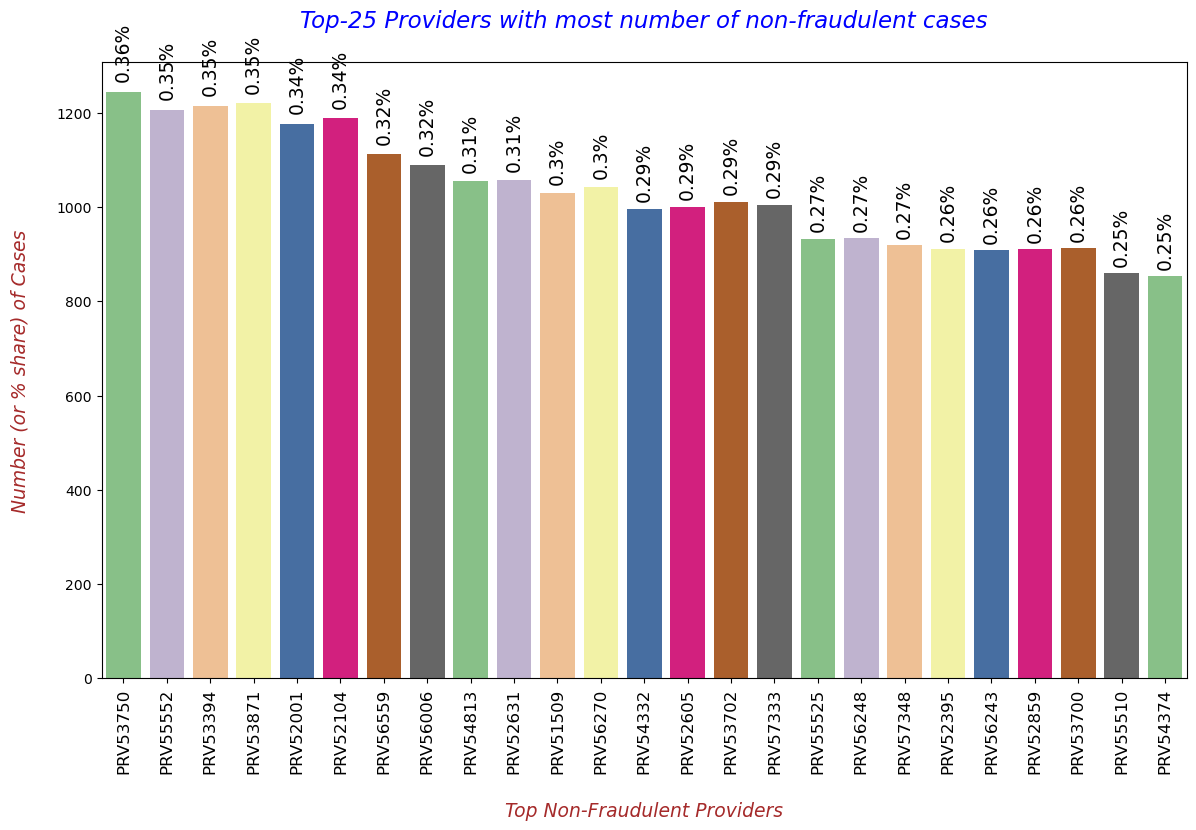

In [123]:
print(tmp_only_non_frauds[['Provider','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(14,8))
fig = sns.barplot(data=tmp_only_non_frauds.iloc[0:25], x="Provider", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_non_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nTop Non-Fraudulent Providers", fontdict=label_font_dict)
plt.xticks(rotation=90, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Top-25 Providers with most number of non-fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot shows us the Top-25 Providers with most percentage of Non-Fraudulent Case Submissions.
    * Here, PRV53750 has the highest percentage share of non-fraudulent cases. But, the difference with other providers is not so high.

### **Q3. Which are the Top-25 `Attending Physicians` with maximum number of fraudulent cases?**

In [124]:
tmp = pd.DataFrame(train_iobp_df.groupby(['AttendingPhysician','PotentialFraud'])['BeneID'].count()).reset_index()
tmp.columns = ['AttendingPhysician', 'Fraud?', 'Num_of_cases']
tot_fraud_cases = tmp[tmp['Fraud?'] == 'Yes']['Num_of_cases'].sum()
tot_non_fraud_cases = tmp[tmp['Fraud?'] == 'No']['Num_of_cases'].sum()
tmp['Cases'] = tmp['Fraud?'].apply(lambda val: tot_non_fraud_cases if val == "No" else tot_fraud_cases)
tmp['Percentage'] = round(((tmp['Num_of_cases'] / tmp['Cases']) * 100),2)

tmp.head()

,AttendingPhysician,Fraud?,Num_of_cases,Cases,Percentage
0,PHY311001,No,2,344471,0.0
1,PHY311002,Yes,1,212232,0.0
2,PHY311004,No,2,344471,0.0
3,PHY311005,No,2,344471,0.0
4,PHY311006,No,1,344471,0.0


In [125]:
tmp_only_frauds = tmp[tmp['Fraud?'] == 'Yes'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

   AttendingPhysician  Num_of_cases  Percentage
0           PHY330576          2534        1.19
1           PHY350277          1628        0.77
2           PHY412132          1321        0.62
3           PHY423534          1223        0.58
4           PHY314027          1200        0.57
5           PHY327046          1181        0.56
6           PHY338032          1158        0.55
7           PHY357120          1156        0.54
8           PHY337425          1156        0.54
9           PHY341578          1133        0.53
10          PHY432650          1093        0.52
11          PHY347064          1076        0.51
12          PHY344389          1000        0.47
13          PHY383481          1005        0.47
14          PHY415321          1002        0.47
15          PHY433436           924        0.44
16          PHY375453           880        0.41
17          PHY387126           762        0.36
18          PHY357307           737        0.35
19          PHY318667           711     

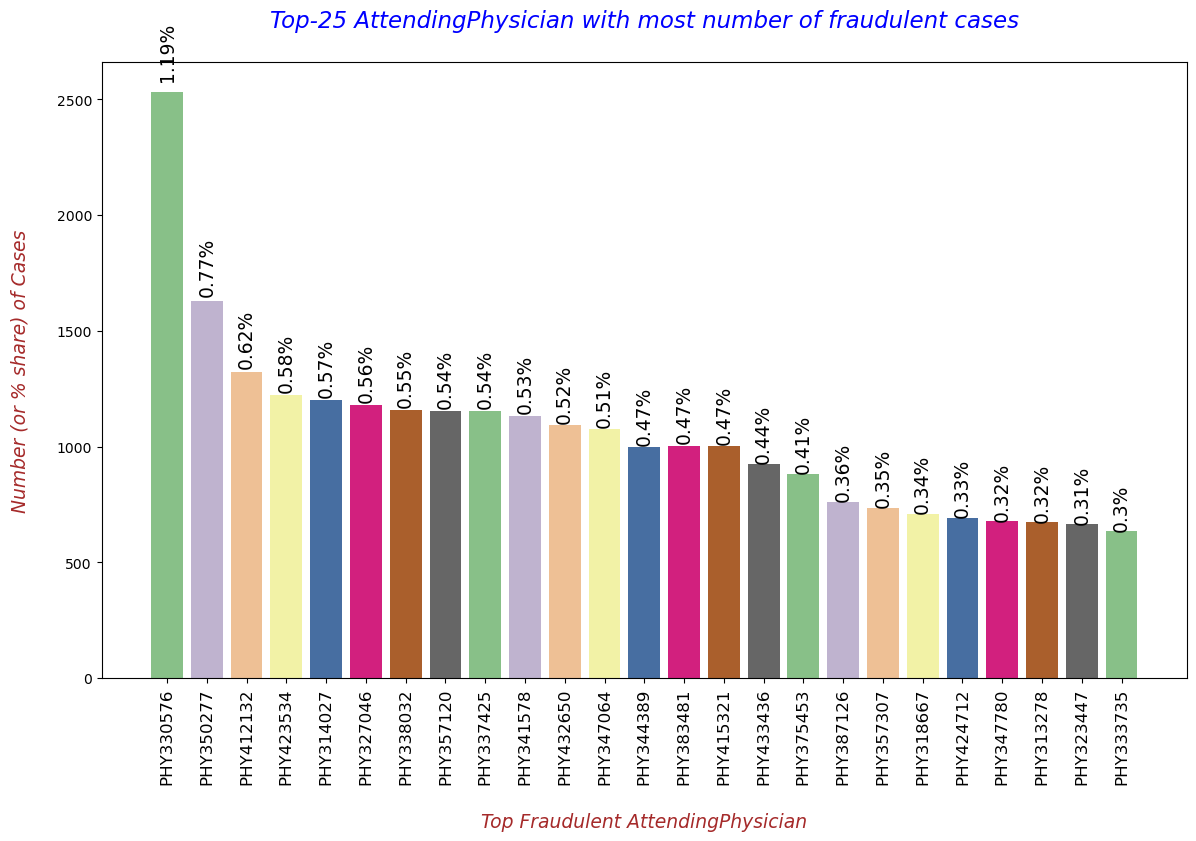

In [126]:
print(tmp_only_frauds[['AttendingPhysician','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(14,8))
fig = sns.barplot(data=tmp_only_frauds.iloc[0:25], x="AttendingPhysician", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nTop Fraudulent AttendingPhysician", fontdict=label_font_dict)
plt.xticks(rotation=90, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Top-25 AttendingPhysician with most number of fraudulent cases\n", fontdict=title_font_dict)
plt.plot();

**`OBSERVATION`**
* The above plot shows us the Top-25 Attenting Physicians with most percentage of Fraudulent Case Submissions.
    * Here, PHY330576 has the highest percentage share of fraudulent cases. But, the difference b/w other physicians is not so high.

### **Q4. Which are the Top-25 `Attenting Physicians` with maximum number of non-fraudulent cases?**

In [127]:
tmp_only_non_frauds = tmp[tmp['Fraud?'] == 'No'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

   AttendingPhysician  Num_of_cases  Percentage
0           PHY351121          1053        0.31
1           PHY375943           912        0.26
2           PHY432614           716        0.21
3           PHY389456           673        0.20
4           PHY326984           686        0.20
5           PHY362889           674        0.20
6           PHY373032           618        0.18
7           PHY367255           634        0.18
8           PHY356444           600        0.17
9           PHY360179           583        0.17
10          PHY405720           544        0.16
11          PHY342223           503        0.15
12          PHY387900           514        0.15
13          PHY430054           513        0.15
14          PHY361063           470        0.14
15          PHY326049           445        0.13
16          PHY388040           447        0.13
17          PHY351973           426        0.12
18          PHY318242           422        0.12
19          PHY328307           402     

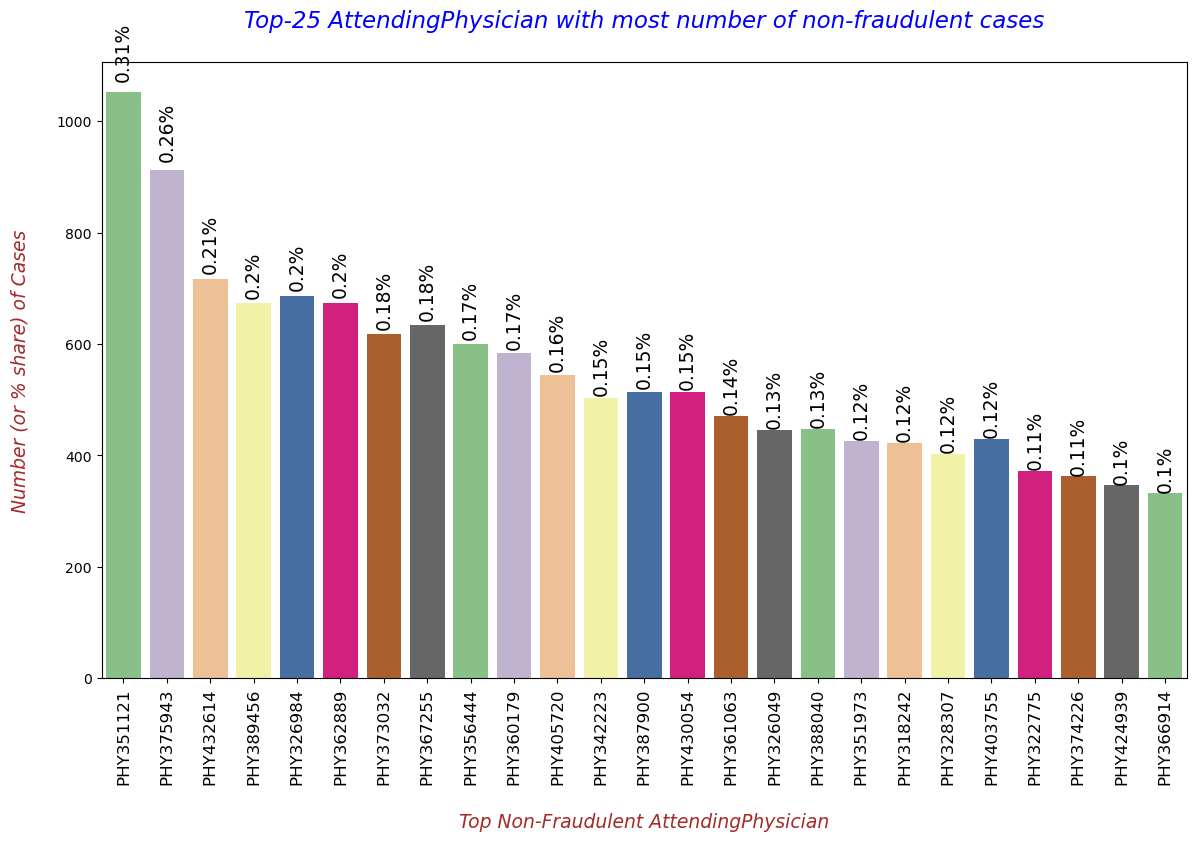

In [128]:
print(tmp_only_non_frauds[['AttendingPhysician','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(14,8))
fig = sns.barplot(data=tmp_only_non_frauds.iloc[0:25], x="AttendingPhysician", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_non_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nTop Non-Fraudulent AttendingPhysician", fontdict=label_font_dict)
plt.xticks(rotation=90, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Top-25 AttendingPhysician with most number of non-fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot shows us the Top-25 Attenting Physicians with most percentage of Non-Fraudulent Case Submissions.
    * Here, PHY351121 has the highest percentage share of non-fraudulent cases. But, the difference with other providers is not so high.

### **Q5. Which are the Top-25 `Operating Physicians` with maximum number of fraudulent cases?**

In [129]:
tmp = pd.DataFrame(train_iobp_df.groupby(['OperatingPhysician','PotentialFraud'])['BeneID'].count()).reset_index()
tmp.columns = ['OperatingPhysician', 'Fraud?', 'Num_of_cases']
tot_fraud_cases = tmp[tmp['Fraud?'] == 'Yes']['Num_of_cases'].sum()
tot_non_fraud_cases = tmp[tmp['Fraud?'] == 'No']['Num_of_cases'].sum()
tmp['Cases'] = tmp['Fraud?'].apply(lambda val: tot_non_fraud_cases if val == "No" else tot_fraud_cases)
tmp['Percentage'] = round(((tmp['Num_of_cases'] / tmp['Cases']) * 100),2)

tmp.head()

,OperatingPhysician,Fraud?,Num_of_cases,Cases,Percentage
0,PHY311005,No,1,67497,0.00
1,PHY311010,No,1,67497,0.00
2,PHY311011,Yes,5,46950,0.01
3,PHY311014,No,3,67497,0.00
4,PHY311018,No,2,67497,0.00


In [130]:
tmp_only_frauds = tmp[tmp['Fraud?'] == 'Yes'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

   OperatingPhysician  Num_of_cases  Percentage
0           PHY330576           424        0.90
1           PHY424897           293        0.62
2           PHY314027           256        0.55
3           PHY423534           250        0.53
4           PHY357120           249        0.53
5           PHY412132           245        0.52
6           PHY327046           236        0.50
7           PHY381249           231        0.49
8           PHY333735           232        0.49
9           PHY341578           224        0.48
10          PHY429430           225        0.48
11          PHY337425           226        0.48
12          PHY383481           191        0.41
13          PHY347064           189        0.40
14          PHY432650           178        0.38
15          PHY344389           171        0.36
16          PHY415321           165        0.35
17          PHY433436           159        0.34
18          PHY341560           154        0.33
19          PHY387026           143     

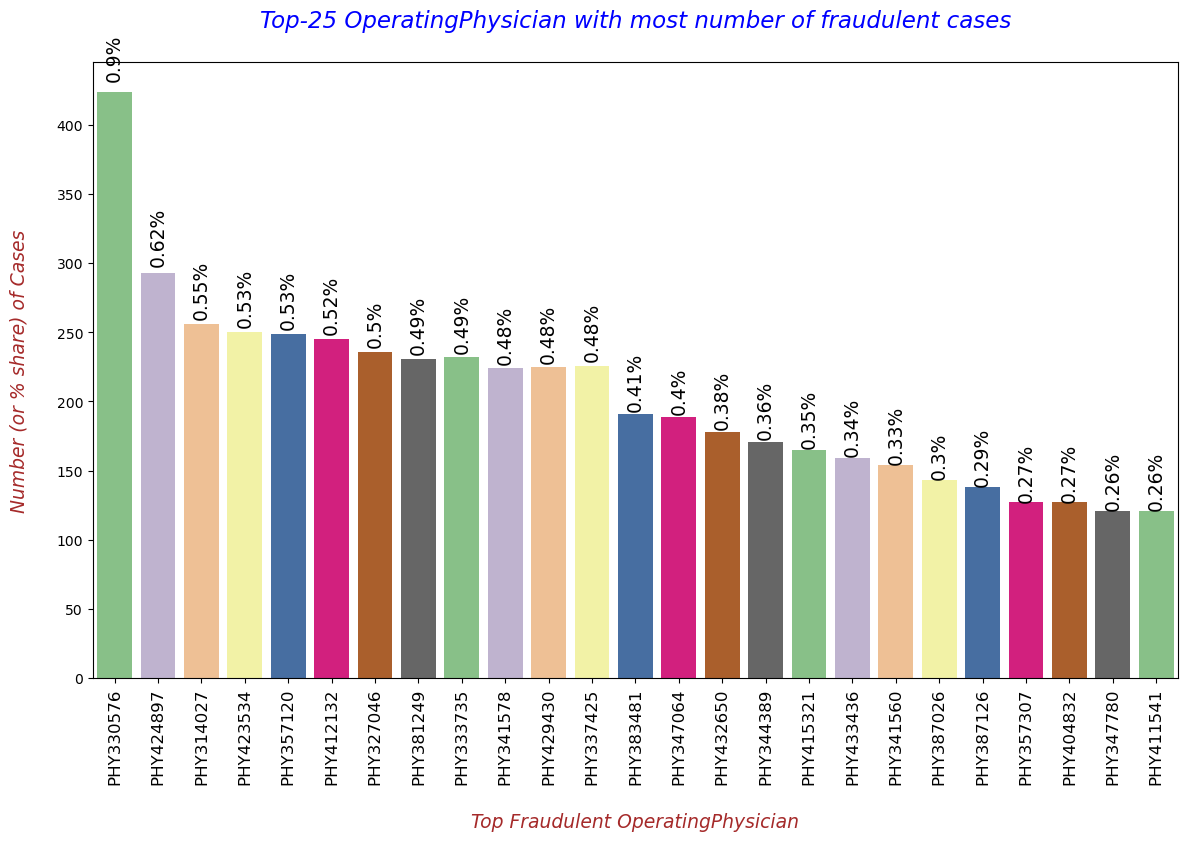

In [131]:
print(tmp_only_frauds[['OperatingPhysician','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(14,8))
fig = sns.barplot(data=tmp_only_frauds.iloc[0:25], x="OperatingPhysician", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nTop Fraudulent OperatingPhysician", fontdict=label_font_dict)
plt.xticks(rotation=90, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Top-25 OperatingPhysician with most number of fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot shows us the Top-25 Operating Physicians with most percentage of Fraudulent Case Submissions.
    * Here, PHY330576 has the highest percentage share of fraudulent cases. But, the difference b/w other providers is not so high.

### **Q6. Which are the Top-25 `Operating Physicians` with maximum number of non-fraudulent cases?**

In [132]:
tmp_only_non_frauds = tmp[tmp['Fraud?'] == 'No'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

   OperatingPhysician  Num_of_cases  Percentage
0           PHY387900           180        0.27
1           PHY351121           179        0.27
2           PHY375943           147        0.22
3           PHY367255           132        0.20
4           PHY432614           129        0.19
5           PHY362889           122        0.18
6           PHY326984           121        0.18
7           PHY356444           108        0.16
8           PHY360179            98        0.15
9           PHY405720            96        0.14
10          PHY373032            97        0.14
11          PHY321493            88        0.13
12          PHY342223            89        0.13
13          PHY318242            85        0.13
14          PHY319973            89        0.13
15          PHY326049            81        0.12
16          PHY366914            79        0.12
17          PHY361063            84        0.12
18          PHY388040            82        0.12
19          PHY322775            71     

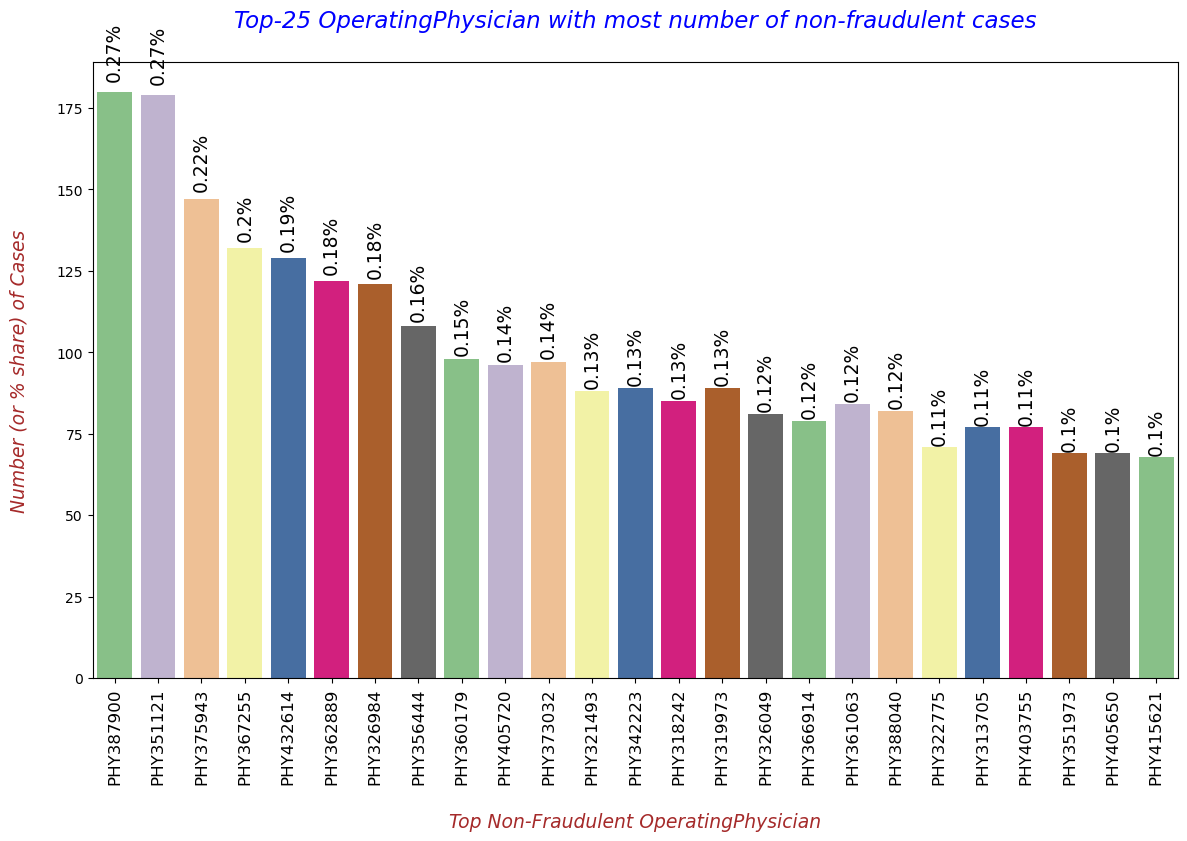

In [133]:
print(tmp_only_non_frauds[['OperatingPhysician','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(14,8))
fig = sns.barplot(data=tmp_only_non_frauds.iloc[0:25], x="OperatingPhysician", y="Num_of_cases", palette='Accent')

for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_non_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nTop Non-Fraudulent OperatingPhysician", fontdict=label_font_dict)
plt.xticks(rotation=90, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Top-25 OperatingPhysician with most number of non-fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot shows us the Top-25 Operating Physicians with most percentage of Non-Fraudulent Case Submissions.
    * Here, PHY387900 and PHY351121 has the highest percentage share of non-fraudulent cases. But, the difference b/w providers is not so high.

### **Q7. Which are the Top-25 `Other Physicians` with maximum number of fraudulent cases?**

In [134]:
tmp = pd.DataFrame(train_iobp_df.groupby(['OtherPhysician','PotentialFraud'])['BeneID'].count()).reset_index()
tmp.columns = ['OtherPhysician', 'Fraud?', 'Num_of_cases']
tot_fraud_cases = tmp[tmp['Fraud?'] == 'Yes']['Num_of_cases'].sum()
tot_non_fraud_cases = tmp[tmp['Fraud?'] == 'No']['Num_of_cases'].sum()
tmp['Cases'] = tmp['Fraud?'].apply(lambda val: tot_non_fraud_cases if val == "No" else tot_fraud_cases)
tmp['Percentage'] = round(((tmp['Num_of_cases'] / tmp['Cases']) * 100),2)

tmp.head()

,OtherPhysician,Fraud?,Num_of_cases,Cases,Percentage
0,PHY311001,No,1,125093,0.0
1,PHY311003,Yes,2,74643,0.0
2,PHY311005,No,2,125093,0.0
3,PHY311006,No,3,125093,0.0
4,PHY311007,Yes,1,74643,0.0


In [135]:
tmp_only_frauds = tmp[tmp['Fraud?'] == 'Yes'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

   OtherPhysician  Num_of_cases  Percentage
0       PHY412132          1247        1.67
1       PHY341578          1098        1.47
2       PHY338032          1070        1.43
3       PHY337425          1041        1.39
4       PHY347064           806        1.08
5       PHY322092           771        1.03
6       PHY409965           744        1.00
7       PHY313818           730        0.98
8       PHY350277           682        0.91
9       PHY415321           678        0.91
10      PHY313278           625        0.84
11      PHY359122           614        0.82
12      PHY416093           538        0.72
13      PHY333735           496        0.66
14      PHY421058           432        0.58
15      PHY359931           414        0.55
16      PHY396637           400        0.54
17      PHY327964           371        0.50
18      PHY336024           372        0.50
19      PHY315344           363        0.49
20      PHY410597           357        0.48
21      PHY416732           356 

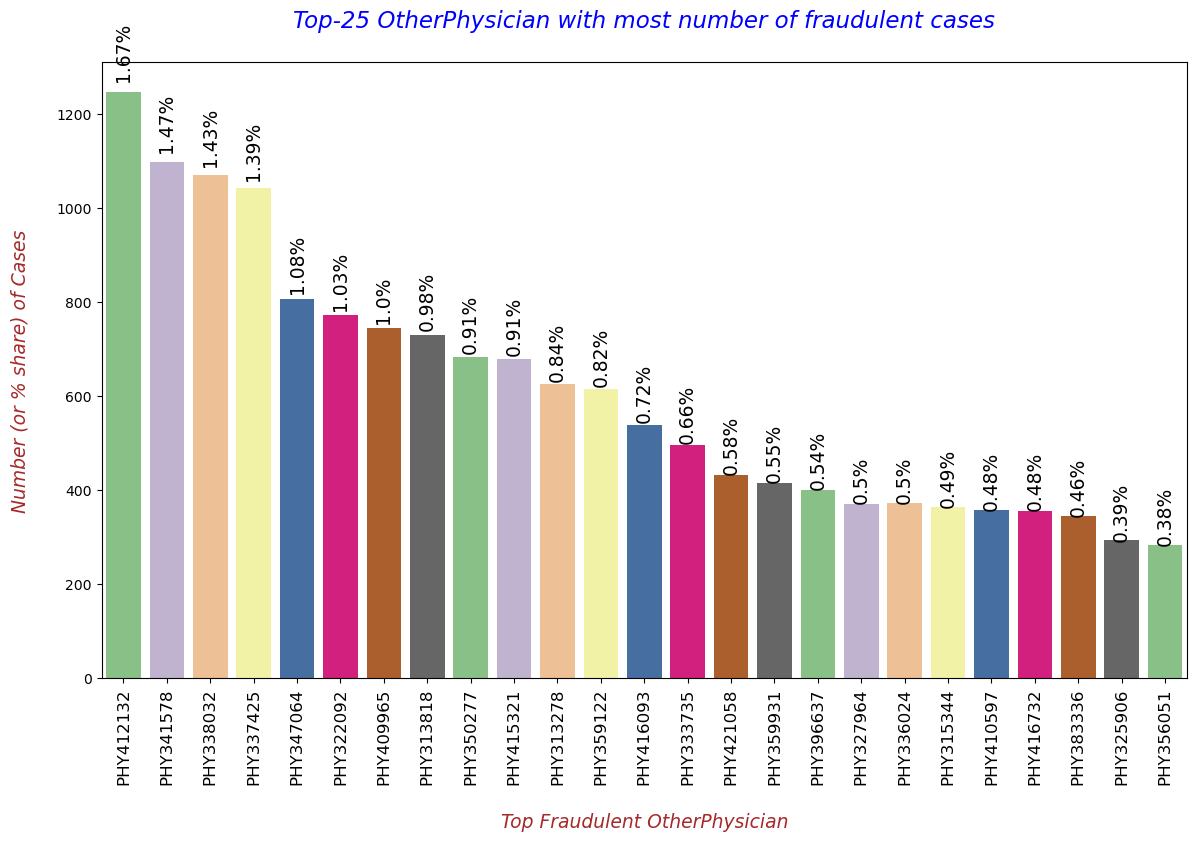

In [136]:
print(tmp_only_frauds[['OtherPhysician','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(14,8))
fig = sns.barplot(data=tmp_only_frauds.iloc[0:25], x="OtherPhysician", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nTop Fraudulent OtherPhysician", fontdict=label_font_dict)
plt.xticks(rotation=90, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Top-25 OtherPhysician with most number of fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot shows us the Top-25 Other Physicians with most percentage of Fraudulent Case Submissions.
    * Here, PHY412132 has the highest percentage share of fraudulent cases. But, the difference with other providers is not so high.

### **Q8. Which are the Top-25 `Other Physicians` with maximum number of non-fraudulent cases?**

In [137]:
tmp_only_non_frauds = tmp[tmp['Fraud?'] == 'No'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

   OtherPhysician  Num_of_cases  Percentage
0       PHY422235           369        0.29
1       PHY387900           351        0.28
2       PHY375943           328        0.26
3       PHY411722           313        0.25
4       PHY363309           305        0.24
5       PHY331484           295        0.24
6       PHY362889           294        0.24
7       PHY326984           292        0.23
8       PHY367255           269        0.22
9       PHY389456           271        0.22
10      PHY356444           258        0.21
11      PHY382485           249        0.20
12      PHY315424           243        0.19
13      PHY405720           220        0.18
14      PHY354358           217        0.17
15      PHY323501           202        0.16
16      PHY403755           196        0.16
17      PHY384394           196        0.16
18      PHY388477           197        0.16
19      PHY395822           195        0.16
20      PHY326286           189        0.15
21      PHY415621           182 

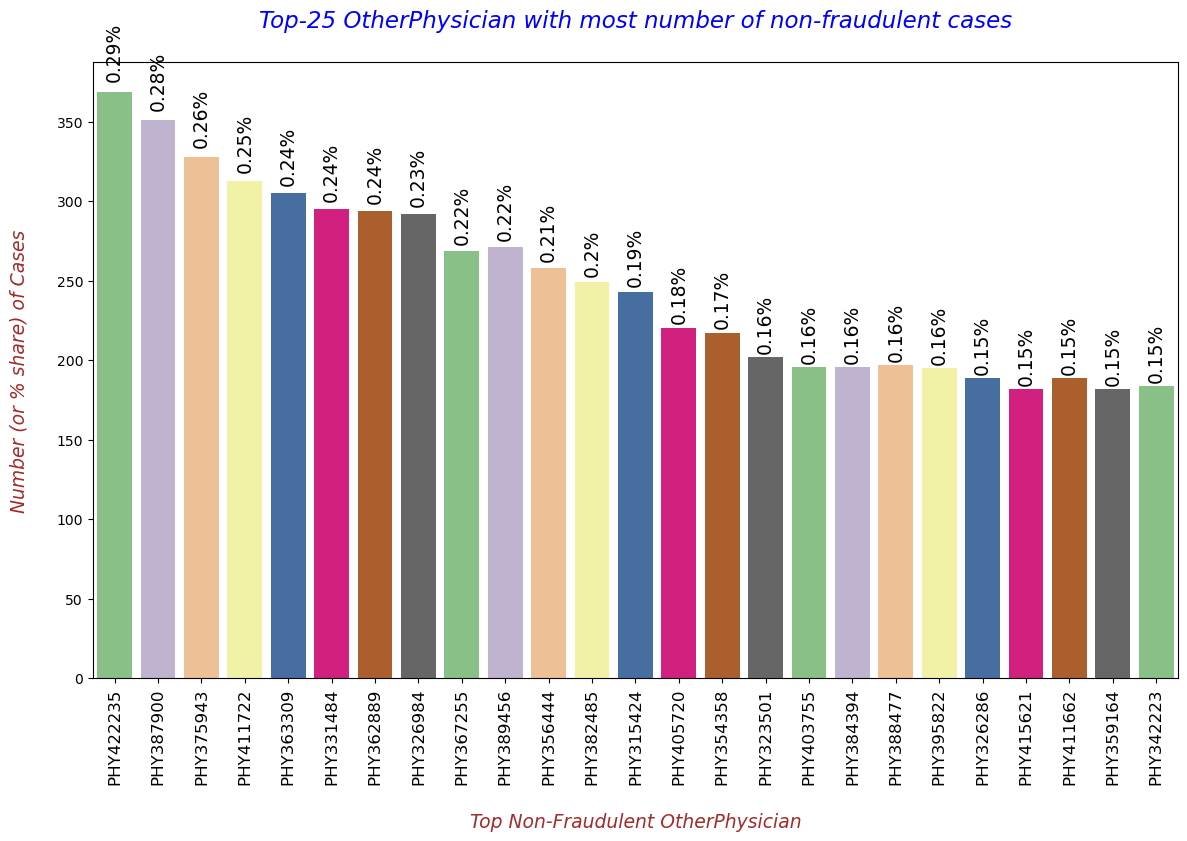

In [138]:
print(tmp_only_non_frauds[['OtherPhysician','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(14,8))
fig = sns.barplot(data=tmp_only_non_frauds.iloc[0:25], x="OtherPhysician", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_non_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nTop Non-Fraudulent OtherPhysician", fontdict=label_font_dict)
plt.xticks(rotation=90, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Top-25 OtherPhysician with most number of non-fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot shows us the Top-25 Other Physicians with most percentage of Non-Fraudulent Case Submissions.
    * Here, PHY422235 has the highest percentage share of non-fraudulent cases. But, the difference with other providers is not so high.

### **Q9. Which are the Top-25 `ClmAdmitDiagnosisCode` with maximum number of fraudulent cases?**

In [139]:
tmp = pd.DataFrame(train_iobp_df.groupby(['ClmAdmitDiagnosisCode','PotentialFraud'])['BeneID'].count()).reset_index()
tmp.columns = ['ClmAdmitDiagnosisCode', 'Fraud?', 'Num_of_cases']
tot_fraud_cases = tmp[tmp['Fraud?'] == 'Yes']['Num_of_cases'].sum()
tot_non_fraud_cases = tmp[tmp['Fraud?'] == 'No']['Num_of_cases'].sum()
tmp['Cases'] = tmp['Fraud?'].apply(lambda val: tot_non_fraud_cases if val == "No" else tot_fraud_cases)
tmp['Percentage'] = round(((tmp['Num_of_cases'] / tmp['Cases']) * 100),2)

tmp.head()

,ClmAdmitDiagnosisCode,Fraud?,Num_of_cases,Cases,Percentage
0,0030,No,1,83850,0.00
1,0030,Yes,1,62049,0.00
2,0059,No,1,83850,0.00
3,0059,Yes,2,62049,0.00
4,00845,No,31,83850,0.04


In [140]:
tmp_only_frauds = tmp[tmp['Fraud?'] == 'Yes'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

   ClmAdmitDiagnosisCode  Num_of_cases  Percentage
0                  42731          1529        2.46
1                  V7612          1441        2.32
2                  78605          1432        2.31
3                  78650          1191        1.92
4                  78900          1020        1.64
5                   4019          1006        1.62
6                  25000           873        1.41
7                    486           843        1.36
8                  78079           828        1.33
9                   7802           793        1.28
10                  7295           740        1.19
11                  5990           703        1.13
12                 V5883           691        1.11
13                  4280           661        1.07
14                  7242           600        0.97
15                  7862           593        0.96
16                 V5789           573        0.92
17                 V5861           556        0.90
18                  2724       

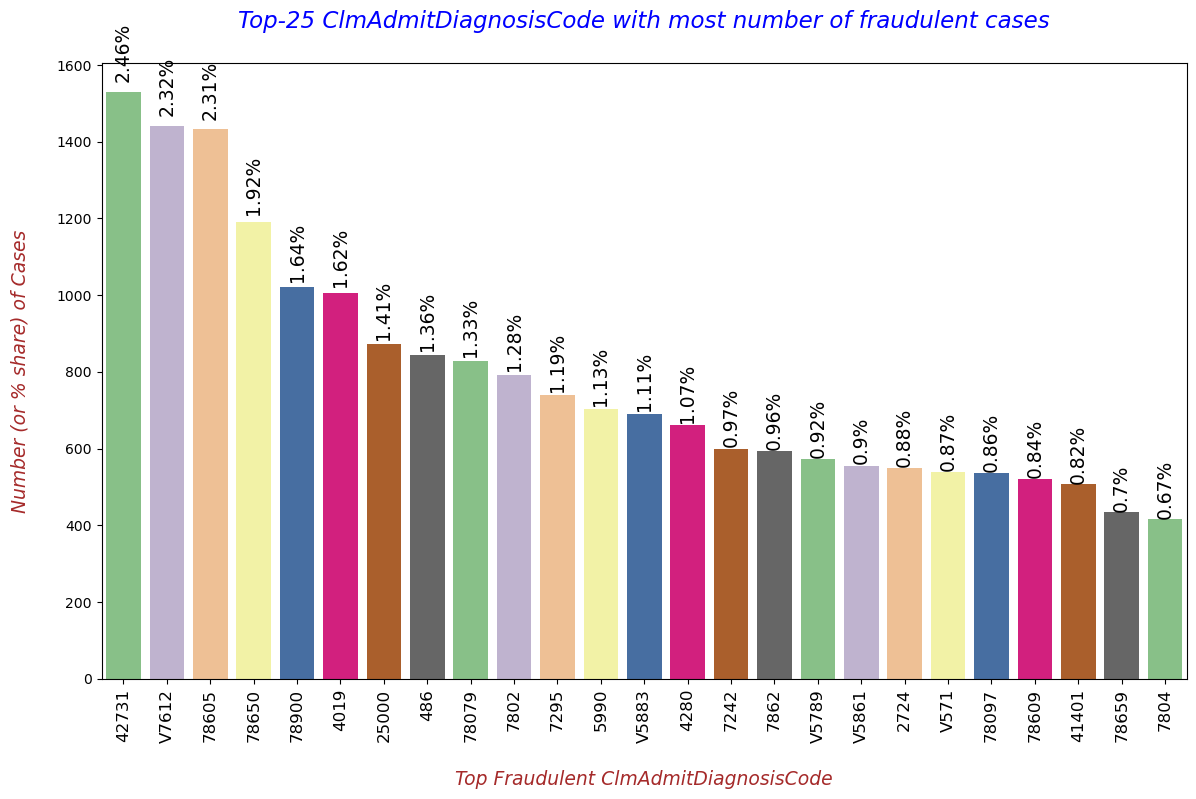

In [141]:
print(tmp_only_frauds[['ClmAdmitDiagnosisCode','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(14,8))
fig = sns.barplot(data=tmp_only_frauds.iloc[0:25], x="ClmAdmitDiagnosisCode", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nTop Fraudulent ClmAdmitDiagnosisCode", fontdict=label_font_dict)
plt.xticks(rotation=90, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Top-25 ClmAdmitDiagnosisCode with most number of fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot shows us the Top-25 'Claim Admit Diagnosis Code' with most percentage of Fraudulent Case Submissions.

### **Q10. Which are the Top-25 `ClmAdmitDiagnosisCode` with maximum number of non-fraudulent cases?**

In [142]:
tmp_only_non_frauds = tmp[tmp['Fraud?'] == 'No'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

   ClmAdmitDiagnosisCode  Num_of_cases  Percentage
0                  V7612          2633        3.14
1                  42731          2105        2.51
2                   4019          1726        2.06
3                  78605          1560        1.86
4                  25000          1495        1.78
5                  78900          1316        1.57
6                  V5883          1182        1.41
7                   7295          1104        1.32
8                  78650          1082        1.29
9                   7242           997        1.19
10                 V5861           980        1.17
11                  2724           958        1.14
12                 78079           951        1.13
13                  5990           922        1.10
14                  V571           905        1.08
15                  7862           868        1.04
16                  7802           820        0.98
17                  4011           660        0.79
18                   486       

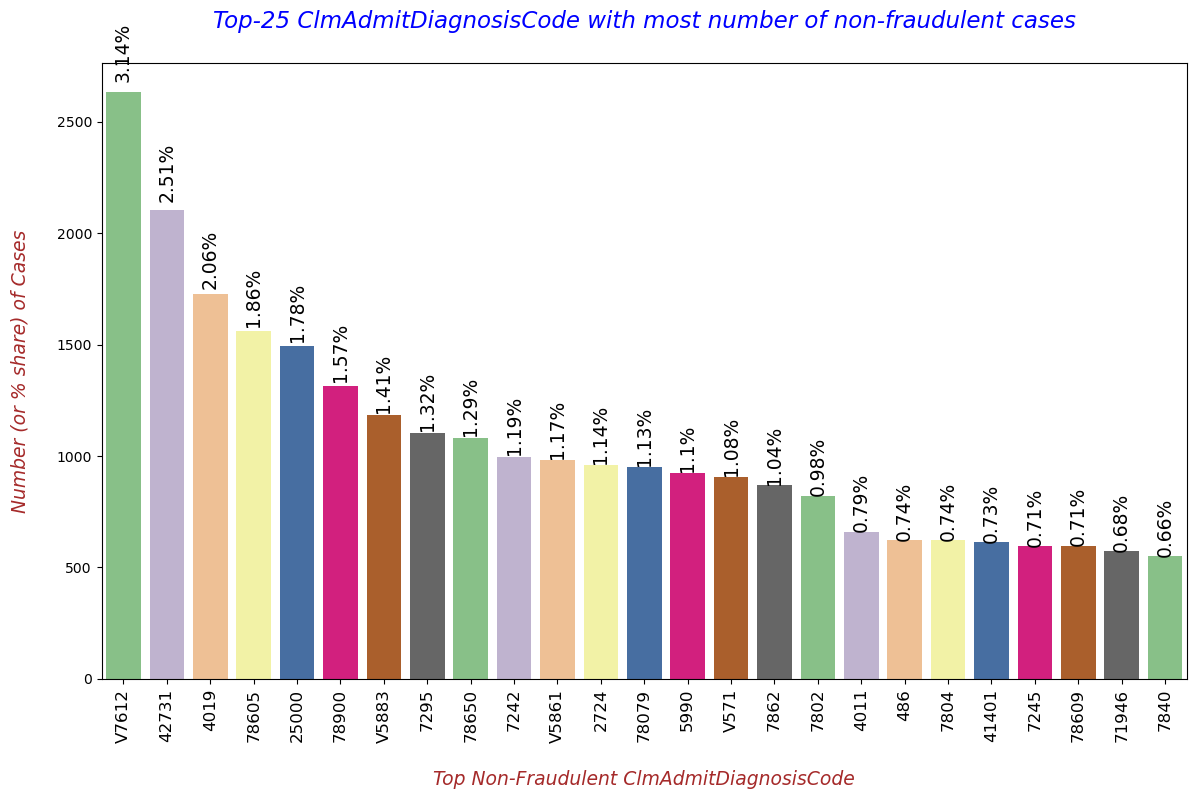

In [143]:
print(tmp_only_non_frauds[['ClmAdmitDiagnosisCode','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(14,8))
fig = sns.barplot(data=tmp_only_non_frauds.iloc[0:25], x="ClmAdmitDiagnosisCode", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_non_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nTop Non-Fraudulent ClmAdmitDiagnosisCode", fontdict=label_font_dict)
plt.xticks(rotation=90, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Top-25 ClmAdmitDiagnosisCode with most number of non-fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**

* The above plot shows us the Top-25 'Claim Admit Diagnosis Code' with most percentage of Non-Fraudulent Case Submissions.

* Main observation from the above 2 plots is that same `Claim Admit Diagnostic Codes` have similar percentages for false and no-false claims. Therefore, it feels like this feature might not be very useful.

### **Q11. Which are the Top-25 `DiagnosisGroupCode` with maximum number of fraudulent cases?**

In [144]:
tmp = pd.DataFrame(train_iobp_df.groupby(['DiagnosisGroupCode','PotentialFraud'])['BeneID'].count()).reset_index()
tmp.columns = ['DiagnosisGroupCode', 'Fraud?', 'Num_of_cases']
tot_fraud_cases = tmp[tmp['Fraud?'] == 'Yes']['Num_of_cases'].sum()
tot_non_fraud_cases = tmp[tmp['Fraud?'] == 'No']['Num_of_cases'].sum()
tmp['Cases'] = tmp['Fraud?'].apply(lambda val: tot_non_fraud_cases if val == "No" else tot_fraud_cases)
tmp['Percentage'] = round(((tmp['Num_of_cases'] / tmp['Cases']) * 100),2)

tmp.head()

,DiagnosisGroupCode,Fraud?,Num_of_cases,Cases,Percentage
0,000,No,57,17072,0.33
1,000,Yes,77,23402,0.33
2,001,No,2,17072,0.01
3,001,Yes,8,23402,0.03
4,002,No,9,17072,0.05


In [145]:
tmp_only_frauds = tmp[tmp['Fraud?'] == 'Yes'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

   DiagnosisGroupCode  Num_of_cases  Percentage
0                 882           111        0.47
1                 166           107        0.46
2                 186           102        0.44
3                 192            98        0.42
4                 945            95        0.41
5                 884            97        0.41
6                 939            96        0.41
7                 202            95        0.41
8                 883            96        0.41
9                 188            97        0.41
10                168            94        0.40
11                949            94        0.40
12                204            94        0.40
13                885            92        0.39
14                876            90        0.38
15                196            89        0.38
16                198            89        0.38
17                183            89        0.38
18                887            90        0.38
19                950            90     

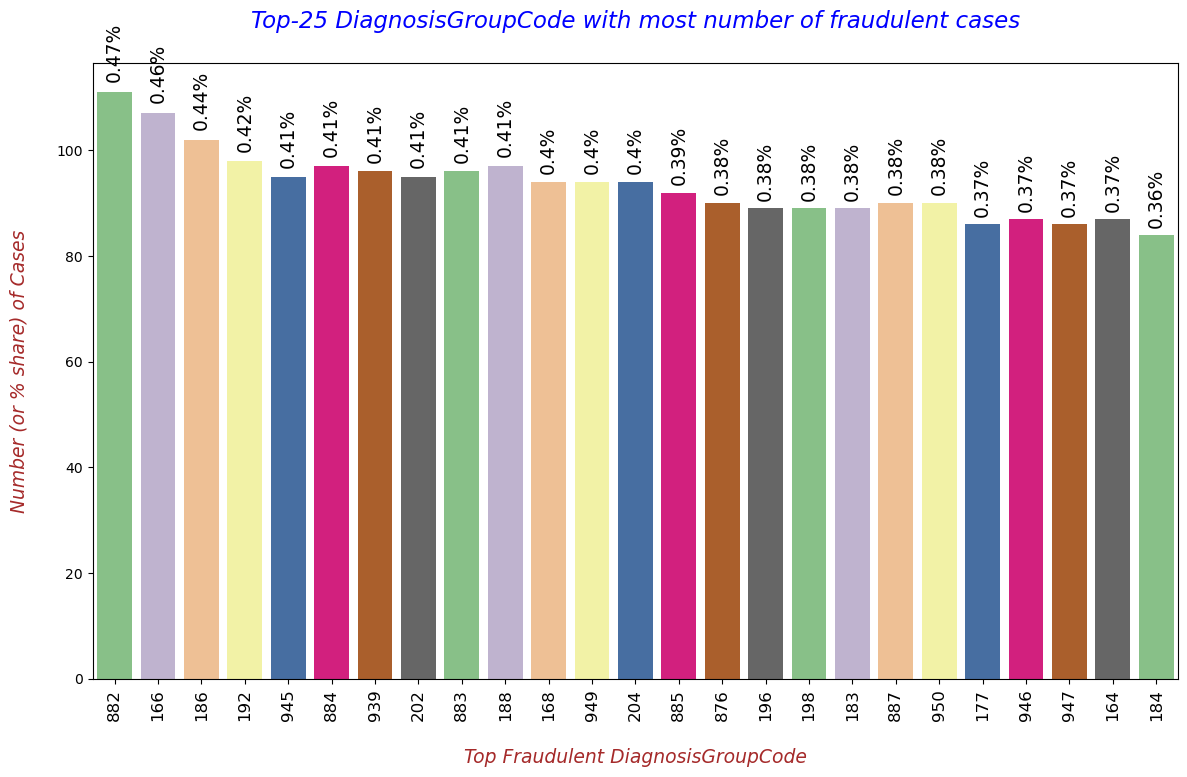

In [146]:
print(tmp_only_frauds[['DiagnosisGroupCode','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(14,8))
fig = sns.barplot(data=tmp_only_frauds.iloc[0:25], x="DiagnosisGroupCode", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nTop Fraudulent DiagnosisGroupCode", fontdict=label_font_dict)
plt.xticks(rotation=90, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Top-25 DiagnosisGroupCode with most number of fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot shows us the Top-25 'Diagnosis Group Code' with most percentage of Fraudulent Case Submissions.

### **Q12. Which are the Top-25 `DiagnosisGroupCode` with maximum number of non-fraudulent cases?**

In [147]:
tmp_only_non_frauds = tmp[tmp['Fraud?'] == 'No'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

   DiagnosisGroupCode  Num_of_cases  Percentage
0                 183            76        0.45
1                 167            76        0.45
2                 884            77        0.45
3                 208            75        0.44
4                 940            70        0.41
5                 881            70        0.41
6                 882            68        0.40
7                 187            69        0.40
8                 887            69        0.40
9                 941            69        0.40
10                939            67        0.39
11                876            66        0.39
12                168            66        0.39
13                182            67        0.39
14                184            65        0.38
15                205            65        0.38
16                206            65        0.38
17                177            64        0.37
18                190            63        0.37
19                283            64     

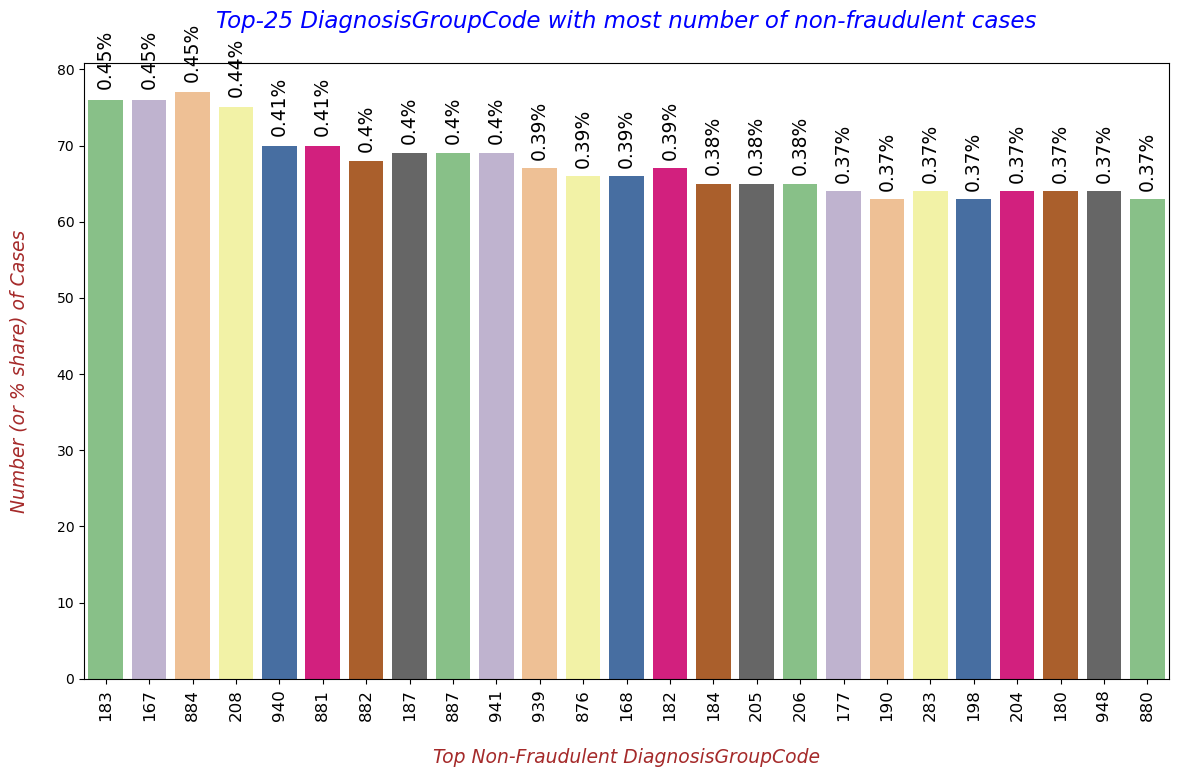

In [148]:
print(tmp_only_non_frauds[['DiagnosisGroupCode','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(14,8))
fig = sns.barplot(data=tmp_only_non_frauds.iloc[0:25], x="DiagnosisGroupCode", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_non_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nTop Non-Fraudulent DiagnosisGroupCode", fontdict=label_font_dict)
plt.xticks(rotation=90, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Top-25 DiagnosisGroupCode with most number of non-fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**

* The above plot shows us the Top-25 'Diagnosis Group Code' with most percentage of Non-Fraudulent Case Submissions.

* Main observation from the above 2 plots is that same `Diagnosis Group Codes` have similar percentages for false and no-false claims. Therefore, it feels like this feature might not be very useful.

### **Q13. Does `Age_groups` have any relationship with maximum number of fraudulent cases?**

In [149]:
def bene_age_brackets(val):
    """
    Description : This function is created for allocating the age groups based on Beneficiary Age.
    """
    if val >=1 and val <=40:
        return 'Young'
    elif val > 40 and val <=60:
        return 'Mid'
    elif val > 60 and val <= 80:
        return 'Old'
    else:
        return 'Very Old'

In [150]:
train_iobp_df['AGE_groups'] = train_iobp_df['Bene_Age'].apply(lambda age: bene_age_brackets(age))

In [151]:
tmp = pd.DataFrame(train_iobp_df.groupby(['AGE_groups','PotentialFraud'])['BeneID'].count()).reset_index()
tmp.columns = ['AGE_groups', 'Fraud?', 'Num_of_cases']
tot_fraud_cases = tmp[tmp['Fraud?'] == 'Yes']['Num_of_cases'].sum()
tot_non_fraud_cases = tmp[tmp['Fraud?'] == 'No']['Num_of_cases'].sum()
tmp['Cases'] = tmp['Fraud?'].apply(lambda val: tot_non_fraud_cases if val == "No" else tot_fraud_cases)
tmp['Percentage'] = round(((tmp['Num_of_cases'] / tmp['Cases']) * 100),2)

tmp.head()

,AGE_groups,Fraud?,Num_of_cases,Cases,Percentage
0,Mid,No,35524,345415,10.28
1,Mid,Yes,21152,212796,9.94
2,Old,No,190334,345415,55.10
3,Old,Yes,116676,212796,54.83
4,Very Old,No,110885,345415,32.10


In [152]:
tmp_only_frauds = tmp[tmp['Fraud?'] == 'Yes'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

  AGE_groups  Num_of_cases  Percentage
0        Old        116676       54.83
1   Very Old         69780       32.79
2        Mid         21152        9.94
3      Young          5188        2.44 



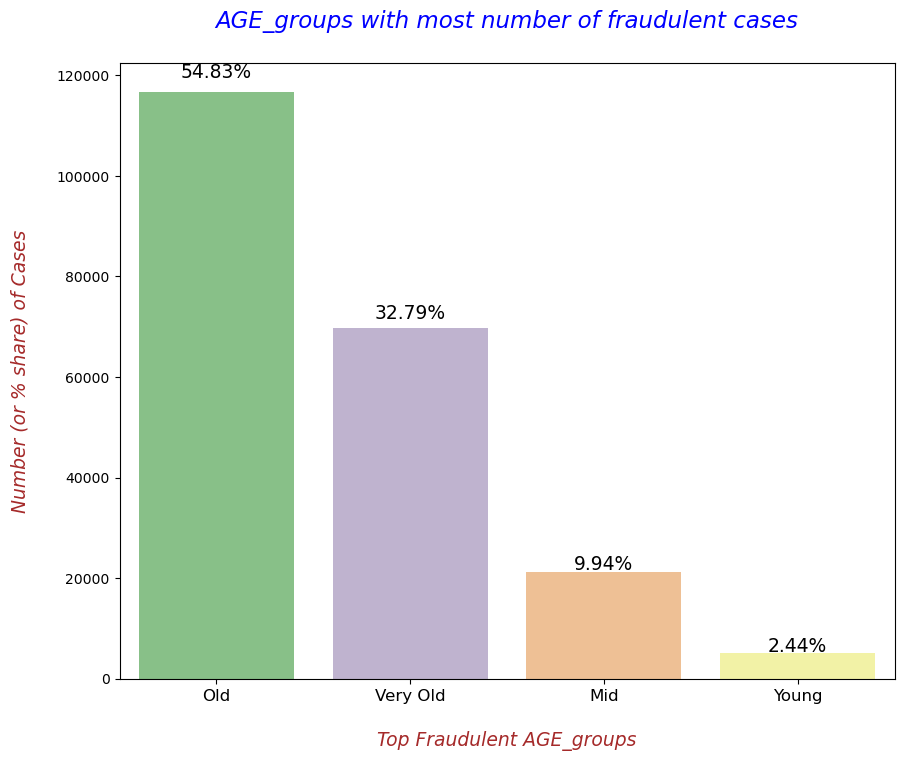

In [153]:
print(tmp_only_frauds[['AGE_groups','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(10,8))
fig = sns.barplot(data=tmp_only_frauds, x="AGE_groups", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=0)

plt.xlabel("\nTop Fraudulent AGE_groups", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("AGE_groups with most number of fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot shows us the percentage of Fraudulent Case Submissions for various Age Groups.

### **Q14. Does `Age_groups` have any relationship with maximum number of non-fraudulent cases?**

In [154]:
tmp_only_non_frauds = tmp[tmp['Fraud?'] == 'No'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

  AGE_groups  Num_of_cases  Percentage
0        Old        190334       55.10
1   Very Old        110885       32.10
2        Mid         35524       10.28
3      Young          8672        2.51 



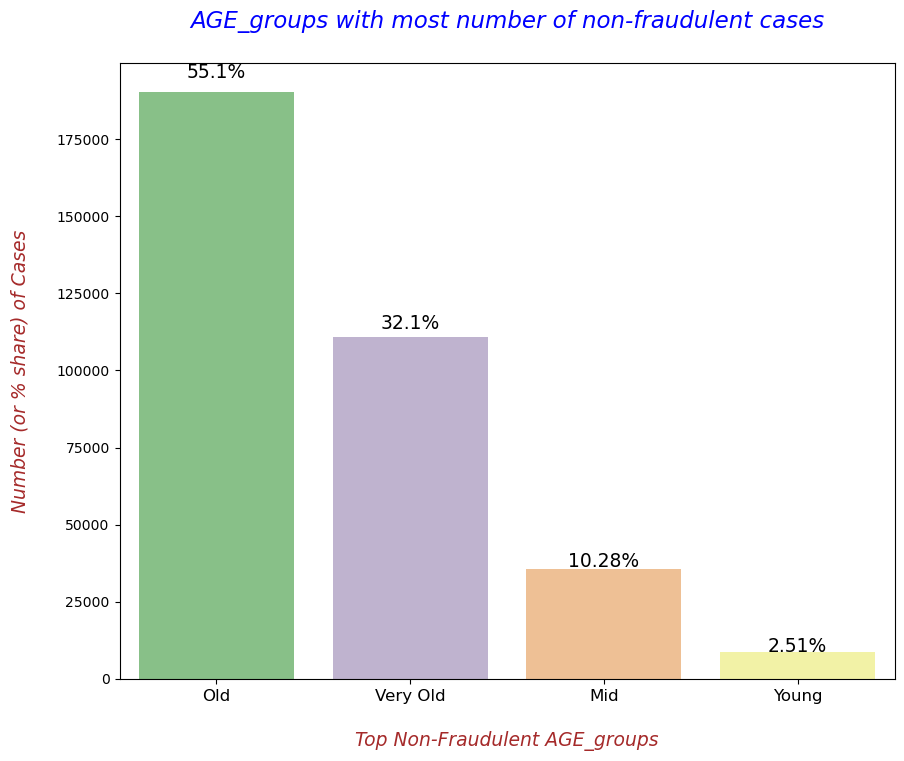

In [155]:
print(tmp_only_non_frauds[['AGE_groups','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(10,8))
fig = sns.barplot(data=tmp_only_non_frauds, x="AGE_groups", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_non_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=0)

plt.xlabel("\nTop Non-Fraudulent AGE_groups", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("AGE_groups with most number of non-fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**

* The above plot shows us the percentage of Non-Fraudulent Case Submissions for various Age Groups.

* Main observation from the above 2 plots is that same `Age Groups` have similar percentages for false and no-false claims. Therefore, it feels like this feature might not be very useful.

### **Q15. Which are the Top-25 `States` with maximum number of fraudulent cases?**

In [156]:
tmp = pd.DataFrame(train_iobp_df.groupby(['State','PotentialFraud'])['BeneID'].count()).reset_index()
tmp.columns = ['State', 'Fraud?', 'Num_of_cases']
tot_fraud_cases = tmp[tmp['Fraud?'] == 'Yes']['Num_of_cases'].sum()
tot_non_fraud_cases = tmp[tmp['Fraud?'] == 'No']['Num_of_cases'].sum()
tmp['Cases'] = tmp['Fraud?'].apply(lambda val: tot_non_fraud_cases if val == "No" else tot_fraud_cases)
tmp['Percentage'] = round(((tmp['Num_of_cases'] / tmp['Cases']) * 100),2)

tmp.head()

,State,Fraud?,Num_of_cases,Cases,Percentage
0,1,No,6715,345415,1.94
1,1,Yes,3525,212796,1.66
2,2,No,531,345415,0.15
3,2,Yes,207,212796,0.10
4,3,No,7314,345415,2.12


In [157]:
tmp_only_frauds = tmp[tmp['Fraud?'] == 'Yes'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

    State  Num_of_cases  Percentage
0       5         30335       14.26
1      10         17512        8.23
2      33         17492        8.22
3      39         11448        5.38
4      45         10135        4.76
5      31          9112        4.28
6      49          8613        4.05
7      23          8538        4.01
8      14          8509        4.00
9      22          7798        3.66
10     44          6709        3.15
11     36          6381        3.00
12     26          5301        2.49
13     50          4782        2.25
14     15          4635        2.18
15     34          4385        2.06
16     11          4123        1.94
17      6          3666        1.72
18      1          3525        1.66
19     24          3453        1.62
20     42          3180        1.49
21     16          2733        1.28
22     21          2576        1.21
23     46          2124        1.00
24      3          2030        0.95 



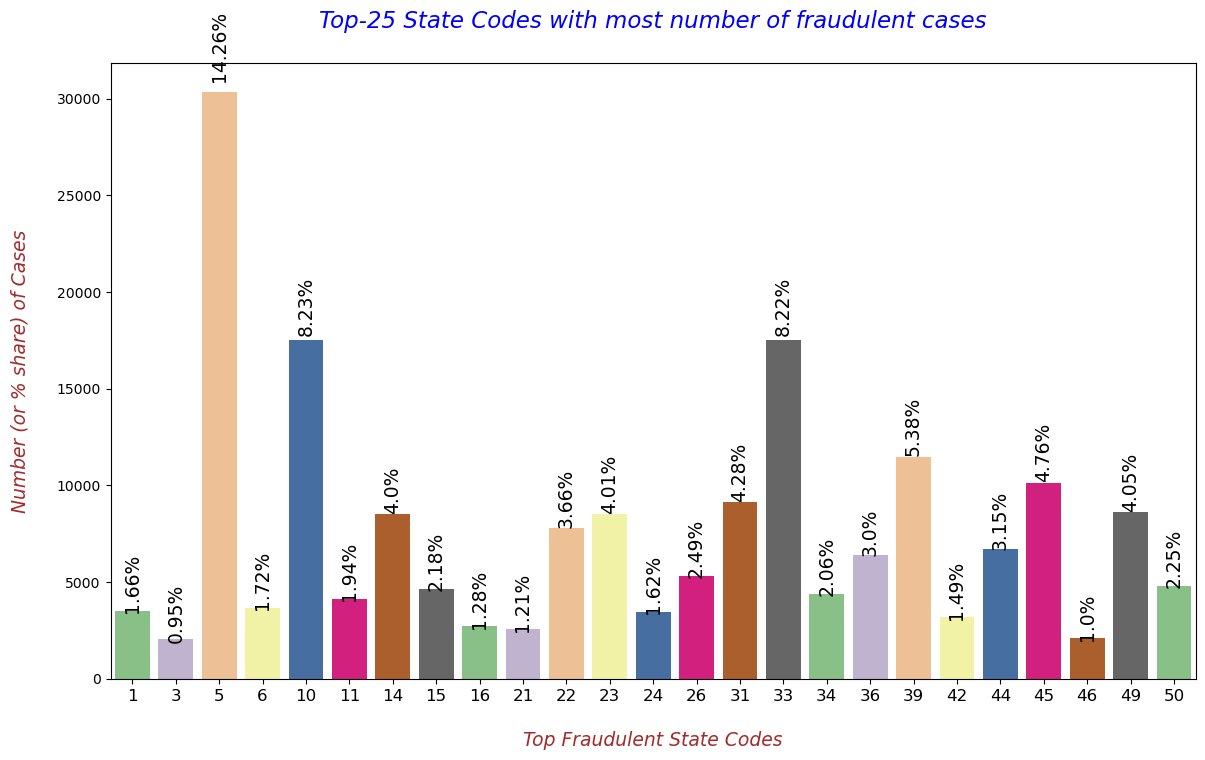

In [158]:
print(tmp_only_frauds[['State','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(14,8))
fig = sns.barplot(data=tmp_only_frauds.iloc[0:25], x="State", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nTop Fraudulent State Codes", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Top-25 State Codes with most number of fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot shows us the Top-25 State Codes with most percentage of Fraudulent Case Submissions.

### **Q16. What are the Top-25 `States` with maximum number of non-fraudulent cases?**

In [159]:
tmp_only_non_frauds = tmp[tmp['Fraud?'] == 'No'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

    State  Num_of_cases  Percentage
0      45         23887        6.92
1      10         21561        6.24
2       5         21015        6.08
3      33         17532        5.08
4      14         15908        4.61
5      36         14910        4.32
6      34         14520        4.20
7      11         12880        3.73
8      39         12803        3.71
9      23         12805        3.71
10     15          9578        2.77
11     21          8685        2.51
12     18          8643        2.50
13     52          7839        2.27
14     44          7709        2.23
15     26          7610        2.20
16     42          7311        2.12
17      3          7314        2.12
18     50          6958        2.01
19     31          6828        1.98
20      1          6715        1.94
21     49          6384        1.85
22     19          6230        1.80
23     25          5863        1.70
24     22          5826        1.69 



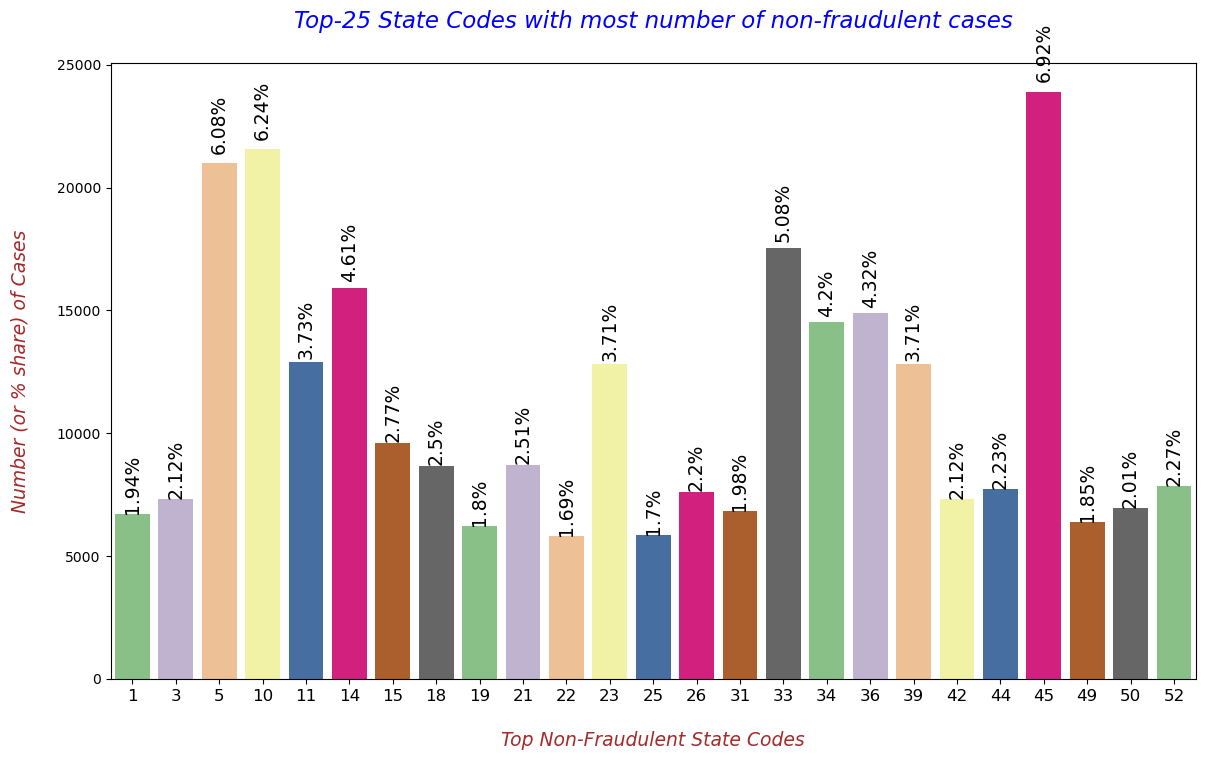

In [160]:
print(tmp_only_non_frauds[['State','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(14,8))
fig = sns.barplot(data=tmp_only_non_frauds.iloc[0:25], x="State", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_non_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nTop Non-Fraudulent State Codes", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Top-25 State Codes with most number of non-fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**

* The above plot shows us the Top-25 State Codes with most percentage of Non-Fraudulent Case Submissions.

* Main observation from the above 2 plots is that same `State Codes` have similar percentages for false and no-false claims. Therefore, it feels like this feature might not be very useful.

### **Q17. Which are the Top-25 `Country` with maximum number of fraudulent cases?**

In [161]:
tmp = pd.DataFrame(train_iobp_df.groupby(['County','PotentialFraud'])['BeneID'].count()).reset_index()
tmp.columns = ['County', 'Fraud?', 'Num_of_cases']
tot_fraud_cases = tmp[tmp['Fraud?'] == 'Yes']['Num_of_cases'].sum()
tot_non_fraud_cases = tmp[tmp['Fraud?'] == 'No']['Num_of_cases'].sum()
tmp['Cases'] = tmp['Fraud?'].apply(lambda val: tot_non_fraud_cases if val == "No" else tot_fraud_cases)
tmp['Percentage'] = round(((tmp['Num_of_cases'] / tmp['Cases']) * 100),2)

tmp.head()

,County,Fraud?,Num_of_cases,Cases,Percentage
0,0,No,6584,345415,1.91
1,0,Yes,4897,212796,2.30
2,1,No,8,345415,0.00
3,1,Yes,4,212796,0.00
4,10,No,10750,345415,3.11


In [162]:
tmp_only_frauds = tmp[tmp['Fraud?'] == 'Yes'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

    County  Num_of_cases  Percentage
0      200         10078        4.74
1      470          7048        3.31
2      400          5962        2.80
3      590          5814        2.73
4        0          4897        2.30
5      160          4865        2.29
6      620          4704        2.21
7      130          4551        2.14
8      490          4477        2.10
9      170          4362        2.05
10     440          4314        2.03
11      20          4174        1.96
12      90          4079        1.92
13     150          3844        1.81
14     290          3725        1.75
15     510          3505        1.65
16     310          3437        1.62
17     390          3387        1.59
18     331          3284        1.54
19      10          3232        1.52
20     141          3202        1.50
21      60          3181        1.49
22     700          3020        1.42
23     250          2999        1.41
24     530          2871        1.35 



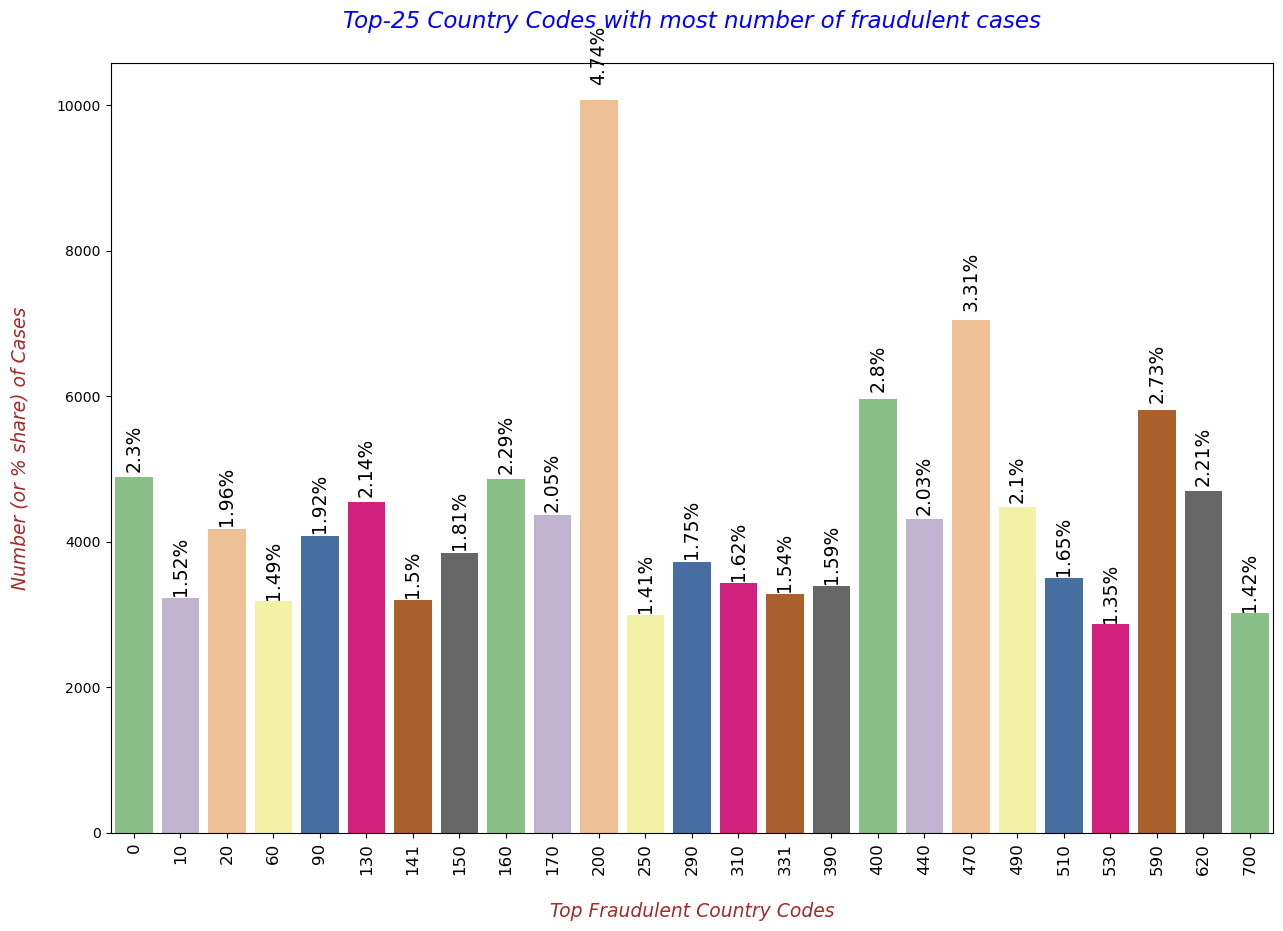

In [163]:
print(tmp_only_frauds[['County','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(15,10))
fig = sns.barplot(data=tmp_only_frauds.iloc[0:25], x="County", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nTop Fraudulent Country Codes", fontdict=label_font_dict)
plt.xticks(rotation=90, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Top-25 Country Codes with most number of fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot shows us the Top-25 Country Codes with most percentage of Fraudulent Case Submissions.

### **Q18. What are the Top-25 `Country` with maximum number of non-fraudulent cases?**

In [164]:
tmp_only_non_frauds = tmp[tmp['Fraud?'] == 'No'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

    County  Num_of_cases  Percentage
0       10         10750        3.11
1       60          8814        2.55
2       20          8458        2.45
3       90          7007        2.03
4        0          6584        1.91
5      200          5879        1.70
6      150          5843        1.69
7      141          5793        1.68
8      400          5735        1.66
9      160          5668        1.64
10     310          5590        1.62
11      70          5487        1.59
12      50          5430        1.57
13     250          5385        1.56
14      40          5276        1.53
15     470          5230        1.51
16     480          5229        1.51
17     490          5010        1.45
18     100          4995        1.45
19     120          4936        1.43
20     240          4887        1.41
21     550          4513        1.31
22      30          4491        1.30
23     290          4417        1.28
24     390          4428        1.28 



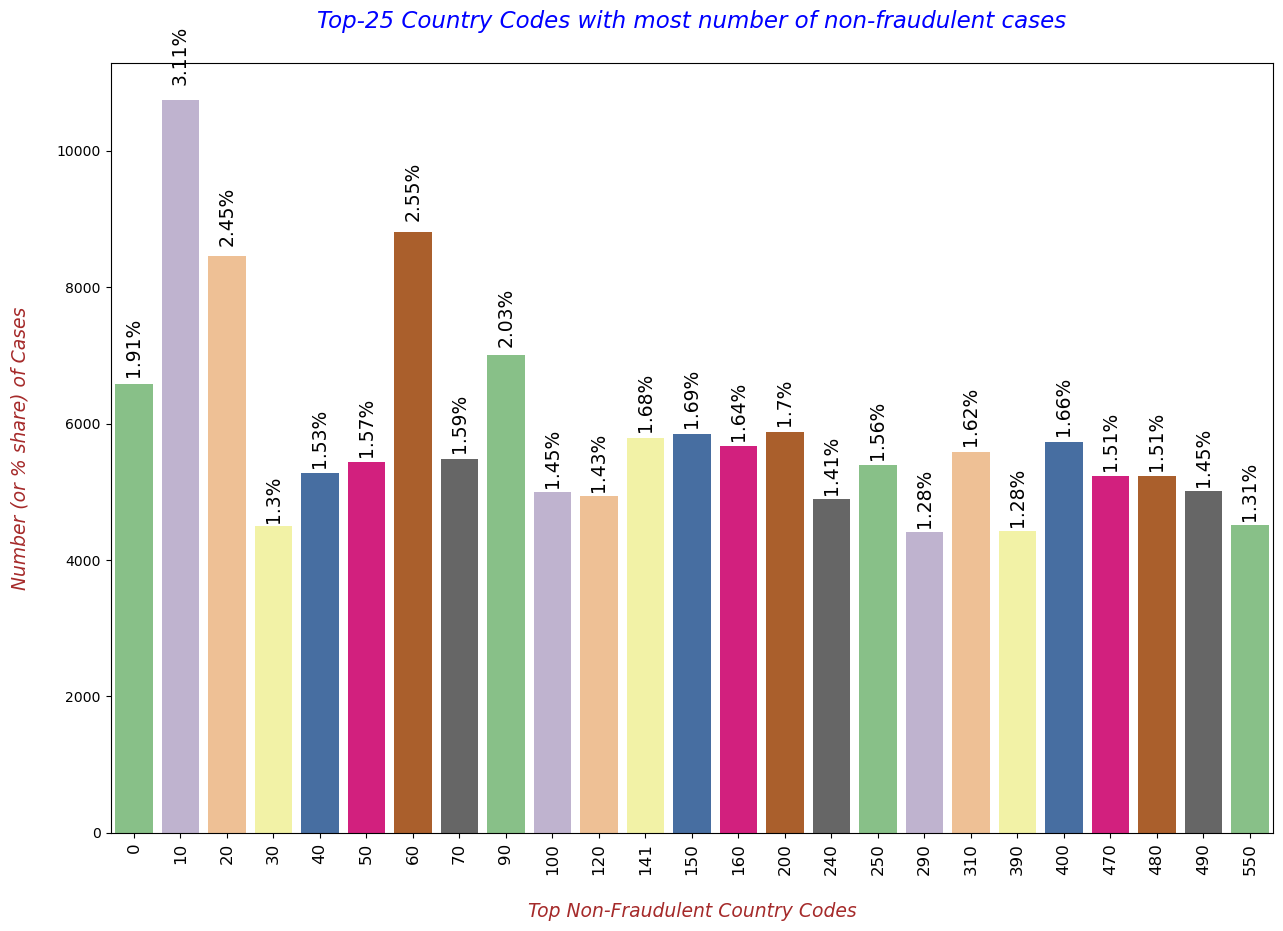

In [165]:
print(tmp_only_non_frauds[['County','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(15,10))
fig = sns.barplot(data=tmp_only_non_frauds.iloc[0:25], x="County", y="Num_of_cases", palette='Accent')

for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_non_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=90)

plt.xlabel("\nTop Non-Fraudulent Country Codes", fontdict=label_font_dict)
plt.xticks(rotation=90, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Top-25 Country Codes with most number of non-fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**

* The above plot shows us the Top-25 Country Codes with most percentage of Non-Fraudulent Case Submissions.

* Main observation from the above 2 plots is that same `Country Codes` have similar percentages for false and no-false claims. Therefore, it feels like this feature might not be very useful.

### **Q19. Does various `Human Races` have any relationship with maximum number of fraudulent cases?**

In [166]:
tmp = pd.DataFrame(train_iobp_df.groupby(['Race','PotentialFraud'])['BeneID'].count()).reset_index()
tmp.columns = ['Race', 'Fraud?', 'Num_of_cases']
tot_fraud_cases = tmp[tmp['Fraud?'] == 'Yes']['Num_of_cases'].sum()
tot_non_fraud_cases = tmp[tmp['Fraud?'] == 'No']['Num_of_cases'].sum()
tmp['Cases'] = tmp['Fraud?'].apply(lambda val: tot_non_fraud_cases if val == "No" else tot_fraud_cases)
tmp['Percentage'] = round(((tmp['Num_of_cases'] / tmp['Cases']) * 100),2)

tmp.head()

,Race,Fraud?,Num_of_cases,Cases,Percentage
0,1,No,292691,345415,84.74
1,1,Yes,178345,212796,83.81
2,2,No,35356,345415,10.24
3,2,Yes,20284,212796,9.53
4,3,No,10753,345415,3.11


In [167]:
tmp_only_frauds = tmp[tmp['Fraud?'] == 'Yes'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

   Race  Num_of_cases  Percentage
0     1        178345       83.81
1     2         20284        9.53
2     3          8962        4.21
3     5          5205        2.45 



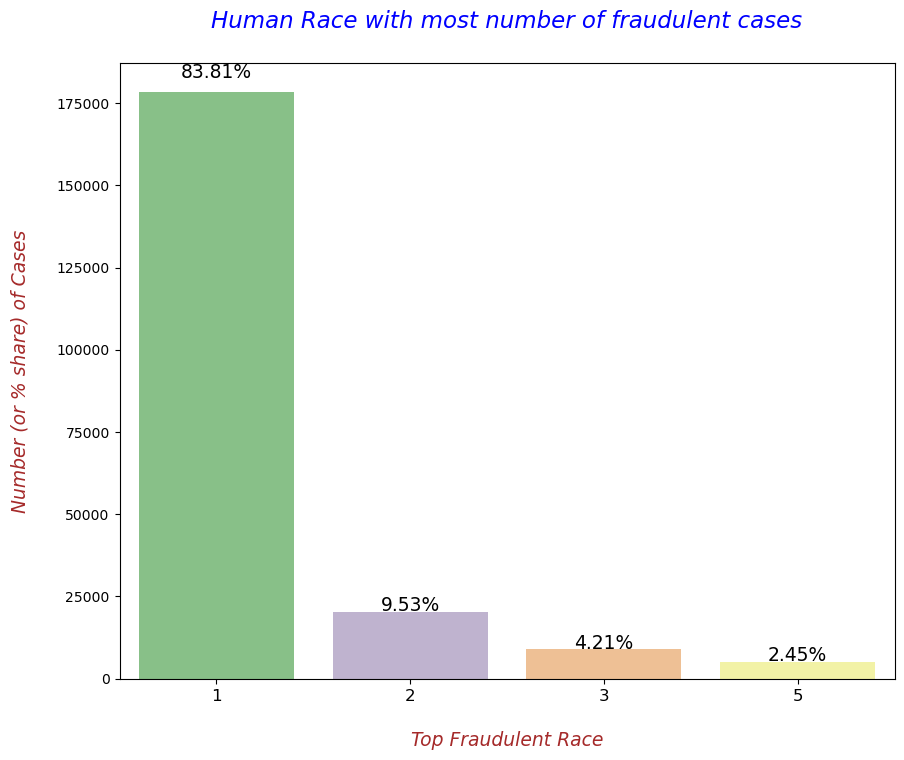

In [168]:
print(tmp_only_frauds[['Race','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(10,8))
fig = sns.barplot(data=tmp_only_frauds, x="Race", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=0)

plt.xlabel("\nTop Fraudulent Race", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Human Race with most number of fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**
* The above plot shows us the percentage of Fraudulent Case Submissions for various Human Races.

### **Q20. Does various `Human Races` have any relationship with maximum number of non-fraudulent cases?**

In [169]:
tmp_only_non_frauds = tmp[tmp['Fraud?'] == 'No'].sort_values(by=['Percentage'], ascending=False).reset_index(drop=True)

   Race  Num_of_cases  Percentage
0     1        292691       84.74
1     2         35356       10.24
2     3         10753        3.11
3     5          6615        1.92 



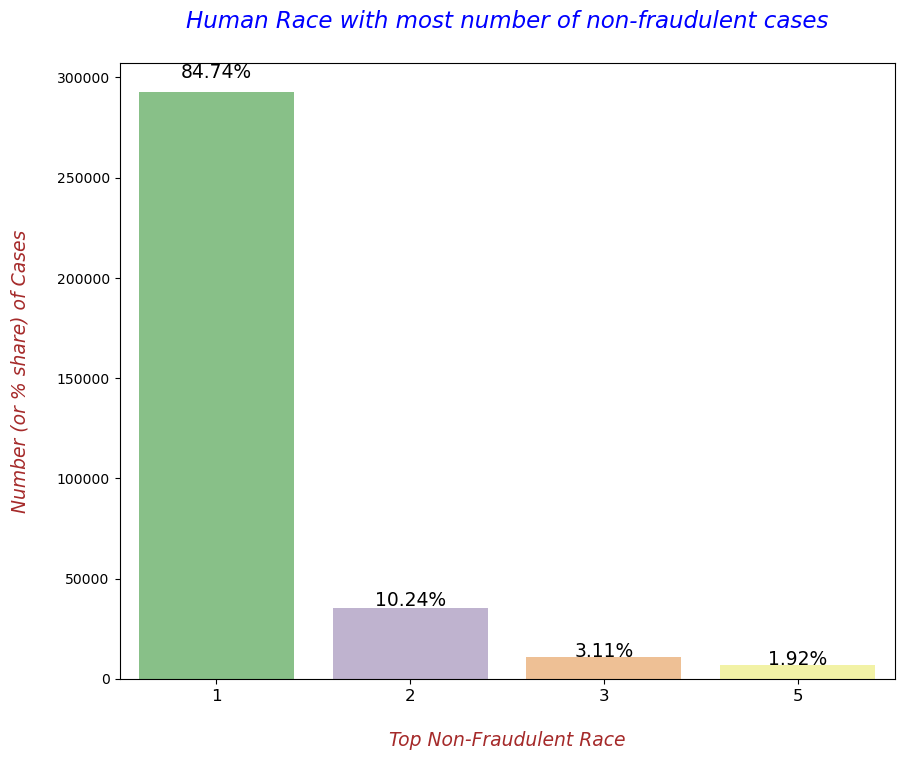

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

...

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

In [170]:
print(tmp_only_non_frauds[['Race','Num_of_cases','Percentage']].head(25), "\n")

plt.figure(figsize=(10,8))
fig = sns.barplot(data=tmp_only_non_frauds, x="Race", y="Num_of_cases", palette='Accent')
for p in fig.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    fig.annotate(f'{str(round((height*100)/tot_non_fraud_cases,2))+"%"}', (x + width/2, y + height*1.025), ha='center', fontsize=13.5, rotation=0)

plt.xlabel("\nTop Non-Fraudulent Race", fontdict=label_font_dict)
plt.xticks(rotation=0, fontsize=12)
plt.ylabel("Number (or % share) of Cases\n", fontdict=label_font_dict)
plt.title("Human Race with most number of non-fraudulent cases\n", fontdict=title_font_dict)
plt.show()

**`OBSERVATION`**

* The above plot shows us the percentage of Non-Fraudulent Case Submissions for various Human Races.

* Main observation from the above 2 plots is that same `Human Races` have similar percentages for false and no-false claims. Therefore, it feels like this feature might not be very useful.